# APRAU Project — Group 17

Revised analysis with executed diagnostics and explicit training-CV selection.

## 1. Objectives and Organisation

This project analyses a dataset of 2,000 patients and 35 columns with two objectives: predicting the continuous target `target_regression` and classifying patients as DI, HT_HY, or DI_HT_HY using `target_class`. Neither target is used to predict the other.

The analysis includes:

- Exploratory data analysis (EDA) and preprocessing
- Simple and multiple linear regression
- Logistic regression and LDA
- Resampling and class weighting
- Regularisation and feature selection
- Test-set evaluation and discussion of limitations


### Reproduction instructions and revision scope

Authors: Francisco Primavera (1230840) and Pedro Fonseca (1220947).

Open `projeto_revisto.ipynb` from the repository folder with `dataset_grupo_17.csv` alongside it.
Install the versions in `requirements_projeto_revisto.txt`, select that Python environment in Jupyter,
then use **Restart Kernel and Run All Cells**.

```text
python -m pip install -r requirements_projeto_revisto.txt
python -m jupyterlab projeto_revisto.ipynb
```

Runtime versions and the dataset fingerprint are recorded below. Execution reads the dataset
without rewriting inputs. LOOCV and repeated regularisation fits account for most execution time.

This revision retains the original patients, split, seeds, regression models, LDA and resampling methods.
It adds training diagnostics, a four-value L1-selector comparison and consolidated comparisons.
Configuration selection uses training CV; the historically consulted test remains exploratory.
`projeto.ipynb`, the Word report and `report_materials.md` retain the original analysis.
Section 9 contains the references for this revised version; `ALTERACOES_projeto_revisto.md` records the differences.


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, KFold, RepeatedStratifiedKFold, LeaveOneOut
from sklearn.linear_model import LinearRegression, LogisticRegression, Ridge, Lasso, ElasticNet
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error, accuracy_score, confusion_matrix, classification_report
from sklearn.dummy import DummyClassifier
RANDOM_STATE = 42
CLASS_ORDER = ['DI', 'HT_HY', 'DI_HT_HY']
sns.set_theme(style='whitegrid')
pd.set_option('display.max_columns', 20)

In [2]:
from IPython.display import Markdown, display
import hashlib
import importlib.metadata
import platform

runtime_versions = pd.Series(
    {
        "Python": platform.python_version(),
        **{
            p: importlib.metadata.version(p)
            for p in [
                "numpy",
                "pandas",
                "scipy",
                "matplotlib",
                "seaborn",
                "scikit-learn",
                "ipython",
            ]
        },
    },
    name="Executed version",
)
display(runtime_versions)


Python          3.13.9
numpy            2.3.5
pandas           2.3.3
scipy           1.16.3
matplotlib      3.10.6
seaborn         0.13.2
scikit-learn     1.7.2
ipython          9.7.0
Name: Executed version, dtype: object

In [3]:
dataset_path = Path('dataset_grupo_17.csv')
if not dataset_path.exists():
    dataset_path = Path('projeto/dataset_grupo_17.csv')
df = pd.read_csv(dataset_path)
assert df.shape == (2000, 35)

In [4]:
dataset_sha256 = hashlib.sha256(dataset_path.read_bytes()).hexdigest()
print("Input dataset SHA-256:", dataset_sha256)


Input dataset SHA-256: 0a902346e368d67af7323154d94b5db400696fe37f5fd93ba55119a8976d8ff3


In [5]:
df.shape

(2000, 35)

In [6]:
df.head()

,age_level,gender,bmi_level,smoking,age,age_normalized,bmi,HbA1c_level,cholesterol,sleep_hours,...,hdl,ldl,education_level,employment_status,systolic_index,calcium_baseline,plasma_value,ldl_alternative,target_regression,target_class
0,Young,Male,Underweight,Former,22,0.229885,15.500000,7.150000,281.0,9.200000,...,52.00000,91.000000,Tertiary,Retired,111.000000,9.42,0.999607,185.0,194.0,DI
1,Mature,Male,Overweight,Never,62,0.689655,27.400000,6.997222,254.0,5.200000,...,63.00000,189.000000,Tertiary,Employed,112.000000,9.42,1.334483,79.0,148.0,DI
2,Mature,Female,Obese,Current,59,0.655172,30.400000,7.066929,195.0,5.200000,...,87.00000,115.000000,Tertiary,Employed,122.000000,9.42,1.313058,112.0,133.0,DI
3,Young,Male,Overweight,Never,18,0.183908,28.400000,6.876190,160.0,6.800000,...,72.00000,146.000000,Tertiary,Employed,179.000000,9.42,1.009796,148.0,141.0,DI
4,Middle,Female,Normal,Never,28,0.298851,19.481258,5.396140,172.0,7.084828,...,64.64414,130.244654,Tertiary,Unemployed,135.590248,9.42,1.344851,130.0,94.0,HT_HY


In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 35 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   age_level             2000 non-null   object 
 1   gender                2000 non-null   object 
 2   bmi_level             2000 non-null   object 
 3   smoking               2000 non-null   object 
 4   age                   2000 non-null   int64  
 5   age_normalized        2000 non-null   float64
 6   bmi                   2000 non-null   float64
 7   HbA1c_level           2000 non-null   float64
 8   cholesterol           2000 non-null   float64
 9   sleep_hours           2000 non-null   float64
 10  triglycerides         2000 non-null   float64
 11  physical_activity     2000 non-null   object 
 12  family_history        2000 non-null   object 
 13  stress_level          2000 non-null   object 
 14  low_hdl_cholesterol   2000 non-null   object 
 15  high_ldl_cholesterol 

## 2. Exploratory Data Analysis (EDA)

### 2.1 Data Inspection and Quality

In [8]:
# testar se há espaços no início ou no fim das variáveis de texto

text_cols = df.select_dtypes(include=["object", "string"]).columns

text_cols

for col in text_cols:
    original = df[col].astype("string")
    sem_espacos = original.str.strip()

    alterados = (original != sem_espacos).sum()

    if alterados > 0:
        print(col, alterados)

In [9]:
# verificar valores em falta

missing_values = df.isna().sum()

missing_values[missing_values > 0]

Series([], dtype: int64)

In [10]:
# verificar linhas duplicadas

df.duplicated().sum()

np.int64(0)

In [11]:
unique_counts = df.nunique(dropna=False).sort_values()

unique_counts

calcium_baseline           1
gender                     2
high_ldl_cholesterol       2
low_hdl_cholesterol        2
family_history             2
sugar_consumption          3
employment_status          3
education_level            3
stress_level               3
physical_activity          3
target_class               3
smoking                    3
age_level                  4
bmi_level                  4
age                       77
HbA1c_level              121
target_regression        136
age_normalized           140
blood_pressure           150
heart_rate               160
diastolic_bp             170
hdl                      180
systolic_bp              200
systolic_index           200
cholesterol              224
ldl_alternative          230
ldl                      230
salt_intake              241
crp_level                299
homocysteine_level       300
sleep_hours              344
triglycerides            350
alcohol_intake           406
bmi                      750
plasma_value  

- `calcium_baseline` is constant across all observations and provides no variation for prediction.
- `plasma_value` is unique for each patient. This may reflect measurement precision rather than an identifier; its predictive contribution is assessed later.


In [12]:
df["calcium_baseline"].value_counts(dropna=False)

calcium_baseline
9.42    2000
Name: count, dtype: int64

### 2.2 Descriptive Statistics

In [13]:
# estatísticas descritivas das variáveis numéricas

numeric_cols = df.select_dtypes(include="number").columns

numeric_summary = df[numeric_cols].describe().T
numeric_summary

,count,mean,std,min,25%,50%,75%,max
age,2000.0,54.844500,1.957013e+01,9.000000,39.000000,56.000000,71.000000,89.000000
age_normalized,2000.0,0.607408,2.249440e-01,0.080460,0.425287,0.620690,0.793103,1.000000
bmi,2000.0,28.452768,7.445437e+00,11.950000,22.500000,28.410000,34.073214,81.730000
HbA1c_level,2000.0,6.866944,6.661678e-01,3.500000,6.800000,6.902539,7.046053,9.000000
cholesterol,2000.0,225.882239,3.750963e+01,150.000000,200.000000,225.409524,254.000000,299.000000
sleep_hours,2000.0,6.948641,1.540056e+00,4.000000,5.800000,6.995238,8.000000,10.000000
triglycerides,2000.0,174.579467,6.896231e+01,50.000000,122.000000,172.000000,232.563187,400.000000
blood_pressure,2000.0,150.086493,6.266135e+00,120.000000,149.028736,149.974007,151.354497,179.000000
crp_level,2000.0,7.415973,1.469688e+00,0.083089,7.276693,7.458483,7.706331,14.996625
homocysteine_level,2000.0,12.427848,1.490708e+00,5.024728,12.252650,12.416838,12.681166,19.965810


In [14]:
# Igualdade por observação versus igualdade dos valores ordenados.
redundancy_checks = pd.Series({
    'systolic_bp e systolic_index: valores iguais':
        df['systolic_bp'].equals(df['systolic_index']),
    'ldl e ldl_alternative: valores iguais':
        df['ldl'].equals(df['ldl_alternative']),
    'ldl e ldl_alternative: mesmos valores, ignorando a ordem':
        np.array_equal(np.sort(df['ldl']), np.sort(df['ldl_alternative']))
}, name='Resultado')
redundancy_checks


systolic_bp e systolic_index: valores iguais                 True
ldl e ldl_alternative: valores iguais                       False
ldl e ldl_alternative: mesmos valores, ignorando a ordem     True
Name: Resultado, dtype: bool

`systolic_index` exactly matches `systolic_bp` and is therefore redundant.

`ldl_alternative` has the same sorted values as `ldl`, but they are assigned to different patients, with almost no correlation between the columns. This is consistent with a permutation but does not establish how the variable was constructed. It is not a patient-level copy; its contribution will be assessed through associations with the targets and model comparisons.

In [15]:
categorical_cols = df.select_dtypes(include=["object", "string"]).columns

for col in categorical_cols:
    print(f"\n--- {col} ---")
    print(df[col].value_counts(dropna=False))


--- age_level ---
age_level
Mature    712
Senior    613
Middle    547
Young     128
Name: count, dtype: int64

--- gender ---
gender
Female    1018
Male       982
Name: count, dtype: int64

--- bmi_level ---
bmi_level
Obese          874
Normal         480
Overweight     450
Underweight    196
Name: count, dtype: int64

--- smoking ---
smoking
Never      730
Former     641
Current    629
Name: count, dtype: int64

--- physical_activity ---
physical_activity
High        806
Moderate    601
Low         593
Name: count, dtype: int64

--- family_history ---
family_history
No     1058
Yes     942
Name: count, dtype: int64

--- stress_level ---
stress_level
High      684
Medium    668
Low       648
Name: count, dtype: int64

--- low_hdl_cholesterol ---
low_hdl_cholesterol
No     1588
Yes     412
Name: count, dtype: int64

--- high_ldl_cholesterol ---
high_ldl_cholesterol
Yes    1095
No      905
Name: count, dtype: int64

--- sugar_consumption ---
sugar_consumption
Low       752
High      644

- No unexpected categories or spelling inconsistencies were identified.

- Most categorical features are relatively balanced. The main exceptions are `age_level`, where `Young` is less frequent, and `bmi_level`, where `Obese` is the most frequent category.

- `target_class` is highly imbalanced: `DI` accounts for 90.05% of cases, compared with 5.25% for `HT_HY` and 4.70% for `DI_HT_HY`. Accuracy should therefore not be used alone to assess classification performance.

In [16]:
df.groupby("age_level")["age"].agg(
    ["count", "min", "max", "mean"]
).sort_values("min")

,count,min,max,mean
age_level,,,,
Young,128,9,23,20.054688
Middle,547,24,45,34.778793
Mature,712,46,67,56.900281
Senior,613,68,89,77.626427


In [17]:
df.groupby("bmi_level")["bmi"].agg(
    ["count", "min", "max", "mean"]
).sort_values("min")

,count,min,max,mean
bmi_level,,,,
Underweight,196,11.95,18.481480,16.685863
Normal,480,18.50,24.993197,21.751350
Overweight,450,25.00,29.980000,27.468734
Obese,874,30.00,81.730000,35.278636


- `age_level` categorises `age` into the observed ranges 9–23 (`Young`), 24–45 (`Middle`), 46–67 (`Mature`), and 68–89 (`Senior`). These are dataset-specific ranges, not universal clinical categories.

- `bmi_level` categorises `bmi` using thresholds consistent with the Underweight, Normal, Overweight, and Obese categories provided in the exercise.

- These numerical and categorical variables represent related information differently: numerical values retain exact measurements, whereas categories group values into intervals and discard within-group differences. Their joint use will be evaluated during modelling.

In [18]:
df.groupby("low_hdl_cholesterol")["hdl"].agg(
    ["count", "min", "max", "mean"]
)

,count,min,max,mean
low_hdl_cholesterol,,,,
No,1588,40.0,99.000000,68.081368
Yes,412,30.0,65.795482,50.386520


In [19]:
df.groupby("high_ldl_cholesterol")["ldl"].agg(
    ["count", "min", "max", "mean"]
)

,count,min,max,mean
high_ldl_cholesterol,,,,
No,905,70.000000,132.65,106.380661
Yes,1095,126.743655,189.00,148.829789


- Patients with `low_hdl_cholesterol = Yes` have lower mean HDL values than the remaining patients. However, the groups overlap, so the indicator does not correspond to a perfect separation at a single HDL threshold.

- Patients with `high_ldl_cholesterol = Yes` have higher mean LDL values, although the groups also overlap.

- These indicators are closely related to `hdl` and `ldl`, respectively, but are not exact copies. Their potential redundancy will be assessed during modelling.

### 2.2.1 Blood Pressure and Lipid Consistency

These checks assess consistency between related measurements. Auxiliary variables are kept separately and are not used as model features.

Pulse pressure is the difference between systolic and diastolic pressure. Mean arterial pressure is approximated by:

$$
\mathrm{MAP} \approx \frac{\mathrm{systolic} + 2\,\mathrm{diastolic}}{3}
$$

The dataset description does not confirm whether `blood_pressure` represents this quantity or comes from the same measurement.

Non-HDL cholesterol is calculated as `cholesterol - hdl`. With comparable units and measurements, total cholesterol is expected to be at least HDL + LDL, allowing for analytical uncertainty. The Friedewald approximation, in mg/dL, is:

$$
\mathrm{LDL} \approx \mathrm{total\ cholesterol} - \mathrm{HDL} - \frac{\mathrm{triglycerides}}{5}
$$

The classical formula is unsuitable for triglycerides ≥ 400 mg/dL. As the dataset's units and measurement methods are unknown, these checks identify potential inconsistencies rather than establish rules for correcting or removing observations.In the conditional mg/dL calculation below, the auxiliary estimate is marked missing where
triglycerides are at least 400. The original values and every patient remain in the modelling
dataset. This cutoff does not confirm the units or satisfy all clinical requirements of the formula.


Friedewald eligible pairs: 1999
Auxiliary estimates not calculated (TG >= 400): 1


,Registos,Percentagem (%)
Pressões invertidas,114,5.70
Pressões iguais,7,0.35
Pressão agregada fora dos limites (apenas pressões ordenadas),1405,70.25
Total inferior ao LDL,51,2.55
Total inferior ao HDL,0,0.00
Total inferior a HDL + LDL,469,23.45


,Variável A,Variável B,N_pairs,Pearson,Spearman
0,systolic_bp,diastolic_bp,2000,-0.0357,-0.0262
1,map_estimated,blood_pressure,2000,-0.0213,-0.0427
2,ldl_friedewald,ldl,1999,0.0030,0.0086
3,non_hdl_cholesterol,ldl,2000,-0.0040,0.0012
4,non_hdl_cholesterol,triglycerides,2000,-0.0231,-0.0192


,count,mean,std,min,25%,50%,75%,max
pulse_pressure,2000.0,45.019808,26.131921,-26.000000,33.000000,45.138732,57.000000,118.000000
map_estimated,2000.0,104.345937,11.711486,70.666667,99.583333,104.482784,109.666667,138.333333
non_hdl_cholesterol,2000.0,161.446009,40.904547,52.000000,135.000000,161.330109,188.000000,264.000000
ldl_friedewald,1999.0,126.588121,43.402078,9.400000,102.400000,128.239391,155.400000,245.000000


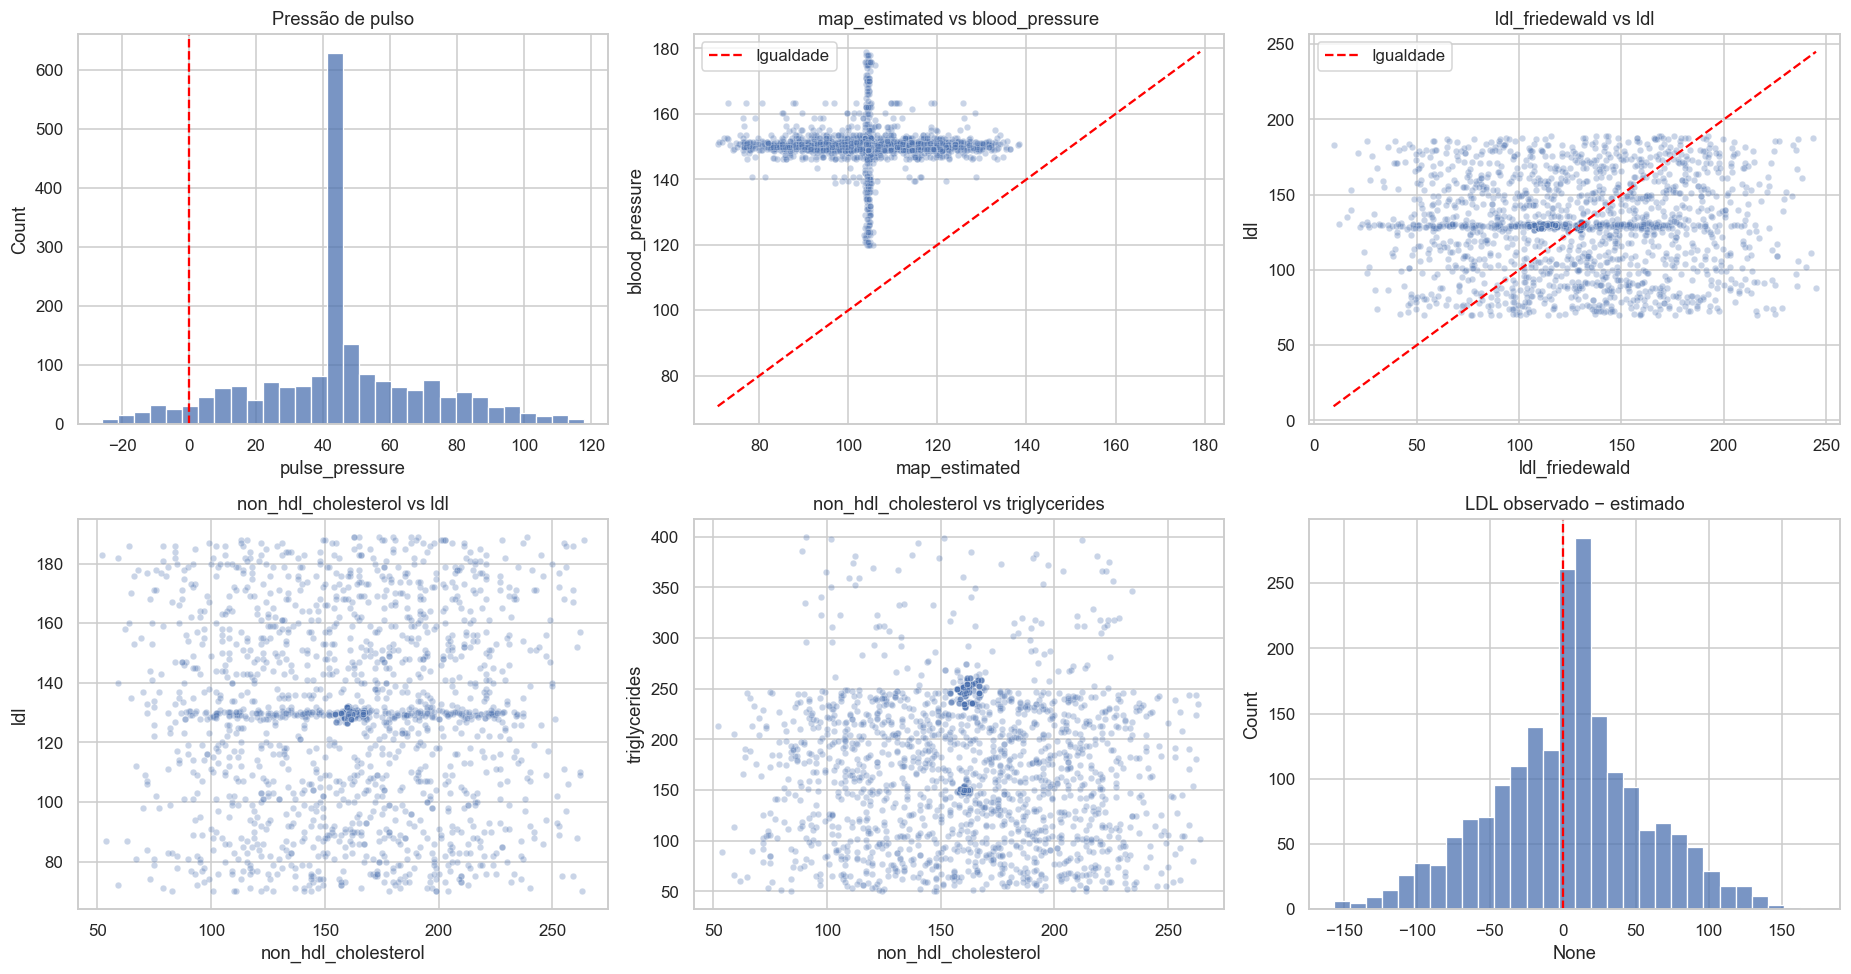

In [20]:
clinical_relations = df[
    ["systolic_bp", "diastolic_bp", "blood_pressure", "cholesterol", "hdl", "ldl", "triglycerides"]
].copy()
clinical_relations["pulse_pressure"] = df["systolic_bp"] - df["diastolic_bp"]
clinical_relations["map_estimated"] = (df["systolic_bp"] + 2 * df["diastolic_bp"]) / 3
clinical_relations["non_hdl_cholesterol"] = df["cholesterol"] - df["hdl"]
friedewald_eligible = df["triglycerides"] < 400
clinical_relations["ldl_friedewald"] = (
    df["cholesterol"] - df["hdl"] - df["triglycerides"] / 5
).where(friedewald_eligible)
print("Friedewald eligible pairs:", int(friedewald_eligible.sum()))
print("Auxiliary estimates not calculated (TG >= 400):", int((~friedewald_eligible).sum()))

# Alertas descritivos, não novas regras de exclusão.
clinical_alerts = pd.DataFrame(
    {
        "Pressões invertidas": df["systolic_bp"] < df["diastolic_bp"],
        "Pressões iguais": df["systolic_bp"] == df["diastolic_bp"],
        "Pressão agregada fora dos limites (apenas pressões ordenadas)": (
            df["systolic_bp"] >= df["diastolic_bp"]
        )
        & (
            (df["blood_pressure"] < df["diastolic_bp"]) | (df["blood_pressure"] > df["systolic_bp"])
        ),
        "Total inferior ao LDL": df["cholesterol"] < df["ldl"],
        "Total inferior ao HDL": df["cholesterol"] < df["hdl"],
        "Total inferior a HDL + LDL": df["cholesterol"] < df["hdl"] + df["ldl"],
    }
)
display(
    pd.DataFrame(
        {"Registos": clinical_alerts.sum(), "Percentagem (%)": clinical_alerts.mean() * 100}
    ).round(2)
)
pairs = [
    ("systolic_bp", "diastolic_bp"),
    ("map_estimated", "blood_pressure"),
    ("ldl_friedewald", "ldl"),
    ("non_hdl_cholesterol", "ldl"),
    ("non_hdl_cholesterol", "triglycerides"),
]
display(
    pd.DataFrame(
        [
            {
                "Variável A": a,
                "Variável B": b,
                "N_pairs": int(clinical_relations[[a, b]].dropna().shape[0]),
                "Pearson": clinical_relations[a].corr(clinical_relations[b]),
                "Spearman": clinical_relations[a].corr(clinical_relations[b], method="spearman"),
            }
            for a, b in pairs
        ]
    ).round(4)
)
display(
    clinical_relations[["pulse_pressure", "map_estimated", "non_hdl_cholesterol", "ldl_friedewald"]]
    .describe()
    .T
)

fig, axes = plt.subplots(2, 3, figsize=(17, 9))
sns.histplot(data=clinical_relations, x="pulse_pressure", bins=30, ax=axes[0, 0])
axes[0, 0].axvline(0, color="red", linestyle="--")
axes[0, 0].set_title("Pressão de pulso")
for ax, (a, b) in zip([axes[0, 1], axes[0, 2], axes[1, 0], axes[1, 1]], pairs[1:]):
    sns.scatterplot(data=clinical_relations, x=a, y=b, alpha=0.3, s=18, ax=ax)
    ax.set_title(f"{a} vs {b}")
    if a in ["map_estimated", "ldl_friedewald"]:
        lo = min(clinical_relations[a].min(), clinical_relations[b].min())
        hi = max(clinical_relations[a].max(), clinical_relations[b].max())
        ax.plot([lo, hi], [lo, hi], "--", color="red", label="Igualdade")
        ax.legend()
ldl_difference = clinical_relations["ldl"] - clinical_relations["ldl_friedewald"]
sns.histplot(x=ldl_difference, bins=30, ax=axes[1, 2])
axes[1, 2].axvline(0, color="red", linestyle="--")
axes[1, 2].set_title("LDL observado − estimado")
plt.tight_layout()
plt.show()


**Consistency Check Results**

- Systolic pressure is below diastolic pressure in 114 observations and equal in seven. Confirming errors requires knowing whether both refer to the same measurement.
- `blood_pressure` is almost uncorrelated with estimated mean arterial pressure (−0.021); its definition remains unclear.
- Total cholesterol is below HDL + LDL in 469 observations, including 51 where it is also below LDL. These counts overlap.
- Observed LDL and the conditional Friedewald estimate are almost uncorrelated (0.003), using 1,999 pairs. One auxiliary estimate is not calculated because TG equals 400; the patient remains in modelling.

These alerts do not establish measurement errors, as definitions, units, and methods are incomplete. No values are reconstructed or patients excluded: all models retain 1,600 training and 400 test patients. Derived variables are used only for consistency checks, not as model features.


### 2.3 Univariate Analysis


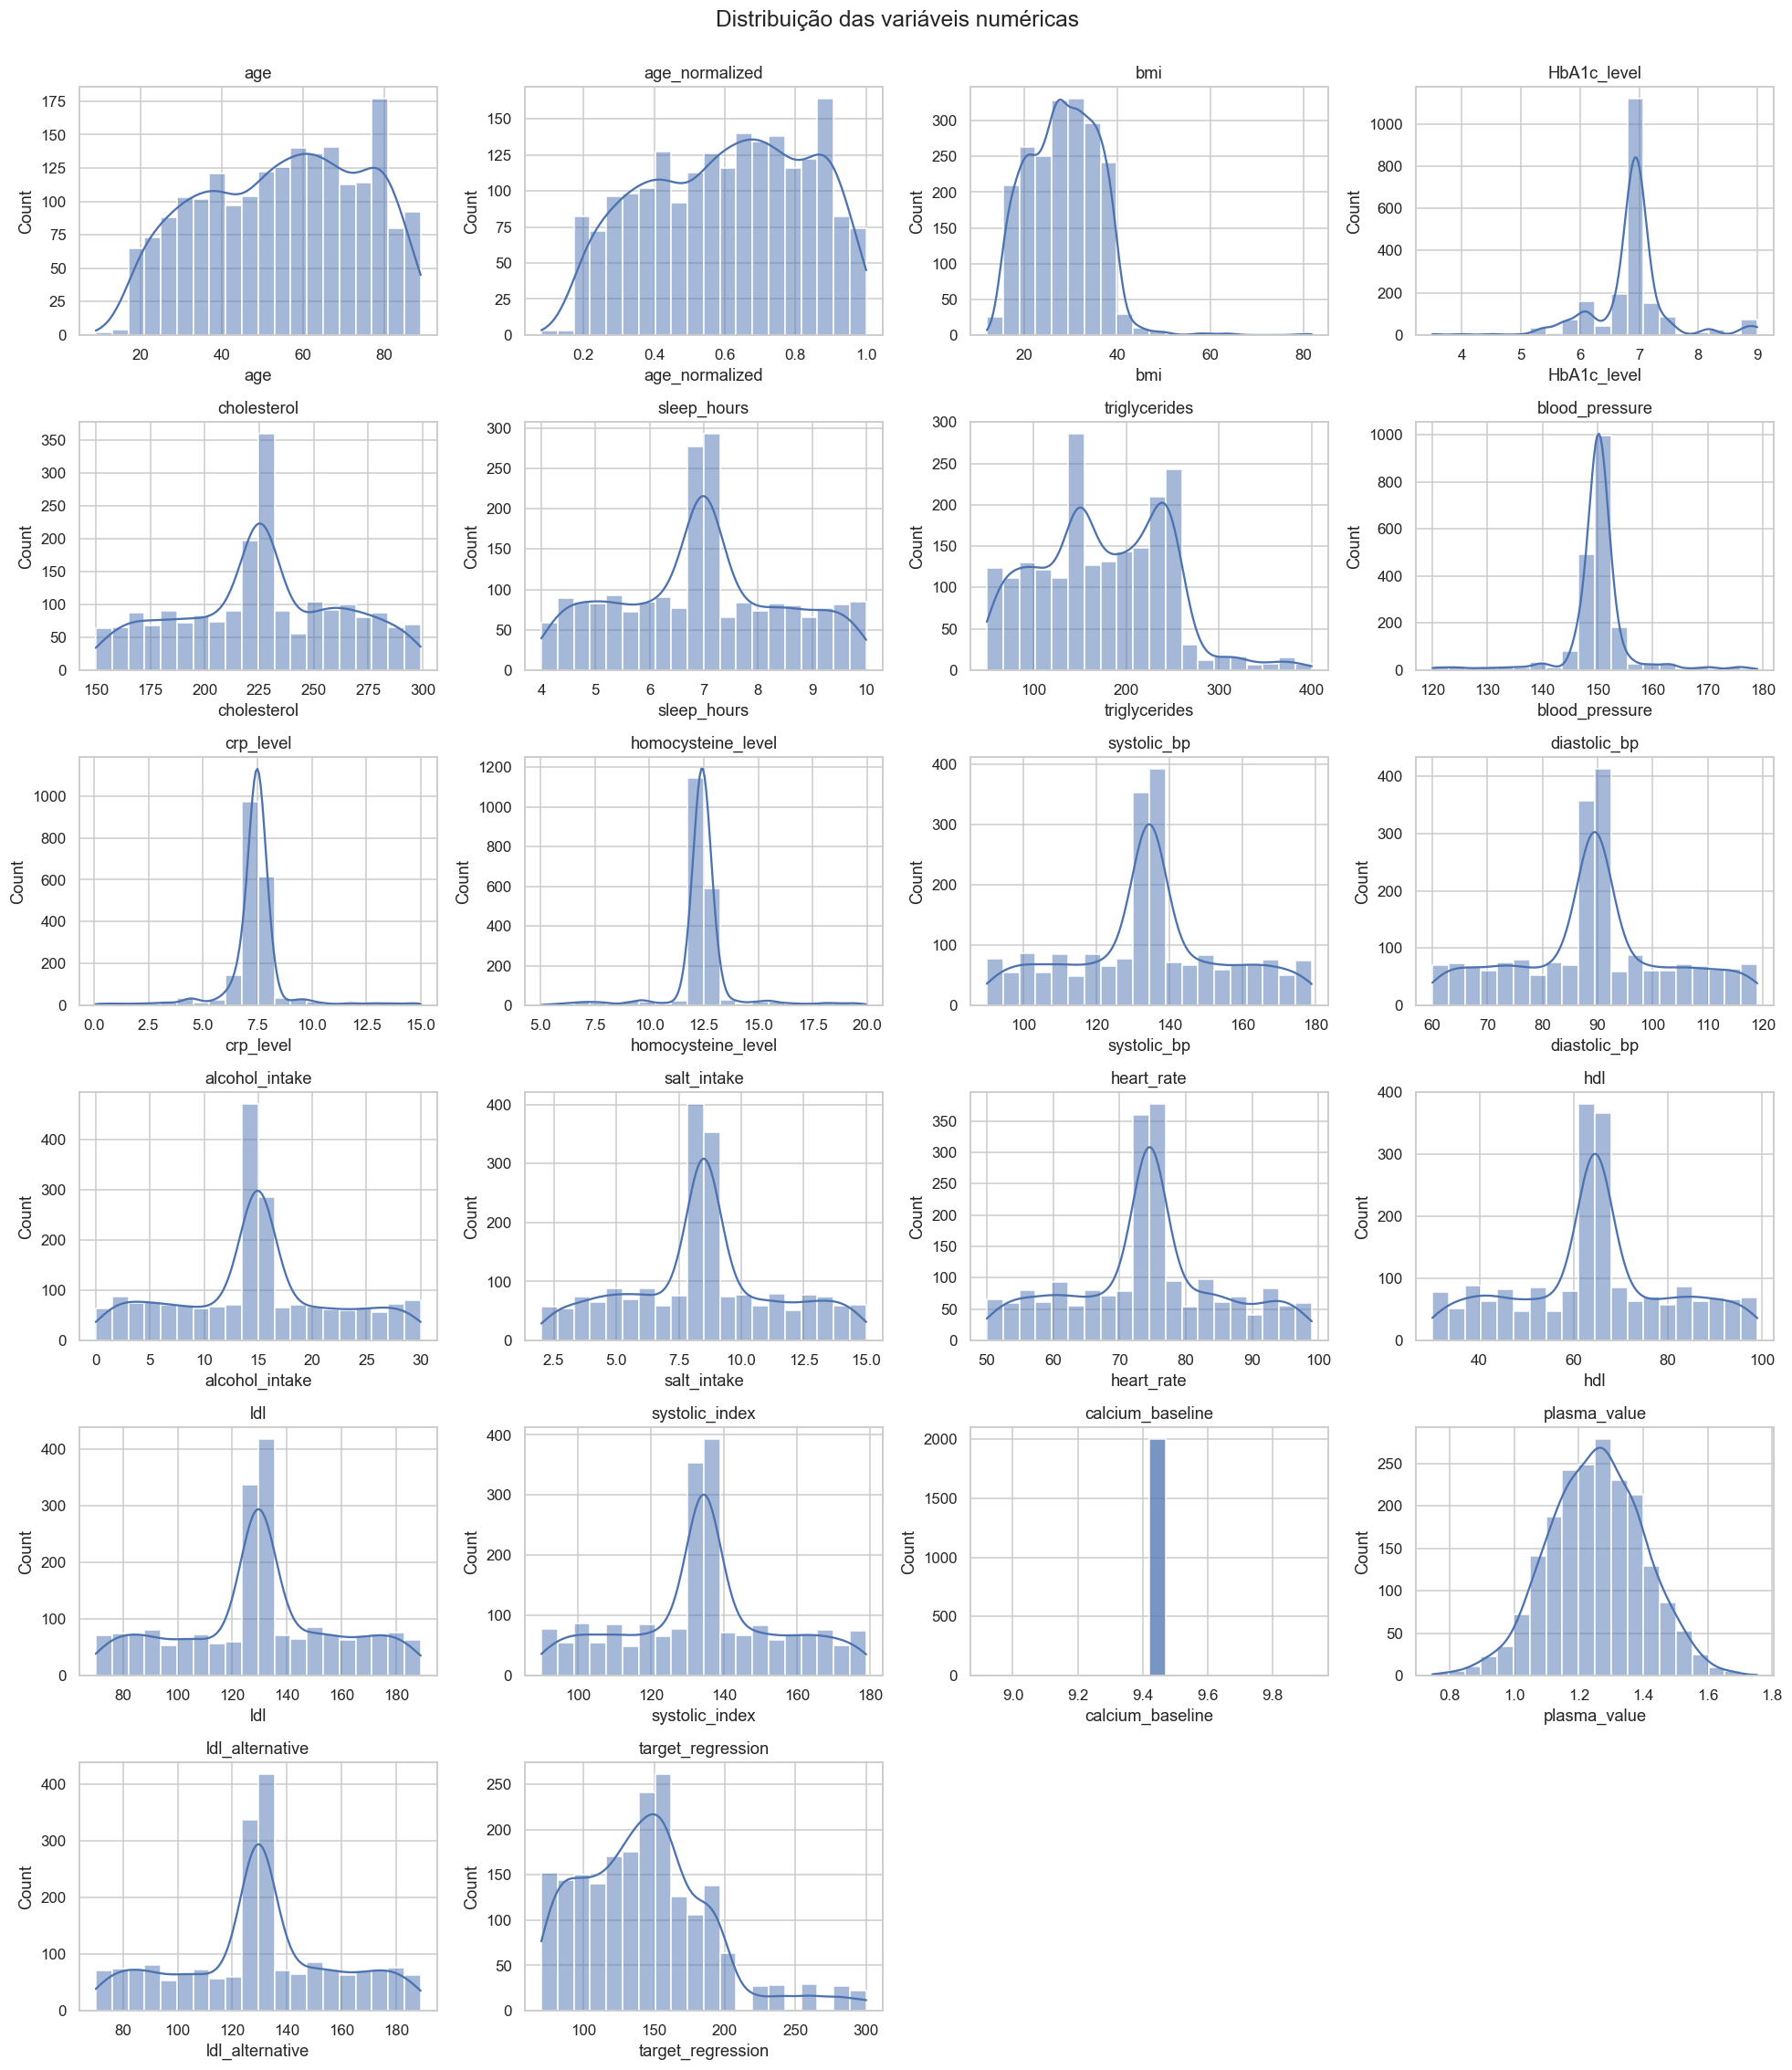

In [21]:
sns.set(style="whitegrid")

numeric_cols = df.select_dtypes(include="number").columns
n_cols = 4
n_rows = (len(numeric_cols) + n_cols - 1) // n_cols

fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, 3.5 * n_rows))
fig.suptitle("Distribuição das variáveis numéricas", fontsize=16)

for col, ax in zip(numeric_cols, axes.flat):
    sns.histplot(
        data=df,
        x=col,
        kde=df[col].nunique() > 1,
        bins=20,
        ax=ax
    )
    ax.set_title(col)

for ax in axes.flat[len(numeric_cols):]:
    ax.set_visible(False)

plt.tight_layout(rect=[0, 0, 1, 0.98])
plt.show()

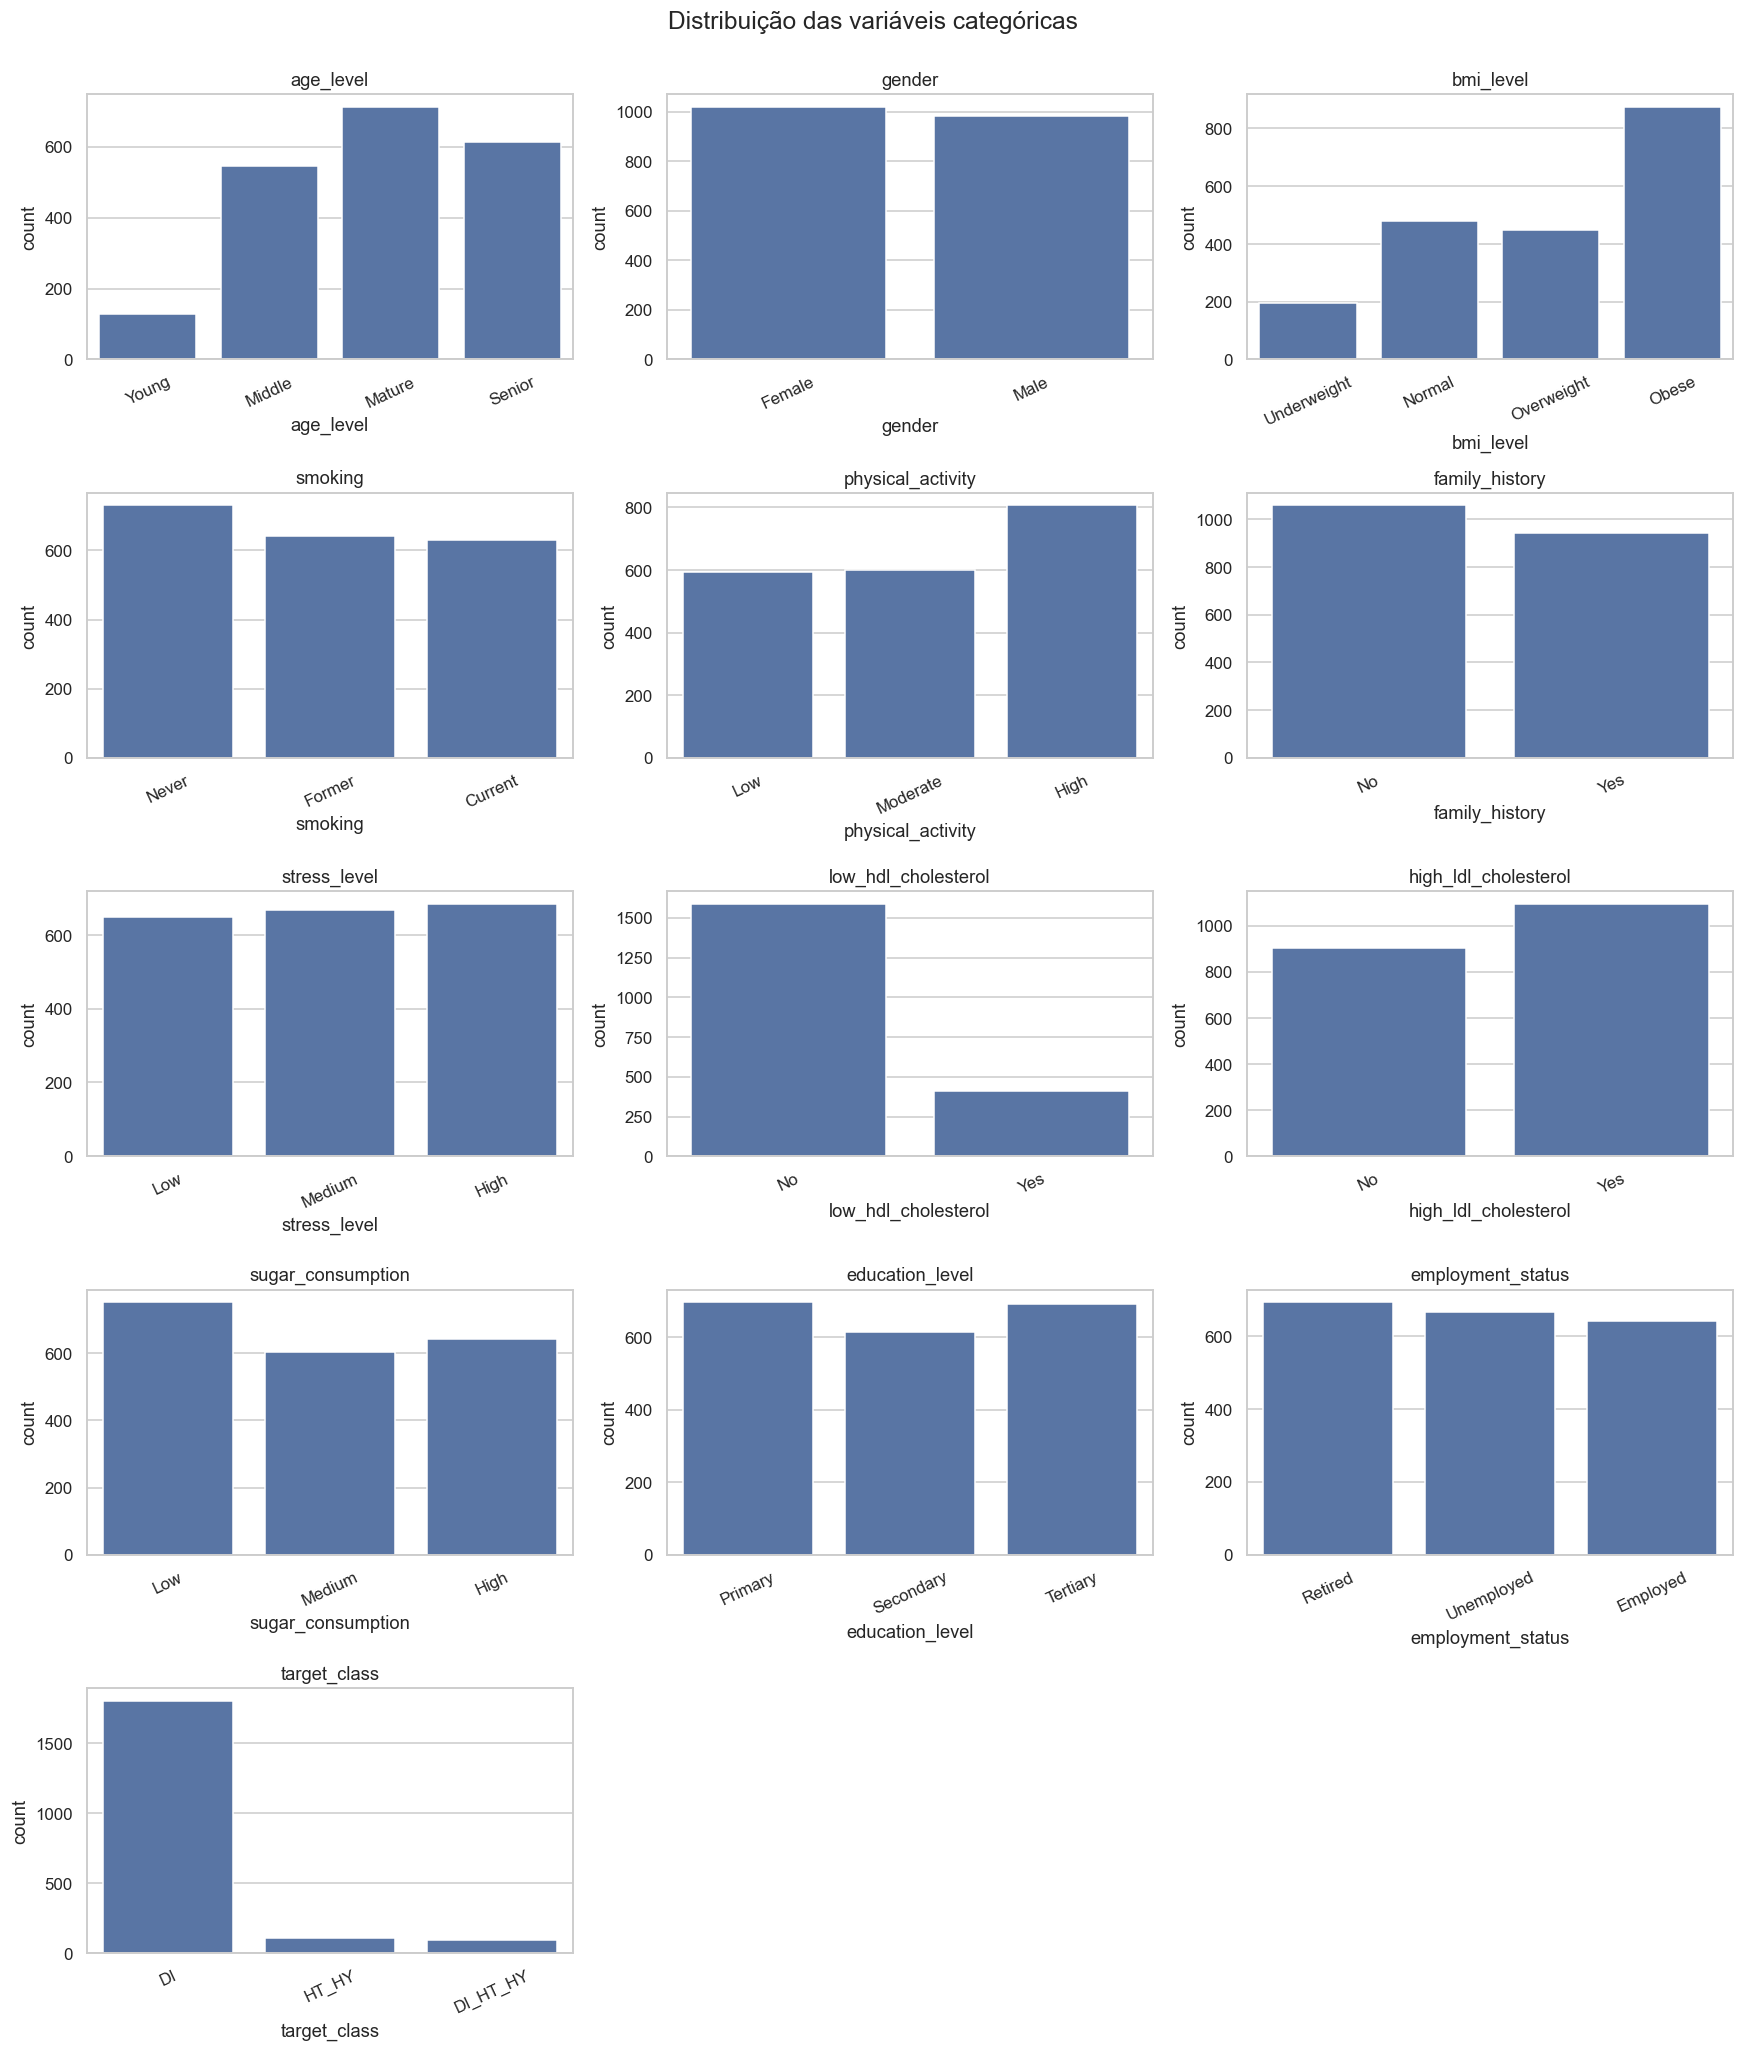

In [22]:
categorical_cols = df.select_dtypes(include=["object", "string"]).columns
n_cols = 3
n_rows = (len(categorical_cols) + n_cols - 1) // n_cols

# só para ficar mais bonito
category_orders = {
    "age_level": ["Young", "Middle", "Mature", "Senior"],
    "bmi_level": ["Underweight", "Normal", "Overweight", "Obese"],
    "smoking": ["Never", "Former", "Current"],
    "physical_activity": ["Low", "Moderate", "High"],
    "stress_level": ["Low", "Medium", "High"],
    "sugar_consumption": ["Low", "Medium", "High"],
    "education_level": ["Primary", "Secondary", "Tertiary"],
    "family_history": ["No", "Yes"],
    "low_hdl_cholesterol": ["No", "Yes"],
    "high_ldl_cholesterol": ["No", "Yes"]
}

fig, axes = plt.subplots(n_rows, n_cols, figsize=(16, 3.8 * n_rows))
fig.suptitle("Distribuição das variáveis categóricas", fontsize=16)

for col, ax in zip(categorical_cols, axes.flat):
    order = category_orders.get(col, df[col].value_counts().index)
    sns.countplot(data=df, x=col, order=order, ax=ax)
    ax.set_title(col)
    ax.tick_params(axis="x", rotation=25)

for ax in axes.flat[len(categorical_cols):]:
    ax.set_visible(False)

plt.tight_layout(rect=[0, 0, 1, 0.98])
plt.show()

- Most numerical variables are relatively symmetric. `bmi` and `target_regression` show greater right skew, with some high values.
- `HbA1c_level`, `blood_pressure`, `crp_level`, and `homocysteine_level` show a central concentration with smaller groups of distant values. This pattern alone does not establish errors; these values are retained for modelling.
- `age_normalized` has a similar distribution to `age`. `systolic_index` and `ldl_alternative` reproduce the marginal distributions of `systolic_bp` and `ldl`, respectively.
- Most categorical features are relatively balanced, with exceptions including `age_level`, `bmi_level`, and `low_hdl_cholesterol`. `target_class` is highly imbalanced, with `DI` strongly predominant.


### 2.4 Bivariate Analysis — Regression


In [23]:
regression_correlations = (
    df.select_dtypes(include="number")
      .corr()["target_regression"]
      .drop("target_regression")
      .sort_values(key=abs, ascending=False)
)

regression_correlations

bmi                   0.109576
triglycerides         0.073934
HbA1c_level           0.066432
ldl                  -0.050126
age_normalized        0.049548
age                   0.049548
crp_level             0.031213
heart_rate            0.025410
homocysteine_level   -0.023038
alcohol_intake       -0.022386
systolic_index       -0.021847
systolic_bp          -0.021847
hdl                   0.020588
cholesterol           0.018173
sleep_hours          -0.015031
salt_intake           0.012597
plasma_value          0.011409
diastolic_bp          0.007423
ldl_alternative      -0.006842
blood_pressure        0.002071
calcium_baseline           NaN
Name: target_regression, dtype: float64

- Linear correlations with `target_regression` are weak. The highest are `bmi` (0.110), `triglycerides` (0.074), and `HbA1c_level` (0.066).
- `age` and `age_normalized` have identical target correlations, consistent with their equivalent information on different scales. The same holds for `systolic_bp` and its exact copy, `systolic_index`.
- `ldl_alternative` has almost zero linear correlation with this target; this does not establish its relevance for classification.
- The correlation for `calcium_baseline` is `NaN` because Pearson correlation is undefined for a constant variable.
- These results suggest limited performance from individual linear predictors, which will be assessed using simple linear regression.


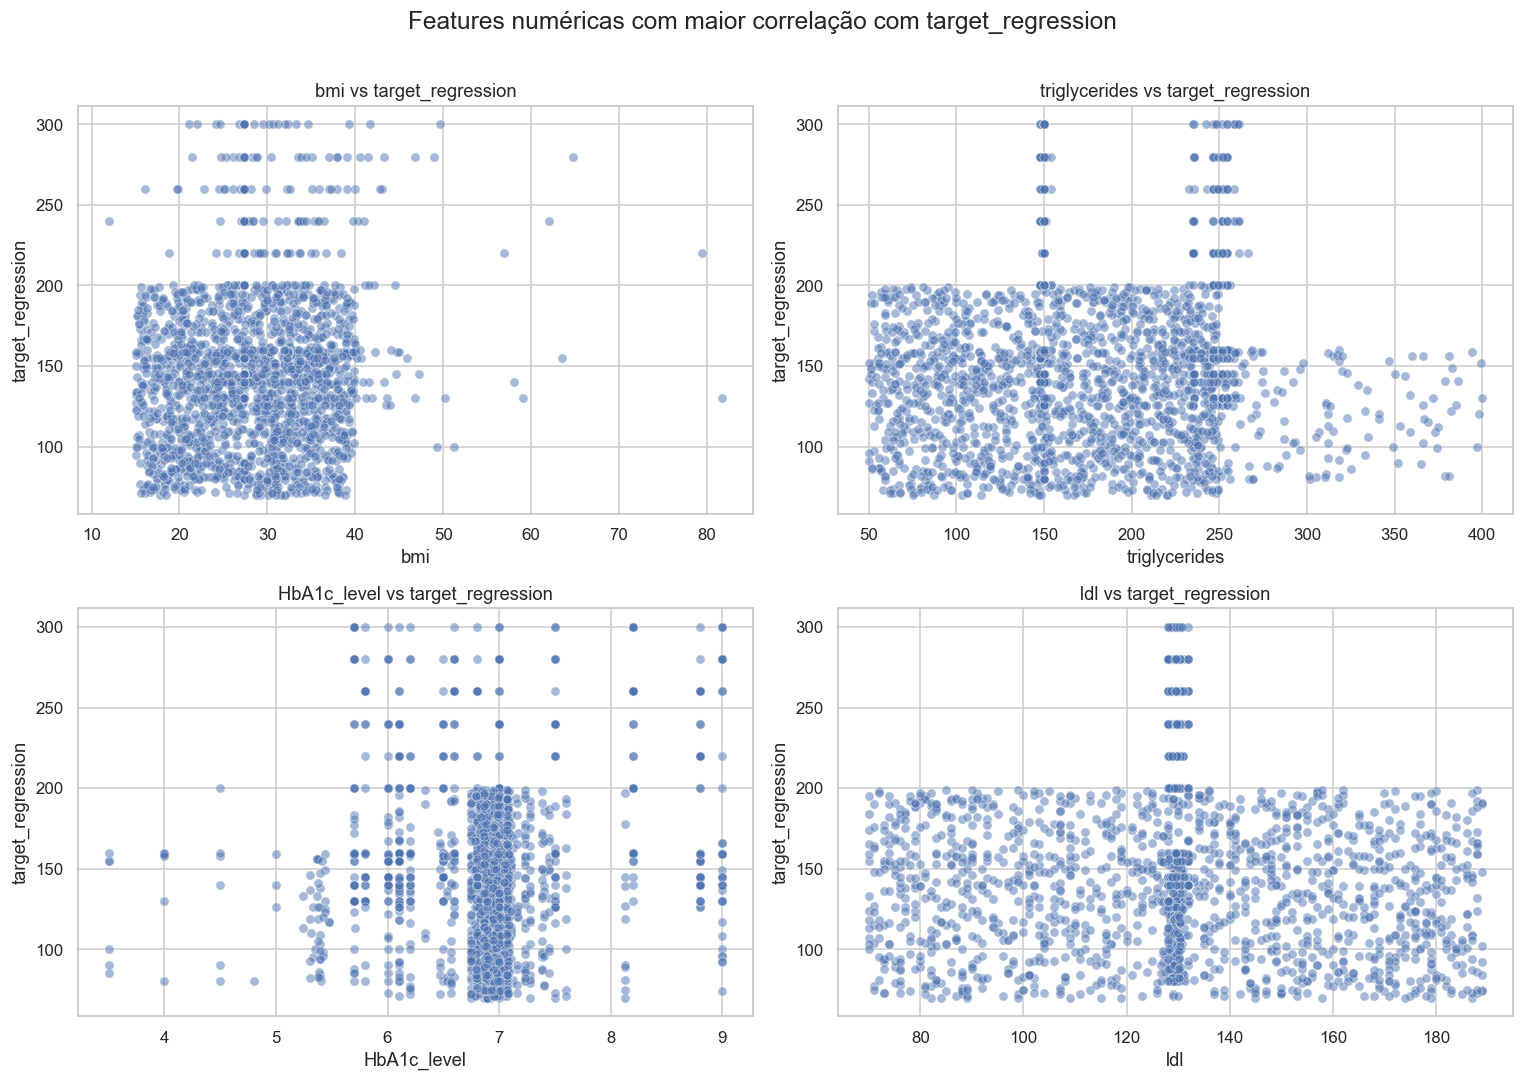

In [24]:
selected_features = regression_correlations.head(4).index

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle(
    "Features numéricas com maior correlação com target_regression",
    fontsize=16
)

for feature, ax in zip(selected_features, axes.flat):
    sns.scatterplot(
        data=df,
        x=feature,
        y="target_regression",
        alpha=0.5,
        ax=ax
    )
    ax.set_title(f"{feature} vs target_regression")

plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()

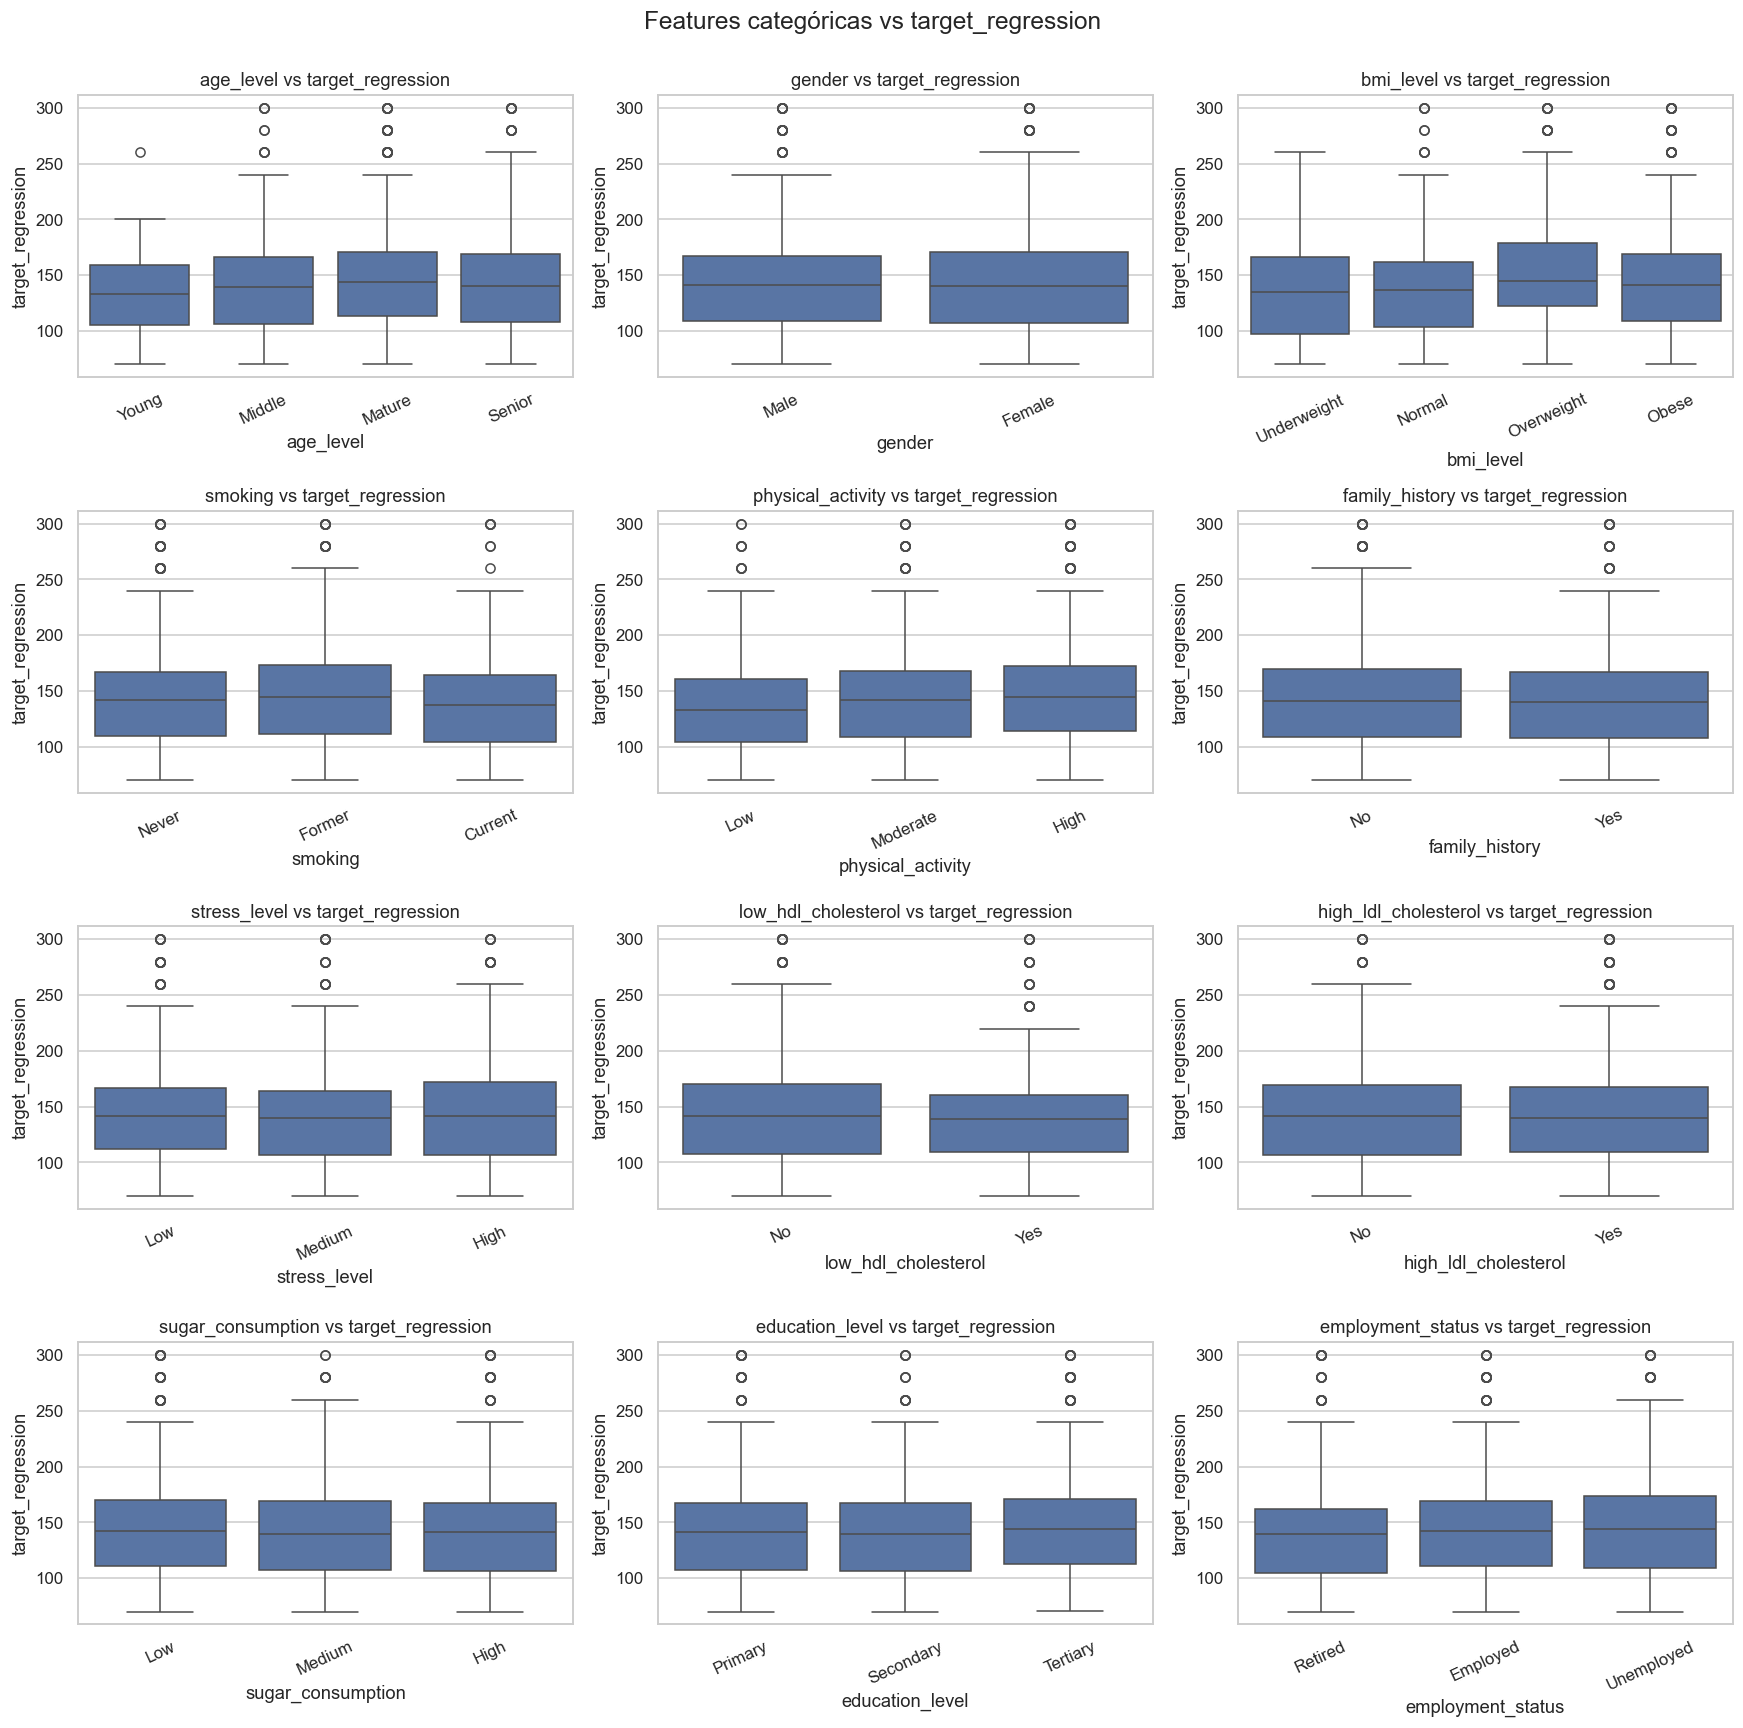

In [25]:
categorical_predictors = categorical_cols.drop("target_class")

n_cols = 3
n_rows = (
    len(categorical_predictors) + n_cols - 1
) // n_cols

fig, axes = plt.subplots(
    n_rows,
    n_cols,
    figsize=(16, 4 * n_rows)
)

fig.suptitle(
    "Features categóricas vs target_regression",
    fontsize=16
)

for feature, ax in zip(categorical_predictors, axes.flat):
    order = category_orders.get(feature)

    sns.boxplot(
        data=df,
        x=feature,
        y="target_regression",
        order=order,
        ax=ax
    )

    ax.set_title(f"{feature} vs target_regression")
    ax.tick_params(axis="x", rotation=25)

for ax in axes.flat[len(categorical_predictors):]:
    ax.set_visible(False)

plt.tight_layout(rect=[0, 0, 1, 0.98])
plt.show()

- `target_regression` distributions overlap substantially across all categorical features examined.
- Median differences across `age_level`, `bmi_level`, `physical_activity`, and `employment_status` are small relative to within-group variability.
- Extreme target values near 260, 280, and 300 occur across several categories rather than exclusively within one group.
- No categorical feature shows a strong individual association visually. Their predictive contribution will be assessed through modelling; these plots alone do not establish irrelevance.


In [26]:
df.groupby("target_class")["target_regression"].agg(
    ["count", "mean", "median", "std", "min", "max"]
)

,count,mean,median,std,min,max
target_class,,,,,,
DI,1801,144.267629,142.0,46.951210,70.0,300.0
DI_HT_HY,94,150.787234,142.0,51.775544,80.0,280.0
HT_HY,105,125.123810,126.0,32.569362,80.0,200.0


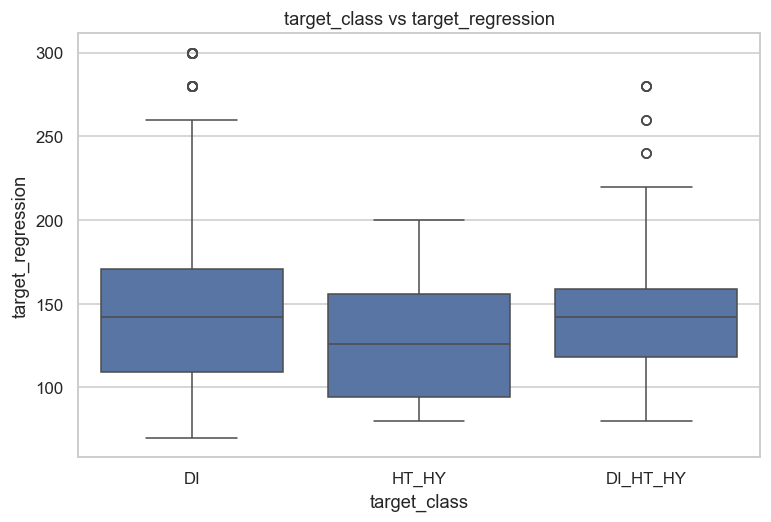

In [27]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="target_class",
    y="target_regression",
    order=["DI", "HT_HY", "DI_HT_HY"]
)

plt.title("target_class vs target_regression")
plt.show()

- `HT_HY` has lower `target_regression` values, with a mean of 125.12 and median of 126.
- `DI` and `DI_HT_HY` share a median of 142. `DI_HT_HY` has a slightly higher mean and greater dispersion.
- The distributions overlap substantially. Minority-class summaries rely on fewer observations and require caution.

This comparison describes the relationship between the targets; neither is used to predict the other.


### 2.5 Bivariate Analysis — Classification


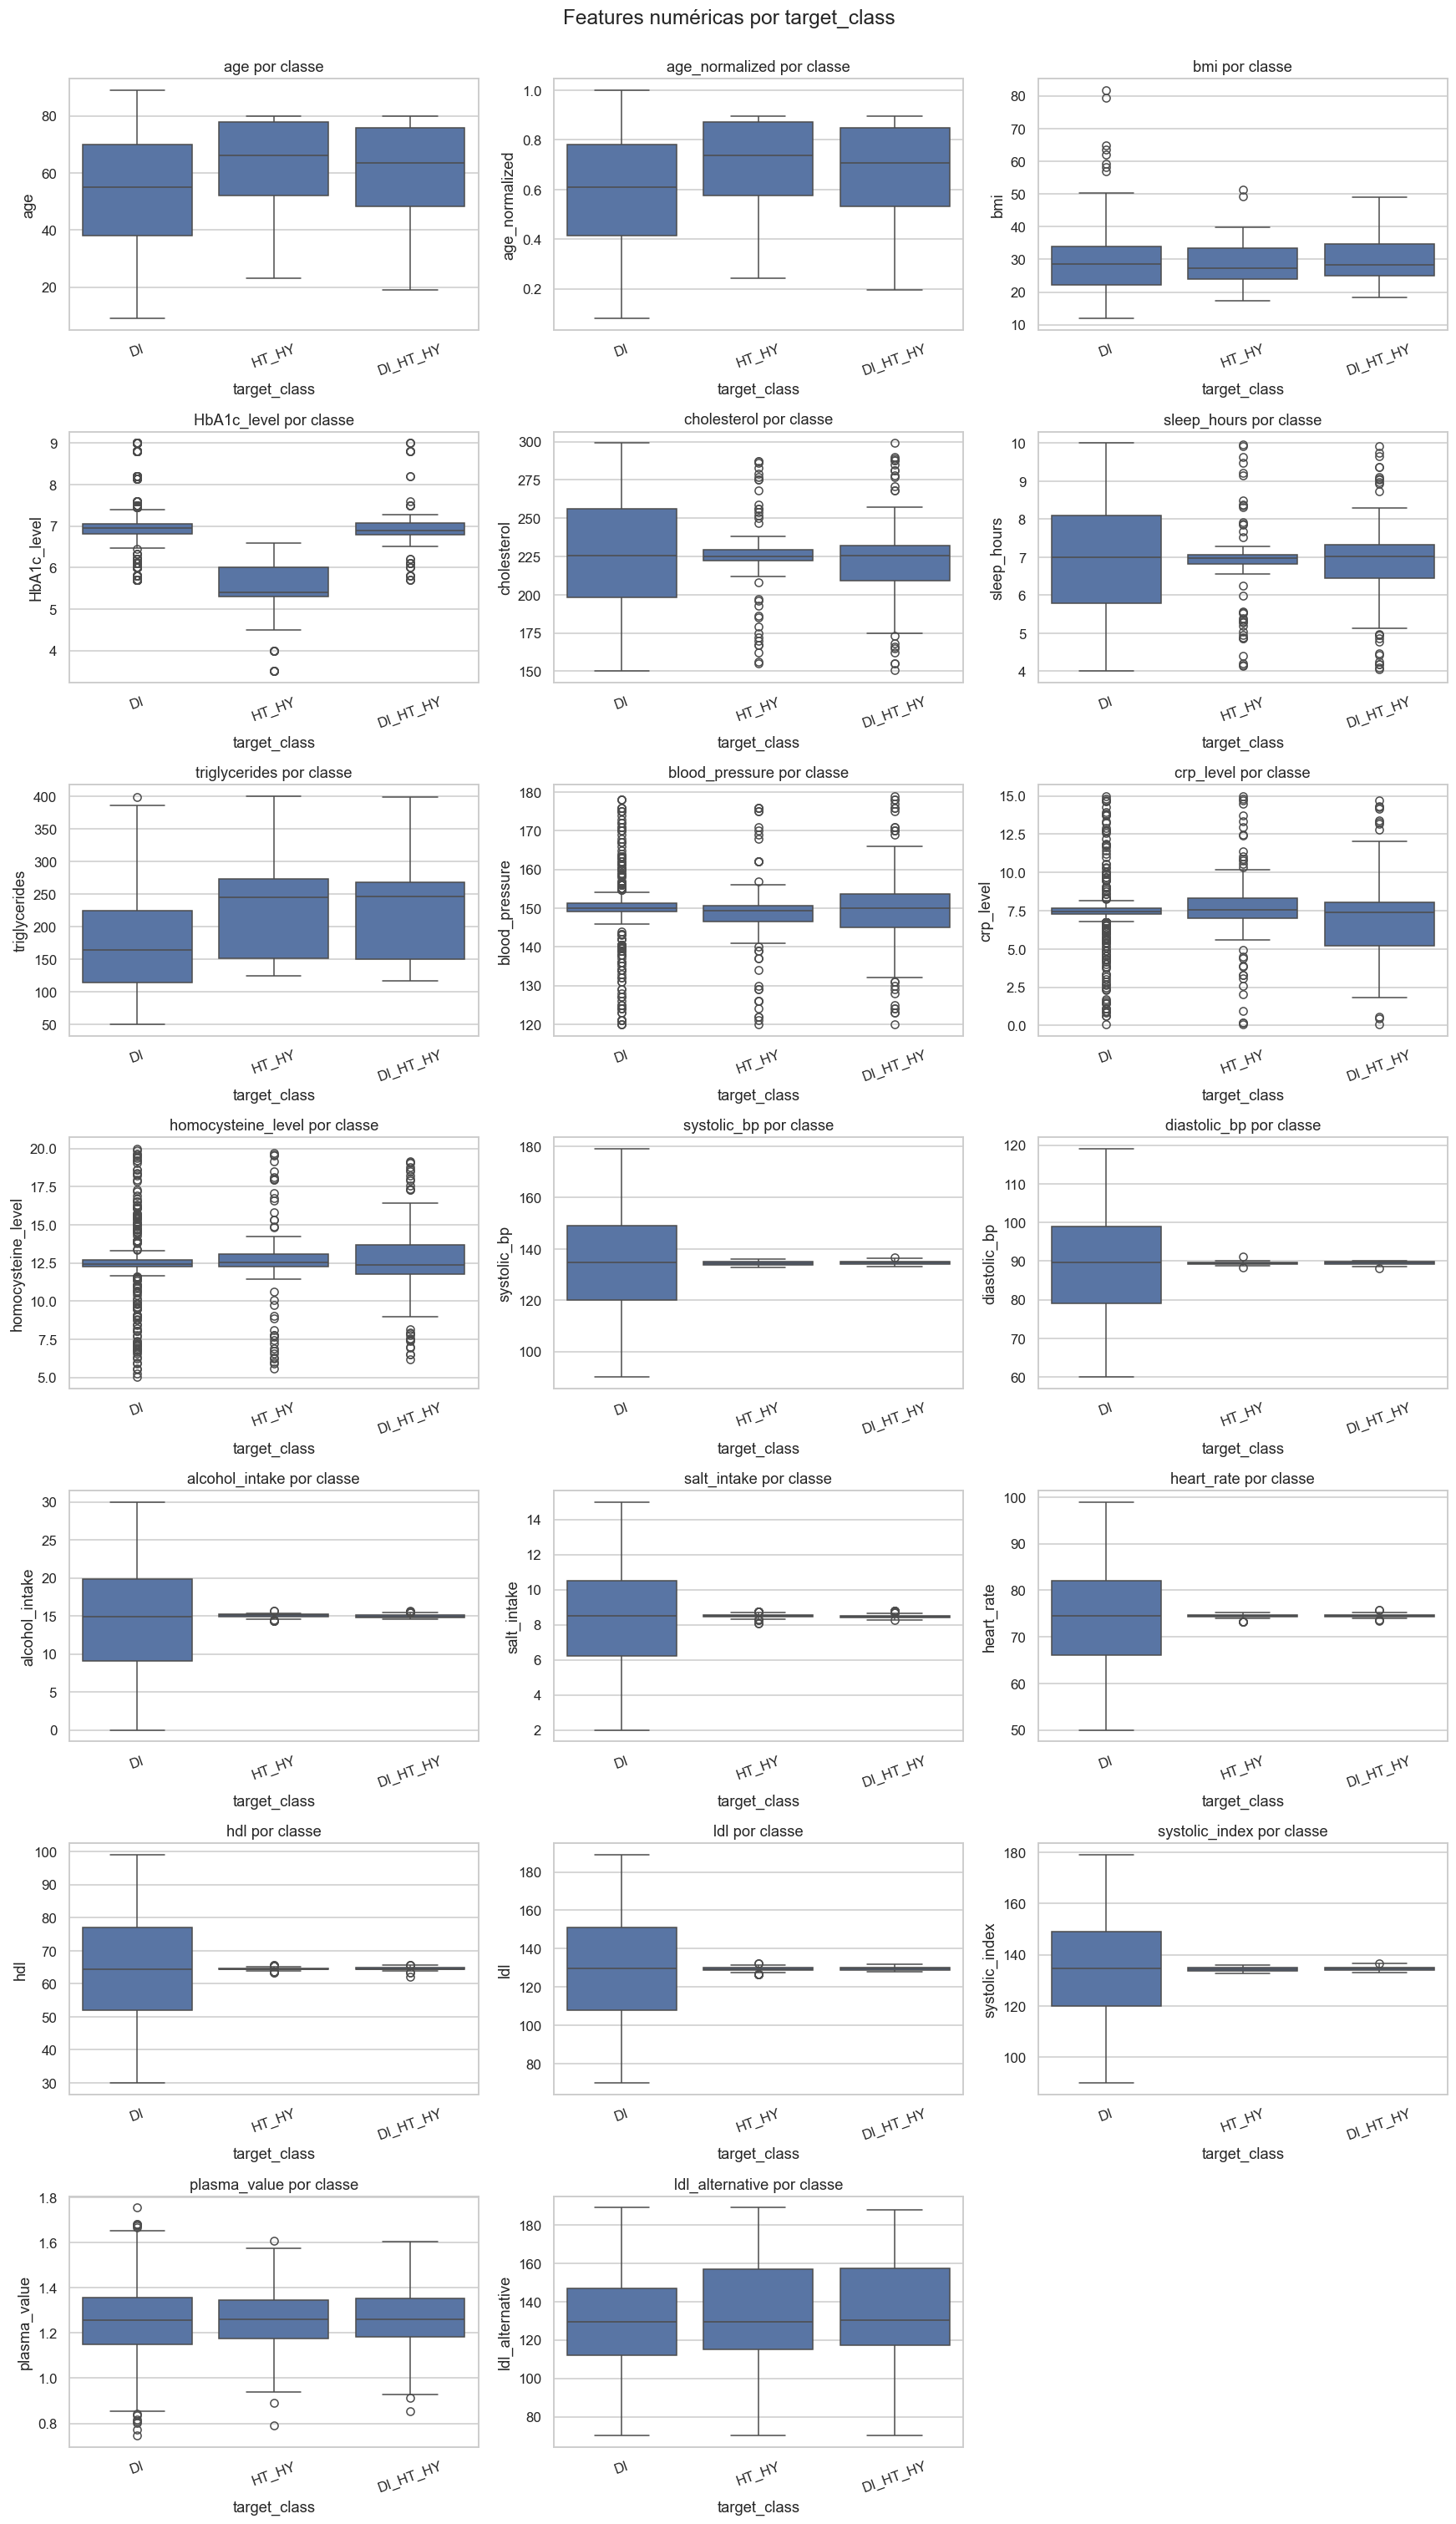

In [28]:
numeric_predictors = (
    df.select_dtypes(include="number")
      .columns
      .drop(["target_regression", "calcium_baseline"])
)

n_cols = 3
n_rows = (
    len(numeric_predictors) + n_cols - 1
) // n_cols

fig, axes = plt.subplots(
    n_rows,
    n_cols,
    figsize=(16, 4 * n_rows)
)

fig.suptitle(
    "Features numéricas por target_class",
    fontsize=16
)

class_order = ["DI", "HT_HY", "DI_HT_HY"]

for feature, ax in zip(numeric_predictors, axes.flat):
    sns.boxplot(
        data=df,
        x="target_class",
        y=feature,
        order=class_order,
        ax=ax
    )

    ax.set_title(f"{feature} por classe")
    ax.tick_params(axis="x", rotation=20)

for ax in axes.flat[len(numeric_predictors):]:
    ax.set_visible(False)

plt.tight_layout(rect=[0, 0, 1, 0.98])
plt.show()

- `age` and `triglycerides` are generally higher in `HT_HY` and `DI_HT_HY`; `age_normalized` reproduces the age pattern.
- `HbA1c_level` is generally lower in `HT_HY`, while `DI` and `DI_HT_HY` have higher, similar values.
- `systolic_bp`, `diastolic_bp`, `alcohol_intake`, `salt_intake`, `heart_rate`, `hdl`, and `ldl` have similar medians across classes but greater dispersion in `DI`.
- `plasma_value` and `ldl_alternative` have similar class distributions, suggesting limited individual discrimination. `systolic_index` reproduces `systolic_bp`.

Dispersion differences are relevant to LDA's shared covariance assumption, but these plots alone do not establish whether it holds.


Small within-class interquartile ranges cause some moderately distant values to appear as boxplot outliers. This does not establish measurement errors; these patients are retained given the incomplete variable definitions.


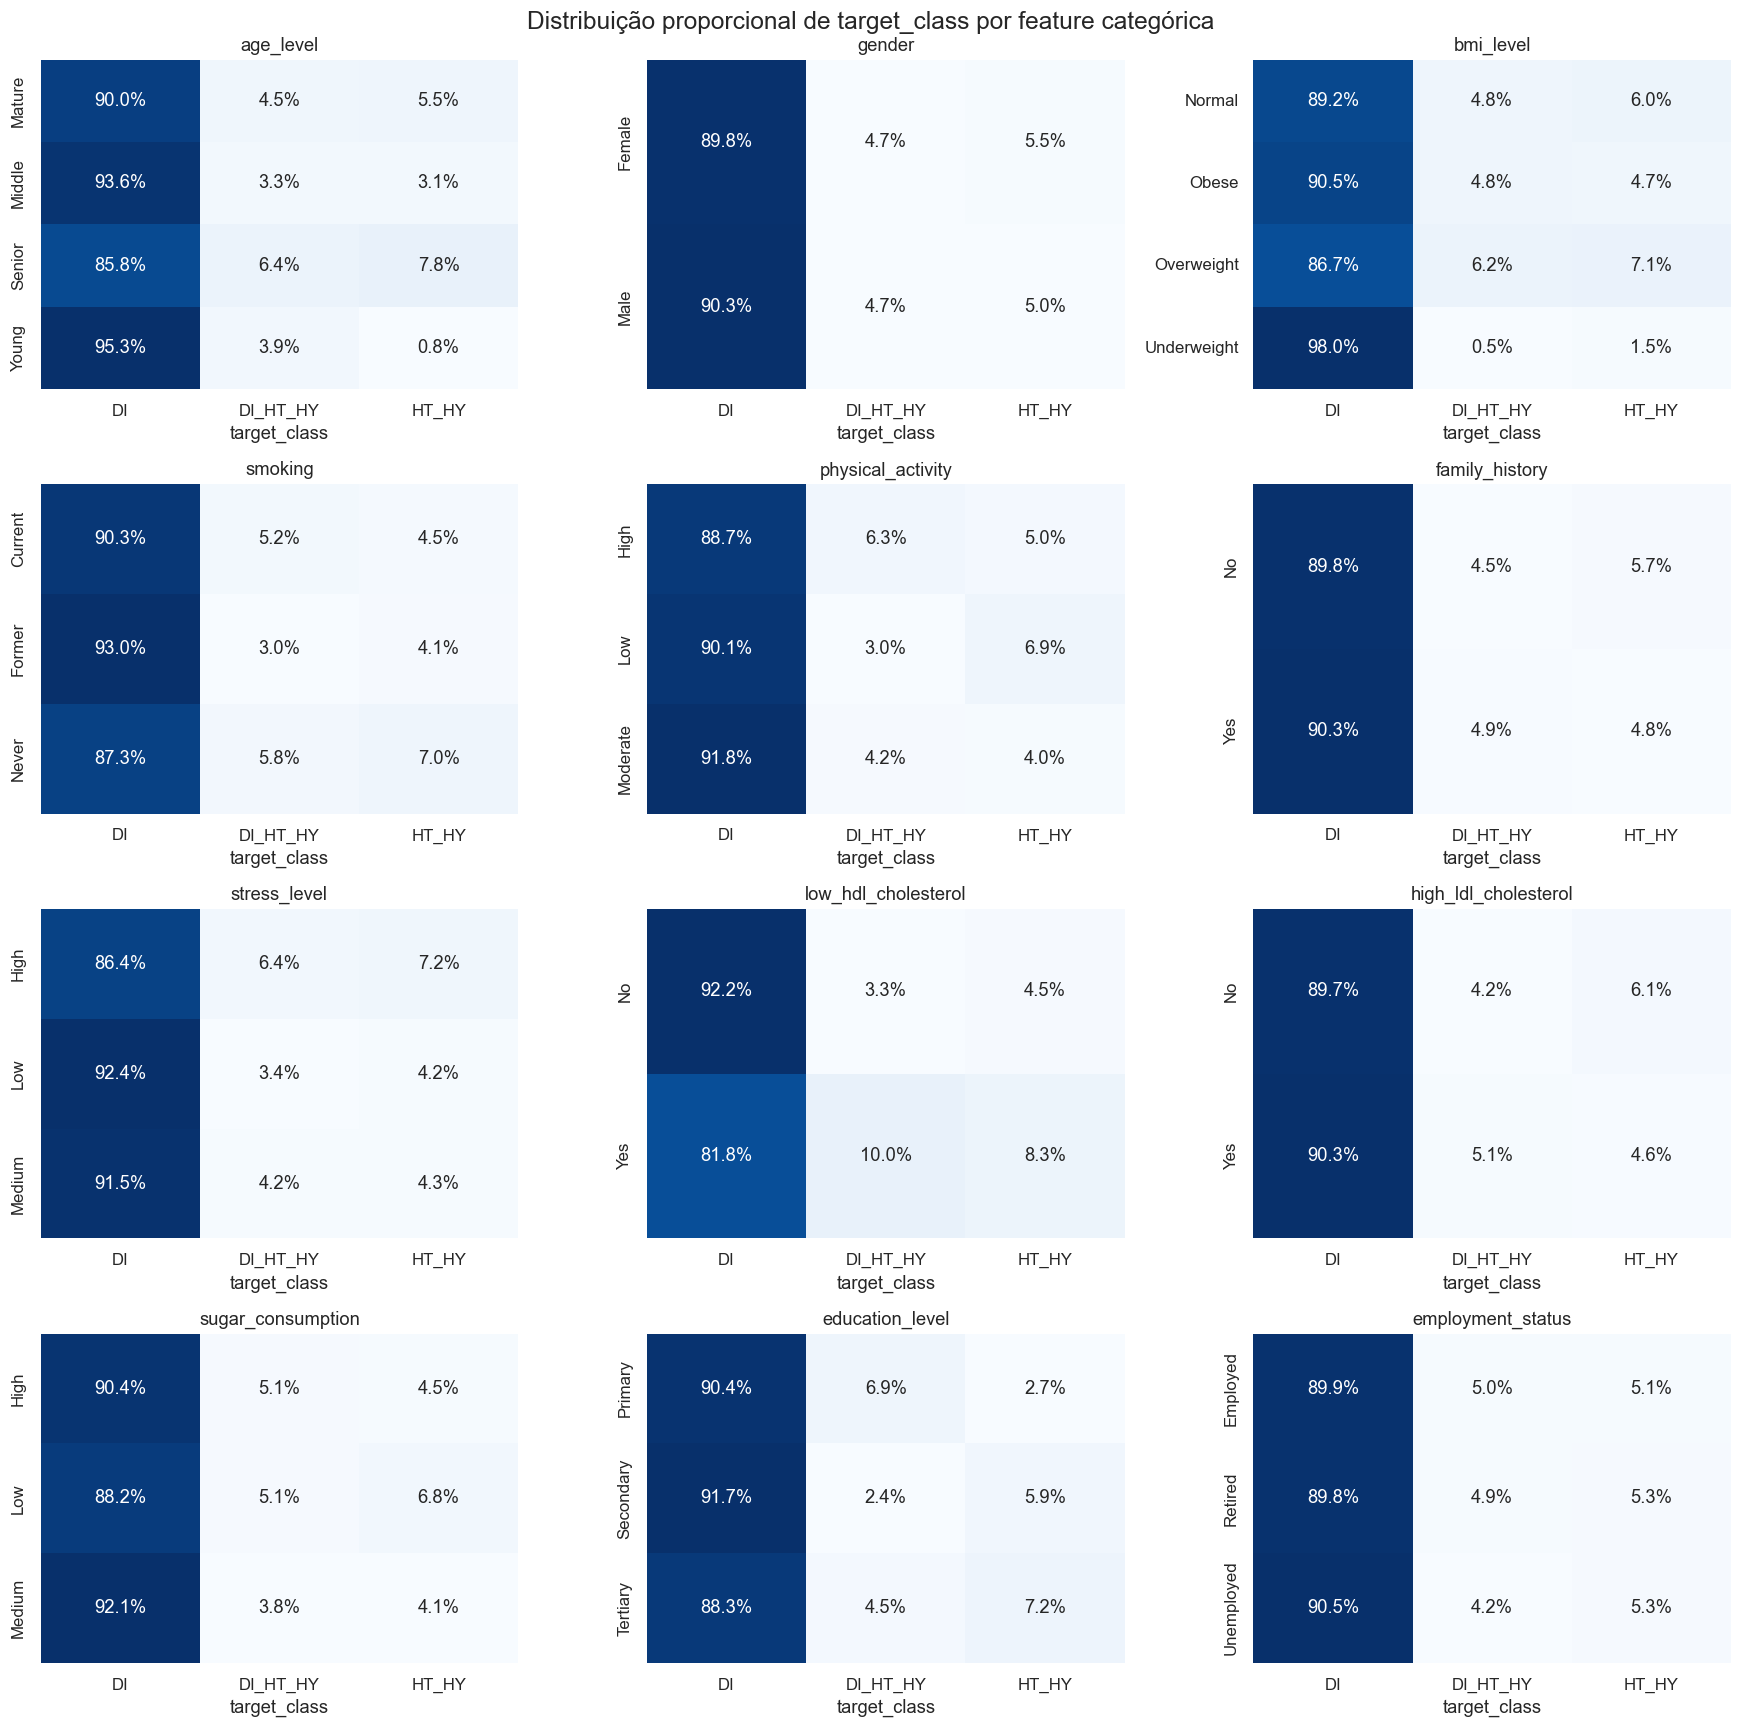

In [29]:
categorical_predictors = categorical_cols.drop("target_class")

n_cols = 3
n_rows = (len(categorical_predictors) + n_cols - 1) // n_cols

fig, axes = plt.subplots(
    n_rows,
    n_cols,
    figsize=(16, 4 * n_rows)
)

for feature, ax in zip(categorical_predictors, axes.flat):
    proportions = pd.crosstab(
        df[feature],
        df["target_class"],
        normalize="index"
    )

    sns.heatmap(
        proportions,
        annot=True,
        fmt=".1%",
        cmap="Blues",
        ax=ax,
        cbar=False
    )

    ax.set_title(feature)
    ax.set_xlabel("target_class")
    ax.set_ylabel("")

for ax in axes.flat[len(categorical_predictors):]:
    ax.set_visible(False)

plt.suptitle(
    "Distribuição proporcional de target_class por feature categórica",
    fontsize=16
)
plt.tight_layout()
plt.show()

`DI` predominates across all categories examined, confirming the strong imbalance in `target_class`.


## 3. Evaluation Protocol and Data Preparation

The original unstratified 80/20 split is retained with seed 42: 1,600 training and 400 test patients. Training counts are 1,443 `DI`, 89 `HT_HY`, and 68 `DI_HT_HY`; test counts are 358, 16, and 26. Internal classification splits are stratified, preserving proportions rather than balancing classes.

Regression candidates share five folds and are selected by mean RMSE. Classification uses mean macro F1 from stratified CV5 with three repetitions (15 evaluations), supported by per-class precision and recall. Holdout, CV10, LOOCV, and bootstrap provide complementary assessments within the training set.

`prepare_features` learns categories and scaling within each fit. Unpenalised regression uses `scaling='none'`; initial classification and manual feature comparisons use `numeric`; regularisation uses `all`, including dummies. Comparisons with different preprocessing cannot isolate a single modelling effect.

Global EDA and earlier test inspection make results exploratory rather than an independent final validation. Repeated selection of features, weights, and configurations using the same CV may produce optimistic scores. Fitting preprocessing within folds does not remove information gained from earlier analyses.


In [30]:
train_indices, test_indices = train_test_split(
    df.index, test_size=0.2, random_state=42
)
assert set(train_indices).isdisjoint(test_indices)
print('Treino:', len(train_indices))
print('Teste:', len(test_indices))

def regression_metrics(actual, predicted):
    return {
        'R2': r2_score(actual, predicted),
        'MAE': mean_absolute_error(actual, predicted),
        'RMSE': np.sqrt(mean_squared_error(actual, predicted))
    }


Treino: 1600
Teste: 400


### Training-Set Consistency Audit

The audit flags 84 training patients with systolic pressure below diastolic pressure, all belonging to `DI`. Age/BMI category checks identify no additional exclusions.

`coherent_train_indices` records 1,516 patients but is not used for modelling. All models use `train_indices` with 1,600 patients and retain the same 400 test patients. Unconfirmed consistency alerts and boxplot outliers do not trigger exclusions.


In [31]:
training_data = df.loc[train_indices]
age_category_matches = pd.Series(False, index=train_indices)
age_intervals = {'Young': (9, 23), 'Middle': (24, 45), 'Mature': (46, 67), 'Senior': (68, 89)}
for category, (lower, upper) in age_intervals.items():
    age_category_matches |= (
        (training_data['age_level'] == category) & training_data['age'].between(lower, upper)
    )

expected_bmi_category = pd.cut(
    training_data['bmi'], [-np.inf, 18.5, 25, 30, np.inf],
    labels=['Underweight', 'Normal', 'Overweight', 'Obese'], right=False
)
training_coherence_flags = pd.DataFrame({
    'Pressão sistólica inferior à diastólica': training_data['systolic_bp'] < training_data['diastolic_bp'],
    'Idade incompatível com categoria': ~age_category_matches,
    'IMC incompatível com categoria': training_data['bmi_level'] != expected_bmi_category
})
training_exclusion_mask = training_coherence_flags.any(axis=1)
coherent_train_indices = train_indices[~training_exclusion_mask.to_numpy()]
assert set(coherent_train_indices).issubset(set(train_indices))
assert set(coherent_train_indices).isdisjoint(test_indices)
assert len(test_indices) == 400
print(training_coherence_flags.sum())
print('Treino original:', len(train_indices))
print('Treino após exclusões:', len(coherent_train_indices))
print('Teste mantido:', len(test_indices))
print('Classes excluídas do treino:')
print(training_data.loc[training_exclusion_mask, 'target_class'].value_counts())


# Alertas adicionais apenas no treino: não entram na máscara de exclusão.
training_clinical_alerts = clinical_alerts.loc[train_indices].drop(columns=['Pressões invertidas'])
display(pd.DataFrame({'Alertas no treino': training_clinical_alerts.sum(),
                      'Percentagem (%)': training_clinical_alerts.mean() * 100}).round(2))


Pressão sistólica inferior à diastólica    84
Idade incompatível com categoria            0
IMC incompatível com categoria              0
dtype: int64
Treino original: 1600
Treino após exclusões: 1516
Teste mantido: 400
Classes excluídas do treino:
target_class
DI    84
Name: count, dtype: int64


,Alertas no treino,Percentagem (%)
Pressões iguais,6,0.38
Pressão agregada fora dos limites (apenas pressões ordenadas),1131,70.69
Total inferior ao LDL,40,2.50
Total inferior ao HDL,0,0.00
Total inferior a HDL + LDL,384,24.00


### Numerical Redundancy Screening

Pairs with absolute Pearson correlation ≥ 0.90 are listed using only the 1,600 training patients, excluding both targets. Constant variables have undefined correlations and do not appear.

This is a screening step, not an automatic removal rule. High correlation does not establish exact duplication, while permuted values may have little correlation.


In [32]:
# Procurar pares muito correlacionados apenas nas features do treino.
# Incluímos as colunas ainda não excluídas para detetar redundâncias.
numeric_training_features = (
    df.loc[train_indices]
      .drop(columns=['target_regression', 'target_class'])
      .select_dtypes(include='number')
)
feature_correlations = numeric_training_features.corr()
correlation_threshold = 0.90
high_correlation_pairs = []

for i, feature_a in enumerate(feature_correlations.columns):
    for feature_b in feature_correlations.columns[i + 1:]:
        correlation = feature_correlations.loc[feature_a, feature_b]
        if pd.notna(correlation) and abs(correlation) >= correlation_threshold:
            high_correlation_pairs.append({
                'Feature A': feature_a,
                'Feature B': feature_b,
                'Correlação': correlation
            })

high_correlations_df = pd.DataFrame(
    high_correlation_pairs,
    columns=['Feature A', 'Feature B', 'Correlação']
).sort_values('Correlação', key=abs, ascending=False).reset_index(drop=True)
high_correlations_df


,Feature A,Feature B,Correlação
0,systolic_bp,systolic_index,1.0
1,age,age_normalized,1.0


### 3.1 Features and Common Preparation

Both targets are excluded from `X`, along with `calcium_baseline` (constant), `systolic_index` (an exact copy of `systolic_bp`), and `age_normalized` (rescaled age). The remaining 30 original features produce 40 encoded columns in this execution.

`ldl_alternative`, age/BMI categories, and lipid indicators remain candidates for subsequent comparisons. Weak individual correlation alone is not a removal criterion.

Categorical encoding learns categories within each fit and drops the first as reference. Unseen categories receive all-zero indicators, sharing the reference category's representation; this is a limitation of the encoding convention.


In [33]:
excluded_features = [
    'target_regression', 'target_class',
    'calcium_baseline', 'systolic_index', 'age_normalized'
]
X_available = df.drop(columns=excluded_features)
y_regression = df['target_regression']
numeric_features = X_available.select_dtypes(include='number').columns.tolist()
categorical_features = X_available.select_dtypes(exclude='number').columns.tolist()


def prepare_features(fit_indices, evaluation_indices, features=None, scaling='none'):
    features = X_available.columns.tolist() if features is None else list(features)
    fit_data = X_available.loc[fit_indices, features].copy()
    evaluation_data = X_available.loc[evaluation_indices, features].copy()
    categorical = [column for column in features if column in categorical_features]
    for column in categorical:
        categories = sorted(fit_data[column].unique())
        fit_data[column] = pd.Categorical(fit_data[column], categories=categories)
        evaluation_data[column] = pd.Categorical(evaluation_data[column], categories=categories)
    fit_data = pd.get_dummies(fit_data, columns=categorical, drop_first=True, dtype=float)
    evaluation_data = pd.get_dummies(evaluation_data, columns=categorical, drop_first=True, dtype=float)
    evaluation_data = evaluation_data.reindex(columns=fit_data.columns, fill_value=0)
    assert scaling in ['none', 'numeric', 'all']
    scale_columns = fit_data.columns.tolist() if scaling == 'all' else [c for c in features if c in numeric_features]
    if scaling != 'none' and scale_columns:
        scaler = StandardScaler().fit(fit_data[scale_columns])
        fit_data[scale_columns] = scaler.transform(fit_data[scale_columns])
        evaluation_data[scale_columns] = scaler.transform(evaluation_data[scale_columns])
    assert fit_data.columns.equals(evaluation_data.columns)
    assert np.isfinite(fit_data.to_numpy()).all() and np.isfinite(evaluation_data.to_numpy()).all()
    return fit_data, evaluation_data


## 4. Regression Models

### 4.1 Simple Linear Regression

Each numerical feature is evaluated separately using the same CV5 splits of the 1,600 training patients. The baseline predicts the target mean from each fold's training partition.

Selection uses mean RMSE, alongside mean R² and MAE and the between-fold RMSE standard deviation. Unpenalised models are not standardised. Fold dispersion is descriptive, not a confidence interval.


In [34]:
# Mesmas divisões para todos os modelos
cv5 = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

results = []

for train_positions, validation_positions in cv5.split(train_indices):
    fold_train = train_indices[train_positions]
    fold_validation = train_indices[validation_positions]

    y_train = y_regression.loc[fold_train]
    y_validation = y_regression.loc[fold_validation]

    # Referência: prever sempre a média do treino deste fold
    baseline_predictions = np.full(len(y_validation), y_train.mean())

    results.append({
        'Variável': 'Baseline: média do treino',
        **regression_metrics(y_validation, baseline_predictions)
    })

    # Uma regressão linear por variável numérica
    for feature in numeric_features:
        X_train = X_available.loc[fold_train, [feature]]
        X_validation = X_available.loc[fold_validation, [feature]]

        model = LinearRegression()
        model.fit(X_train, y_train)
        predictions = model.predict(X_validation)

        results.append({
            'Variável': feature,
            **regression_metrics(y_validation, predictions)
        })

# Resumo das cinco avaliações por modelo
fold_results = pd.DataFrame(results)

simple_cv_results = (
    fold_results.groupby('Variável')
    .agg(
        R2_medio=('R2', 'mean'),
        MAE_medio=('MAE', 'mean'),
        RMSE_medio=('RMSE', 'mean'),
        RMSE_desvio_padrao=('RMSE', 'std')
    )
    .sort_values('RMSE_medio')
)

display(simple_cv_results.round(4))

# Escolher a melhor variável, excluindo a baseline
feature_results = simple_cv_results.drop(
    index='Baseline: média do treino'
)

best_feature = feature_results['RMSE_medio'].idxmin()
print('Variável escolhida por CV5:', best_feature)

,R2_medio,MAE_medio,RMSE_medio,RMSE_desvio_padrao
Variável,,,,
bmi,-0.0025,35.7264,46.0110,1.7506
triglycerides,-0.0031,35.7415,46.0361,2.0282
age,-0.0030,35.6393,46.0392,2.1658
HbA1c_level,-0.0032,35.7376,46.0477,2.2616
crp_level,-0.0044,35.6639,46.0735,2.1923
ldl,-0.0046,35.6344,46.0754,2.1283
heart_rate,-0.0051,35.6558,46.0855,2.1026
Baseline: média do treino,-0.0059,35.6718,46.1036,2.1073
systolic_bp,-0.0061,35.6752,46.1055,2.0207


Variável escolhida por CV5: bmi


`bmi` achieved the lowest mean CV5 RMSE (46.0110), slightly below the mean baseline (46.1036). `triglycerides`, `age`, and `HbA1c_level` produced similar results.

Its mean R² was slightly negative (−0.0025), indicating limited individual linear prediction. A small mean RMSE improvement can coexist with negative mean R² because metrics are calculated per fold before averaging.

Although `ldl` had the lowest mean MAE, selection follows RMSE. Other features remain candidates for multiple regression.


### 4.2 Multiple Linear Regression

The full multiple regression uses all features remaining after initial EDA exclusions. Categories are encoded within each fold; no standardisation is applied.

The model is assessed using R², MAE, and RMSE on the same CV5 splits as simple regression, providing the reference for subsequent feature exclusions.


In [35]:
multiple_results = []

for train_positions, validation_positions in cv5.split(train_indices):
    fold_train = train_indices[train_positions]
    fold_validation = train_indices[validation_positions]

    # Aprender a codificação apenas no treino deste fold
    X_train, X_validation = prepare_features(
        fold_train,
        fold_validation,
        scaling='none'
    )

    y_train = y_regression.loc[fold_train]
    y_validation = y_regression.loc[fold_validation]

    model = LinearRegression()
    model.fit(X_train, y_train)
    predictions = model.predict(X_validation)

    multiple_results.append(
        regression_metrics(y_validation, predictions)
    )

multiple_fold_results = pd.DataFrame(multiple_results)

multiple_cv_results = pd.DataFrame({
    'R2_medio': [multiple_fold_results['R2'].mean()],
    'MAE_medio': [multiple_fold_results['MAE'].mean()],
    'RMSE_medio': [multiple_fold_results['RMSE'].mean()],
    'RMSE_desvio_padrao': [multiple_fold_results['RMSE'].std()]
}, index=['Múltipla: todas as features disponíveis'])

# Comparar com a baseline e a melhor regressão simples
regression_cv_comparison = pd.concat([
    simple_cv_results.loc[
        ['Baseline: média do treino', best_feature]
    ],
    multiple_cv_results
])

display(regression_cv_comparison.round(4))

,R2_medio,MAE_medio,RMSE_medio,RMSE_desvio_padrao
Baseline: média do treino,-0.0059,35.6718,46.1036,2.1073
bmi,-0.0025,35.7264,46.0110,1.7506
Múltipla: todas as features disponíveis,0.0207,36.2222,45.4885,2.0795


Multiple regression reduced mean RMSE to 45.4885, compared with 46.0110 for simple regression and 46.1036 for the baseline. Mean R² increased to 0.0207, but predictive performance remained limited.

MAE increased to 36.2222, versus 35.7264 and 35.6718, respectively. The improvement is metric-dependent: RMSE penalises large errors more strongly. Subsequent comparisons retain RMSE as the selection criterion.


### 4.3 Feature-Set Comparisons

Individual exclusions are tested for `age_level`, `bmi_level`, `low_hdl_cholesterol`, `high_ldl_cholesterol`, `ldl_alternative`, and `plasma_value`, motivated by related measurements or weak individual associations in EDA.

Patients, folds, model, and preprocessing remain unchanged. RMSE differences are measured against the full model; negative values favour exclusion. Paired fold differences complement the mean.

Following preliminary results, joint exclusions are tested for `low_hdl_cholesterol` and `plasma_value`, with and without `ldl_alternative`. Sequential use of the same CV makes selection exploratory. Exclusion effects need not be additive.


In [36]:
# Conjuntos candidatos

candidates = [
    'age_level',
    'bmi_level',
    'low_hdl_cholesterol',
    'high_ldl_cholesterol',
    'ldl_alternative',
    'plasma_value'
]

all_features = X_available.columns.tolist()

# Referência e seis experiências de exclusão individual
feature_sets = {'Todas as disponíveis': all_features}

for candidate in candidates:
    feature_sets[f'Sem {candidate}'] = [
        feature for feature in all_features
        if feature != candidate
    ]


In [37]:
# Avaliação das exclusões individuais

exclusion_results = []

for group_name, selected_features in feature_sets.items():
    for fold, (train_positions, validation_positions) in enumerate(
        cv5.split(train_indices), start=1
    ):
        fold_train = train_indices[train_positions]
        fold_validation = train_indices[validation_positions]

        X_train, X_validation = prepare_features(
            fold_train,
            fold_validation,
            features=selected_features,
            scaling='none'
        )

        y_train = y_regression.loc[fold_train]
        y_validation = y_regression.loc[fold_validation]

        model = LinearRegression()
        model.fit(X_train, y_train)
        predictions = model.predict(X_validation)

        exclusion_results.append({
            'Conjunto': group_name,
            'Fold': fold,
            **regression_metrics(y_validation, predictions)
        })


In [38]:
# Resumo e diferenças por fold

exclusion_fold_results = pd.DataFrame(exclusion_results)

exclusion_summary = (
    exclusion_fold_results.groupby('Conjunto')
    .agg(
        R2_medio=('R2', 'mean'),
        MAE_medio=('MAE', 'mean'),
        RMSE_medio=('RMSE', 'mean'),
        RMSE_desvio_padrao=('RMSE', 'std')
    )
)

# Diferença relativamente ao modelo com todas as features
reference_rmse = exclusion_summary.loc[
    'Todas as disponíveis', 'RMSE_medio'
]

exclusion_summary['Delta_RMSE'] = (
    exclusion_summary['RMSE_medio'] - reference_rmse
)

display(exclusion_summary.sort_values('RMSE_medio').round(4))

# Comparação emparelhada: diferença de RMSE em cada fold
rmse_by_fold = exclusion_fold_results.pivot(
    index='Fold',
    columns='Conjunto',
    values='RMSE'
)

delta_by_fold = rmse_by_fold.subtract(
    rmse_by_fold['Todas as disponíveis'],
    axis=0
).drop(columns='Todas as disponíveis')

display(delta_by_fold.round(4))


,R2_medio,MAE_medio,RMSE_medio,RMSE_desvio_padrao,Delta_RMSE
Conjunto,,,,,
Sem low_hdl_cholesterol,0.0242,36.1711,45.4085,2.1241,-0.0799
Sem ldl_alternative,0.0216,36.2183,45.4675,2.0701,-0.0210
Sem plasma_value,0.0214,36.2053,45.4719,2.0933,-0.0166
Todas as disponíveis,0.0207,36.2222,45.4885,2.0795,0.0000
Sem age_level,0.0191,36.1520,45.5262,2.1554,0.0377
Sem high_ldl_cholesterol,0.0164,36.1819,45.5884,2.1095,0.0999
Sem bmi_level,0.0129,36.2844,45.6643,1.9536,0.1758


Conjunto,Sem age_level,Sem bmi_level,Sem high_ldl_cholesterol,Sem ldl_alternative,Sem low_hdl_cholesterol,Sem plasma_value
Fold,,,,,,
1,-0.1402,0.4856,0.1160,0.0099,-0.1778,-0.0504
2,0.2684,-0.1848,0.0850,0.0060,-0.0673,-0.0005
3,0.0806,0.4092,-0.0417,-0.0577,-0.0316,-0.0012
4,-0.1433,-0.1073,0.1665,-0.0676,-0.0623,-0.0185
5,0.1229,0.2764,0.1740,0.0044,-0.0607,-0.0123


In [39]:
# Exclusões conjuntas

joint_exclusions = {
    'Sem low_hdl + plasma': [
        'low_hdl_cholesterol',
        'plasma_value'
    ],
    'Sem low_hdl + plasma + ldl_alternative': [
        'low_hdl_cholesterol',
        'plasma_value',
        'ldl_alternative'
    ]
}


In [40]:
# Avaliação dos conjuntos reduzidos

joint_results = []

for group_name, removed_features in joint_exclusions.items():
    selected_features = [
        feature for feature in all_features
        if feature not in removed_features
    ]

    for fold, (train_positions, validation_positions) in enumerate(
        cv5.split(train_indices), start=1
    ):
        fold_train = train_indices[train_positions]
        fold_validation = train_indices[validation_positions]

        X_train, X_validation = prepare_features(
            fold_train,
            fold_validation,
            features=selected_features,
            scaling='none'
        )

        y_train = y_regression.loc[fold_train]
        y_validation = y_regression.loc[fold_validation]

        model = LinearRegression()
        model.fit(X_train, y_train)
        predictions = model.predict(X_validation)

        joint_results.append({
            'Conjunto': group_name,
            'Fold': fold,
            **regression_metrics(y_validation, predictions)
        })


In [41]:
# Comparação dos resultados

# Juntar os novos resultados às experiências individuais
combined_fold_results = pd.concat([
    exclusion_fold_results,
    pd.DataFrame(joint_results)
], ignore_index=True)

combined_summary = (
    combined_fold_results.groupby('Conjunto')
    .agg(
        R2_medio=('R2', 'mean'),
        MAE_medio=('MAE', 'mean'),
        RMSE_medio=('RMSE', 'mean'),
        RMSE_desvio_padrao=('RMSE', 'std')
    )
)

combined_summary['Delta_RMSE'] = (
    combined_summary['RMSE_medio']
    - combined_summary.loc['Todas as disponíveis', 'RMSE_medio']
)

display(combined_summary.sort_values('RMSE_medio').round(4))

# Diferenças por fold para as duas exclusões conjuntas
combined_rmse = combined_fold_results.pivot(
    index='Fold',
    columns='Conjunto',
    values='RMSE'
)

joint_delta = combined_rmse[list(joint_exclusions)].subtract(
    combined_rmse['Todas as disponíveis'],
    axis=0
)

display(joint_delta.round(4))


,R2_medio,MAE_medio,RMSE_medio,RMSE_desvio_padrao,Delta_RMSE
Conjunto,,,,,
Sem low_hdl + plasma + ldl_alternative,0.0259,36.1448,45.3691,2.1314,-0.1194
Sem low_hdl + plasma,0.0251,36.1475,45.3897,2.1414,-0.0987
Sem low_hdl_cholesterol,0.0242,36.1711,45.4085,2.1241,-0.0799
Sem ldl_alternative,0.0216,36.2183,45.4675,2.0701,-0.0210
Sem plasma_value,0.0214,36.2053,45.4719,2.0933,-0.0166
Todas as disponíveis,0.0207,36.2222,45.4885,2.0795,0.0000
Sem age_level,0.0191,36.1520,45.5262,2.1554,0.0377
Sem high_ldl_cholesterol,0.0164,36.1819,45.5884,2.1095,0.0999
Sem bmi_level,0.0129,36.2844,45.6643,1.9536,0.1758


Conjunto,Sem low_hdl + plasma,Sem low_hdl + plasma + ldl_alternative
Fold,,
1,-0.2367,-0.2262
2,-0.0675,-0.0629
3,-0.0336,-0.0895
4,-0.0836,-0.1511
5,-0.0723,-0.0674


#### Regression Exclusion Results

Removing `low_hdl_cholesterol` or `plasma_value` individually slightly reduced RMSE in all five folds. Removing `ldl_alternative` gave a smaller, inconsistent improvement. Excluding `age_level`, `bmi_level`, or `high_ldl_cholesterol` increased mean RMSE, so they were retained.

Both joint exclusions improved all five folds relative to the full model. Excluding all three candidates gave the lowest mean RMSE: 45.3691 versus 45.4885, approximately 0.26% lower.

Adding the `ldl_alternative` exclusion improved only two folds relative to excluding the other two features. The three-feature exclusion is selected by mean RMSE, but its small advantage does not establish general dispensability. Combinations were developed using the same CV; classification is assessed separately.


### 4.4 Fitted Models and Training Diagnostics

The CV5-selected simple and multiple models are refitted on the 1,600 training patients.
The multiple model excludes `low_hdl_cholesterol`, `plasma_value` and `ldl_alternative`.
The following diagnostic figures use training patients only. They describe these fits and
do not provide another generalisation estimate or trigger further feature selection.
Test metrics are reported separately afterwards and remain exploratory.


In [42]:
# Ajuste e previsões dos modelos de regressão

y_train = y_regression.loc[train_indices]
y_test = y_regression.loc[test_indices]

# 1. Baseline: média do target no treino
baseline_predictions = np.full(len(y_test), y_train.mean())

# 2. Regressão simples: variável selecionada por CV5
simple_model = LinearRegression()

simple_model.fit(
    X_available.loc[train_indices, [best_feature]],
    y_train
)

simple_predictions = simple_model.predict(
    X_available.loc[test_indices, [best_feature]]
)

# 3. Regressão múltipla: conjunto selecionado por CV5
removed_regression_features = [
    'low_hdl_cholesterol',
    'plasma_value',
    'ldl_alternative'
]

selected_regression_features = [
    feature for feature in X_available.columns
    if feature not in removed_regression_features
]

X_train_multiple, X_test_multiple = prepare_features(
    train_indices,
    test_indices,
    features=selected_regression_features,
    scaling='none'
)

multiple_model = LinearRegression()
multiple_model.fit(X_train_multiple, y_train)
multiple_predictions = multiple_model.predict(X_test_multiple)


#### 4.4.1 Equations and coefficients

Simple regression has the form $\widehat y=\widehat\beta_0+\widehat\beta_1\,bmi$.
Multiple regression uses $\widehat y=\widehat\beta_0+\sum_j\widehat\beta_j x_j$,
including reference-coded categorical columns. Numerical coefficients use original scales;
their raw magnitudes cannot be ranked as a common feature-importance measure.
Multiple-model coefficients are conditional on the other columns and are not causal effects.


**Fitted simple regression:** $\widehat{target\_regression}=126.7269+0.5755\,bmi$

Multiple regression intercept: 111.7091


,Encoded_column,Coefficient
0,age,-0.3634
1,bmi,1.0256
2,HbA1c_level,6.9954
3,cholesterol,0.0266
4,sleep_hours,-0.3715
5,triglycerides,0.0359
6,blood_pressure,0.0826
7,crp_level,1.0088
8,homocysteine_level,-1.0139
9,systolic_bp,-0.0755


,Original_feature,Reference_category
0,age_level,Mature
1,gender,Female
2,bmi_level,Normal
3,smoking,Current
4,physical_activity,High
5,family_history,No
6,stress_level,High
7,high_ldl_cholesterol,No
8,sugar_consumption,High
9,education_level,Primary


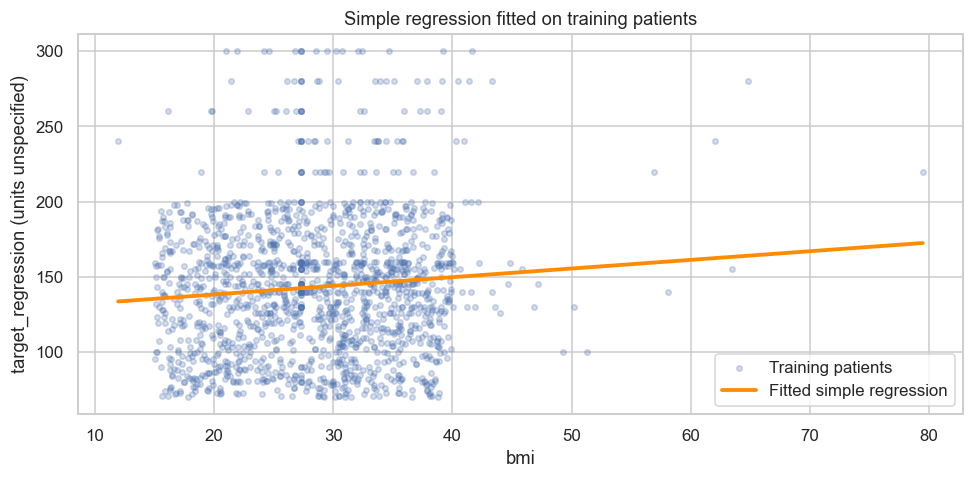

In [43]:
display(
    Markdown(
        "**Fitted simple regression:** "
        rf"$\widehat{{target\_regression}}={simple_model.intercept_:.4f}"
        rf"+{simple_model.coef_[0]:.4f}\,bmi$"
    )
)
print("Multiple regression intercept:", round(float(multiple_model.intercept_), 4))
regression_coefficient_table = pd.DataFrame(
    {"Encoded_column": X_train_multiple.columns, "Coefficient": multiple_model.coef_}
)
display(regression_coefficient_table.round(4))
regression_category_references = pd.DataFrame(
    [
        {
            "Original_feature": name,
            "Reference_category": sorted(df.loc[train_indices, name].unique())[0],
        }
        for name in selected_regression_features
        if name in categorical_features
    ]
)
display(regression_category_references)
bmi_grid = np.linspace(
    df.loc[train_indices, best_feature].min(), df.loc[train_indices, best_feature].max(), 200
)
bmi_line = simple_model.predict(pd.DataFrame({best_feature: bmi_grid}))
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.scatter(
    df.loc[train_indices, best_feature],
    y_regression.loc[train_indices],
    s=13,
    alpha=0.25,
    label="Training patients",
)
ax.plot(bmi_grid, bmi_line, color="darkorange", linewidth=2.5, label="Fitted simple regression")
ax.set(
    xlabel=best_feature,
    ylabel="target_regression (units unspecified)",
    title="Simple regression fitted on training patients",
)
ax.legend()
plt.tight_layout()
plt.show()


#### 4.4.2 Residual diagnostics

A residual is $e_i=y_i-\widehat y_i$. Residuals scattered around zero with similar spread
across fitted values would be compatible with a linear mean and constant error variance.
Curvature or changing spread warrants caution. Normality is not required to calculate the
prediction metrics. The orange points are mean residuals in eight equally populated fitted-value
bins. Bin standard deviations complement the plots. These are descriptive diagnostics, not
formal assumption tests, confidence intervals or independent validation scores.


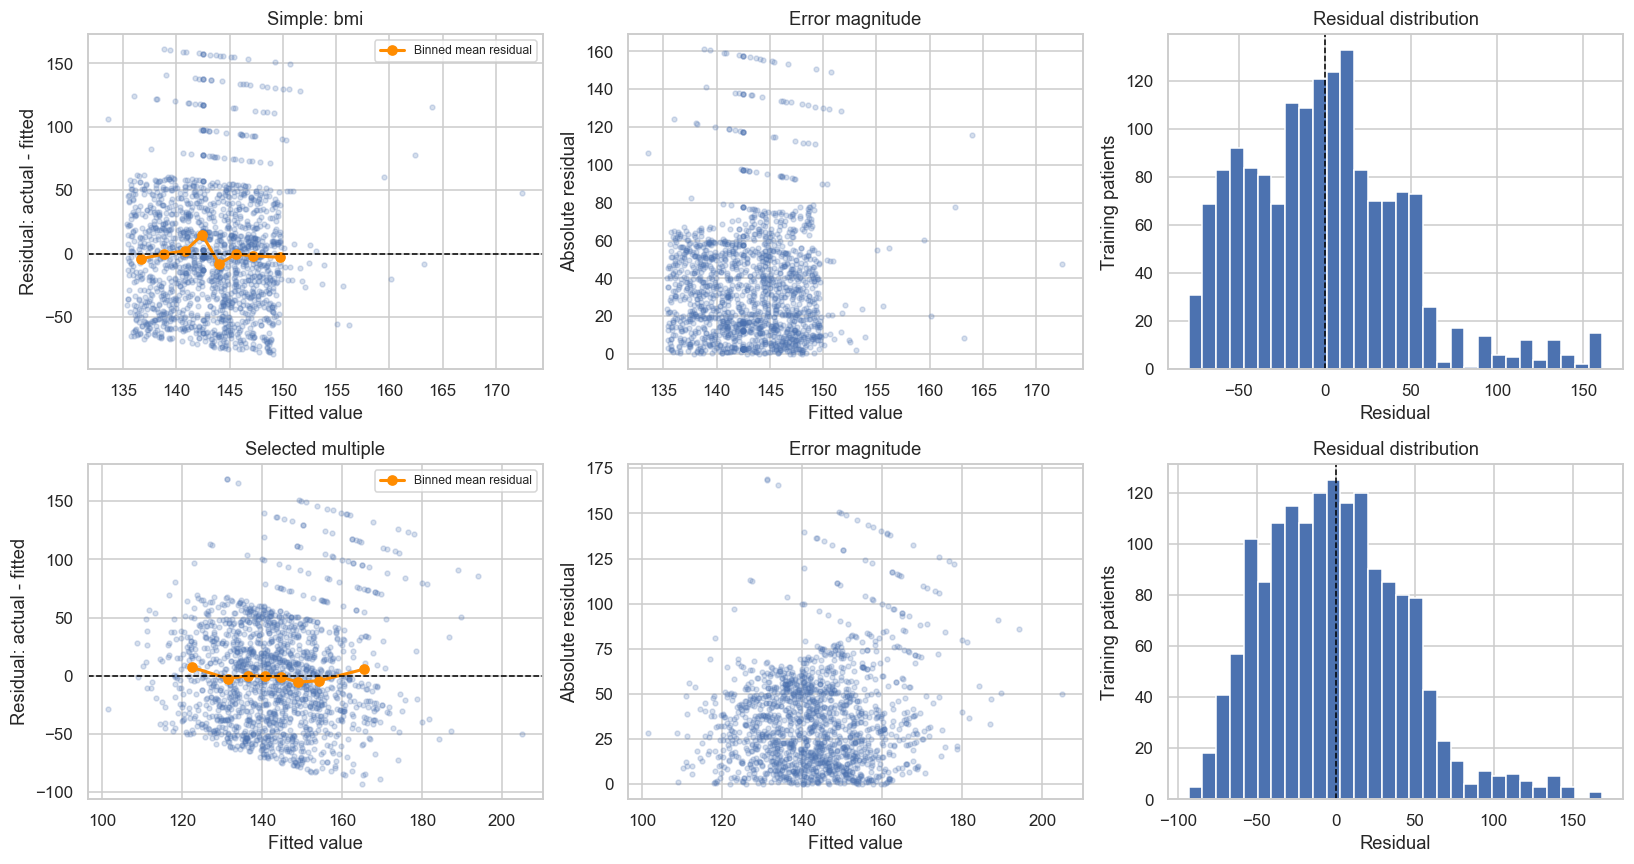

,Mean_residual,Training_RMSE,Residual_SD_min_bin,Residual_SD_max_bin,Largest_to_smallest_bin_SD
Model,,,,,
Simple: bmi,-0.0,45.9011,39.4599,52.6552,1.3344
Selected multiple,-0.0,44.2042,36.0612,57.1322,1.5843


,Model,Fitted_bin,N,Mean_fitted,Mean_residual,Residual_SD
0,Simple: bmi,"(133.603, 137.891]",202,136.6688,-4.0252,39.4599
1,Simple: bmi,"(137.891, 139.79]",199,138.8501,-0.1617,44.6104
2,Simple: bmi,"(139.79, 141.742]",199,140.8259,2.2947,41.3561
3,Simple: bmi,"(141.742, 143.142]",200,142.4298,14.8952,52.6552
4,Simple: bmi,"(143.142, 144.739]",204,144.0103,-8.0937,48.1086
5,Simple: bmi,"(144.739, 146.408]",197,145.5686,-0.2590,46.1300
6,Simple: bmi,"(146.408, 147.966]",199,147.1745,-1.6670,41.9469
7,Simple: bmi,"(147.966, 172.454]",200,149.6828,-2.7828,48.8145
8,Selected multiple,"(101.57799999999999, 128.198]",200,122.4855,7.3595,36.0612
9,Selected multiple,"(128.198, 134.238]",200,131.5114,-2.4314,40.6361


In [44]:
diagnostic_actual = y_regression.loc[train_indices].to_numpy()
diagnostic_fits = {
    "Simple: bmi": simple_model.predict(X_available.loc[train_indices, [best_feature]]),
    "Selected multiple": multiple_model.predict(X_train_multiple),
}
diagnostic_summary_rows = []
diagnostic_bin_tables = []
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for row_number, (name, fitted) in enumerate(diagnostic_fits.items()):
    residuals = diagnostic_actual - fitted
    diagnostic_frame = pd.DataFrame({"Fitted": fitted, "Residual": residuals})
    diagnostic_frame["Fitted_bin"] = pd.qcut(fitted, q=8, duplicates="drop")
    bins = (
        diagnostic_frame.groupby("Fitted_bin", observed=True)
        .agg(
            N=("Residual", "size"),
            Mean_fitted=("Fitted", "mean"),
            Mean_residual=("Residual", "mean"),
            Residual_SD=("Residual", "std"),
        )
        .reset_index()
    )
    bins.insert(0, "Model", name)
    diagnostic_bin_tables.append(bins)
    diagnostic_summary_rows.append(
        {
            "Model": name,
            "Mean_residual": residuals.mean(),
            "Training_RMSE": np.sqrt(np.mean(residuals**2)),
            "Residual_SD_min_bin": bins["Residual_SD"].min(),
            "Residual_SD_max_bin": bins["Residual_SD"].max(),
            "Largest_to_smallest_bin_SD": bins["Residual_SD"].max() / bins["Residual_SD"].min(),
        }
    )
    axes[row_number, 0].scatter(fitted, residuals, s=10, alpha=0.22)
    axes[row_number, 0].plot(
        bins["Mean_fitted"],
        bins["Mean_residual"],
        color="darkorange",
        marker="o",
        linewidth=2,
        label="Binned mean residual",
    )
    axes[row_number, 0].axhline(0, color="black", linestyle="--", linewidth=1)
    axes[row_number, 0].set(xlabel="Fitted value", ylabel="Residual: actual - fitted", title=name)
    axes[row_number, 0].legend(fontsize=8)
    axes[row_number, 1].scatter(fitted, np.abs(residuals), s=10, alpha=0.22)
    axes[row_number, 1].set(
        xlabel="Fitted value", ylabel="Absolute residual", title="Error magnitude"
    )
    axes[row_number, 2].hist(residuals, bins=30, edgecolor="white")
    axes[row_number, 2].axvline(0, color="black", linestyle="--", linewidth=1)
    axes[row_number, 2].set(
        xlabel="Residual", ylabel="Training patients", title="Residual distribution"
    )
plt.tight_layout()
plt.show()
regression_diagnostic_summary = pd.DataFrame(diagnostic_summary_rows).set_index("Model")
regression_diagnostic_bins = pd.concat(diagnostic_bin_tables, ignore_index=True)
display(regression_diagnostic_summary.round(4))
display(regression_diagnostic_bins.round(4))
assert np.allclose(regression_diagnostic_summary["Mean_residual"], 0, atol=1e-8)


In [45]:
simple_diagnostic_row = regression_diagnostic_summary.loc["Simple: bmi"]
multiple_diagnostic_row = regression_diagnostic_summary.loc["Selected multiple"]
display(
    Markdown(
        f"Across the eight fitted-value bins, residual SD ranges from "
        f'{simple_diagnostic_row["Residual_SD_min_bin"]:.2f} to '
        f'{simple_diagnostic_row["Residual_SD_max_bin"]:.2f} for simple regression '
        f'(largest/smallest ratio {simple_diagnostic_row["Largest_to_smallest_bin_SD"]:.2f}), '
        f'and from {multiple_diagnostic_row["Residual_SD_min_bin"]:.2f} to '
        f'{multiple_diagnostic_row["Residual_SD_max_bin"]:.2f} for multiple regression '
        f'(ratio {multiple_diagnostic_row["Largest_to_smallest_bin_SD"]:.2f}). '
        "The plots show large positive tail errors and departures of bin means from zero. "
        "These patterns are compatible with specification or variance limitations, but bins from "
        "one fitted sample do not establish population-level heteroscedasticity or a unique cause."
    )
)


Across the eight fitted-value bins, residual SD ranges from 39.46 to 52.66 for simple regression (largest/smallest ratio 1.33), and from 36.06 to 57.13 for multiple regression (ratio 1.58). The plots show large positive tail errors and departures of bin means from zero. These patterns are compatible with specification or variance limitations, but bins from one fitted sample do not establish population-level heteroscedasticity or a unique cause.

The fitted line captures only a weak association: patients with similar BMI can have widely
different target values. Large positive residuals indicate underprediction of some high targets.
Zero overall mean residual is a property of least squares with intercept, not evidence that
linearity or constant variance holds. Binned means and spreads must be read with the plots.
Possible patterns limit interpretation of the linear specification without changing the metric
definitions or establishing the cause of weak prediction. No patients are removed or model
choices revised from these residuals.

### 4.5 Test-Set Evaluation

These scores use the original 400 test patients, separately from the training diagnostics.
Model and feature choices remain based on training CV.


In [46]:
# Resultados da regressão no teste

# Comparação no teste
test_results = pd.DataFrame([
    {
        'Modelo': 'Baseline: média do treino',
        **regression_metrics(y_test, baseline_predictions)
    },
    {
        'Modelo': f'Simples: {best_feature}',
        **regression_metrics(y_test, simple_predictions)
    },
    {
        'Modelo': 'Múltipla: conjunto selecionado',
        **regression_metrics(y_test, multiple_predictions)
    }
]).set_index('Modelo')

display(test_results.round(4))

print(
    'Número de features originais na regressão múltipla:',
    len(selected_regression_features)
)
print(
    'Número de colunas após codificação:',
    X_train_multiple.shape[1]
)


,R2,MAE,RMSE
Modelo,,,
Baseline: média do treino,-0.0019,37.4721,49.2433
Simples: bmi,0.0214,37.1257,48.6671
Múltipla: conjunto selecionado,0.0570,37.2831,47.7733


Número de features originais na regressão múltipla: 27
Número de colunas após codificação: 37


### 4.6 Interpretation

Both regressions improved all three test metrics over the training-mean baseline. Multiple regression had the lowest RMSE (47.7733), approximately 3% below baseline, and the highest R² (0.0570), although predictive performance remained limited.

Simple regression with `bmi` had slightly lower MAE (37.1257 versus 37.2831). Multiple regression therefore did not outperform it on every metric.

The test comparison does not include full multiple regression, so it cannot isolate the effect of exclusions. Selection was based on training CV; the previously inspected test remains exploratory.


## 5. Classification Models

Logistic regression and linear discriminant analysis (LDA) predict `target_class`. Macro F1 is the main criterion under class imbalance, supported by accuracy and per-class precision, recall, and F1.

### 5.1 Initial Cross-Validation Comparison

Both models and a majority-class baseline use identical stratified CV5 splits with three repetitions. All features remaining after initial EDA exclusions are included. Encoding and numerical standardisation are fitted within each fold.

No class weights or further exclusions are applied. Logistic regression uses L2 regularisation with `C=1`; LDA assumes a common within-class covariance matrix.


In [47]:
# Configuração da CV5

y_classification = df['target_class']

cv_classification = RepeatedStratifiedKFold(
    n_splits=5,
    n_repeats=3,
    random_state=RANDOM_STATE
)


In [48]:
# Treino e avaliação dos classificadores

classification_fold_results = []

for fold, (train_positions, validation_positions) in enumerate(
    cv_classification.split(
        train_indices,
        y_classification.loc[train_indices]
    ),
    start=1
):
    fold_train = train_indices[train_positions]
    fold_validation = train_indices[validation_positions]

    X_train, X_validation = prepare_features(
        fold_train,
        fold_validation,
        scaling='numeric'
    )

    y_train = y_classification.loc[fold_train]
    y_validation = y_classification.loc[fold_validation]

    models = {
        'Baseline: classe mais frequente': DummyClassifier(
            strategy='most_frequent'
        ),
        'Regressão logística': LogisticRegression(
            C=1,
            max_iter=3000,
            random_state=RANDOM_STATE
        ),
        'LDA': LinearDiscriminantAnalysis()
    }

    for model_name, model in models.items():
        model.fit(X_train, y_train)
        predictions = model.predict(X_validation)

        report = classification_report(
            y_validation,
            predictions,
            labels=CLASS_ORDER,
            output_dict=True,
            zero_division=0
        )

        row = {
            'Modelo': model_name,
            'Fold': fold,
            'Accuracy': accuracy_score(y_validation, predictions),
            'F1_macro': report['macro avg']['f1-score']
        }

        for class_name in CLASS_ORDER:
            row[f'Precision_{class_name}'] = (
                report[class_name]['precision']
            )
            row[f'Recall_{class_name}'] = (
                report[class_name]['recall']
            )
            row[f'F1_{class_name}'] = (
                report[class_name]['f1-score']
            )

        classification_fold_results.append(row)


In [49]:
# Resumo da CV5

classification_fold_results = pd.DataFrame(
    classification_fold_results
)

classification_cv_summary = (
    classification_fold_results.groupby('Modelo')
    .agg(
        Accuracy_media=('Accuracy', 'mean'),
        F1_macro_medio=('F1_macro', 'mean'),
        F1_macro_desvio_padrao=('F1_macro', 'std'),
        Precision_DI=('Precision_DI', 'mean'),
        Recall_DI=('Recall_DI', 'mean'),
        Precision_HT_HY=('Precision_HT_HY', 'mean'),
        Recall_HT_HY=('Recall_HT_HY', 'mean'),
        Precision_DI_HT_HY=('Precision_DI_HT_HY', 'mean'),
        Recall_DI_HT_HY=('Recall_DI_HT_HY', 'mean')
    )
    .sort_values('F1_macro_medio', ascending=False)
)

display(classification_cv_summary.round(4))


,Accuracy_media,F1_macro_medio,F1_macro_desvio_padrao,Precision_DI,Recall_DI,Precision_HT_HY,Recall_HT_HY,Precision_DI_HT_HY,Recall_DI_HT_HY
Modelo,,,,,,,,,
Regressão logística,0.9277,0.5675,0.0283,0.9376,0.9880,0.7993,0.6438,0.1333,0.0190
LDA,0.9210,0.5658,0.0309,0.9387,0.9799,0.7463,0.6438,0.1029,0.0341
Baseline: classe mais frequente,0.9019,0.3161,0.0003,0.9019,1.0000,0.0000,0.0000,0.0000,0.0000


Logistic regression had slightly higher mean macro F1 than LDA (0.5675 versus 0.5658), making it the provisional reference without demonstrating robust superiority.

- Both models had approximately 94% precision and over 97% recall for `DI`.
- For `HT_HY`, both had 64.38% recall; precision was 79.93% for logistic regression and 74.63% for LDA.
- For `DI_HT_HY`, recall was only 1.90% and 3.41%, with precision of 13.33% and 10.29%, respectively.

The baseline achieved 90.19% accuracy while identifying no minority cases. Metrics are averaged over 15 evaluations; undefined precision is assigned zero using `zero_division=0`.


#### 5.1.1 Checking the common-covariance assumption of LDA

LDA assumes class-conditional Gaussian distributions with one common covariance matrix.
Equal variances for each individual feature are necessary, but not sufficient: cross-feature
covariances must also match. We quantify the differences visible in EDA using training patients
only. These illustrative measurements do not define a new feature-selection rule.
Small-class estimates have uncertainty; categorical dummies also do not follow continuous Gaussian distributions.


target_class
DI          1443
HT_HY         89
DI_HT_HY      68
Name: Training patients, dtype: int64

target_class,DI,HT_HY,DI_HT_HY,DI / HT_HY,DI / DI_HT_HY
systolic_bp,501.303,0.562,0.674,891.256,743.282
diastolic_bp,232.634,0.184,0.146,1264.726,1590.242
alcohol_intake,59.323,0.061,0.059,969.683,1002.193
salt_intake,10.443,0.014,0.013,753.933,781.224
heart_rate,147.189,0.143,0.117,1031.395,1262.508
hdl,308.590,0.166,0.309,1857.873,997.581
ldl,957.080,1.348,0.825,709.853,1159.484


,"Cov(systolic_bp, diastolic_bp)","Cov(hdl, ldl)"
Class,,
DI,-5.0293,20.9147
HT_HY,0.0355,-0.0896
DI_HT_HY,0.0351,0.1730


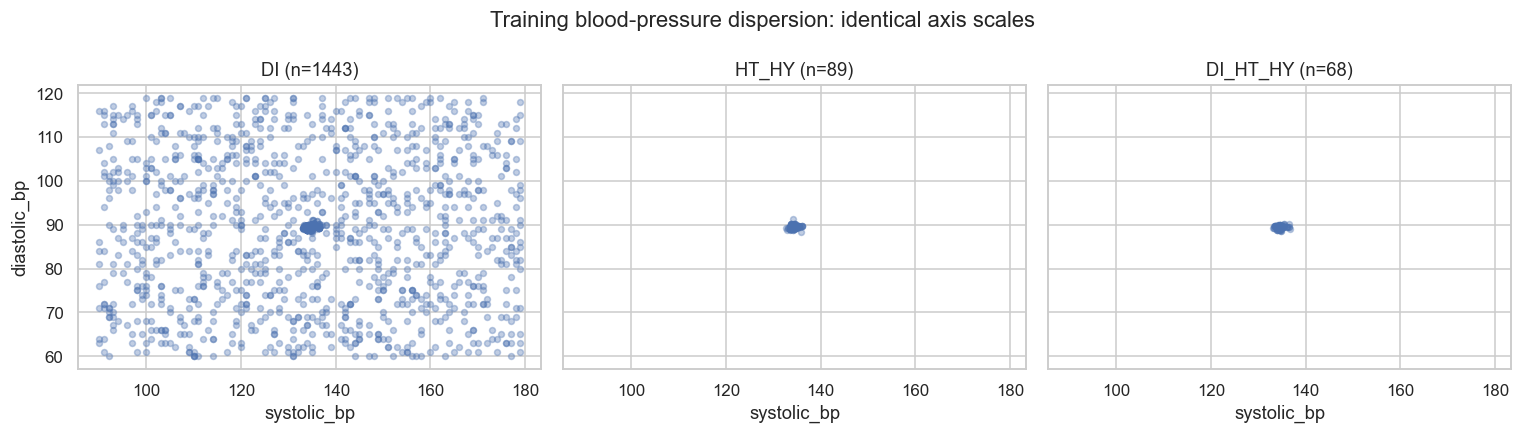

DI sample variances are **710 to 1858 times** the corresponding minority-class variances for these measurements. The common-covariance assumption is poorly supported by these training distributions. This is descriptive evidence, not a formal population equality test.

In [50]:
lda_diagnostic_features = [
    "systolic_bp",
    "diastolic_bp",
    "alcohol_intake",
    "salt_intake",
    "heart_rate",
    "hdl",
    "ldl",
]
lda_training_data = df.loc[train_indices]
lda_class_counts = lda_training_data["target_class"].value_counts().reindex(CLASS_ORDER)
lda_variances = (
    lda_training_data.groupby("target_class")[lda_diagnostic_features]
    .var(ddof=1)
    .reindex(CLASS_ORDER)
    .T
)
lda_variance_comparison = lda_variances.copy()
lda_variance_comparison["DI / HT_HY"] = lda_variances["DI"] / lda_variances["HT_HY"]
lda_variance_comparison["DI / DI_HT_HY"] = lda_variances["DI"] / lda_variances["DI_HT_HY"]
display(lda_class_counts.rename("Training patients"))
display(lda_variance_comparison.round(3))
lda_covariance_rows = []
for class_name in CLASS_ORDER:
    class_frame = lda_training_data.loc[lda_training_data["target_class"] == class_name]
    lda_covariance_rows.append(
        {
            "Class": class_name,
            "Cov(systolic_bp, diastolic_bp)": class_frame["systolic_bp"].cov(
                class_frame["diastolic_bp"]
            ),
            "Cov(hdl, ldl)": class_frame["hdl"].cov(class_frame["ldl"]),
        }
    )
lda_covariance_comparison = pd.DataFrame(lda_covariance_rows).set_index("Class")
display(lda_covariance_comparison.round(4))
fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharex=True, sharey=True)
for ax, class_name in zip(axes, CLASS_ORDER):
    class_frame = lda_training_data.loc[lda_training_data["target_class"] == class_name]
    ax.scatter(class_frame["systolic_bp"], class_frame["diastolic_bp"], s=15, alpha=0.35)
    ax.set(title=f"{class_name} (n={len(class_frame)})", xlabel="systolic_bp")
axes[0].set_ylabel("diastolic_bp")
fig.suptitle("Training blood-pressure dispersion: identical axis scales")
plt.tight_layout()
plt.show()
ratio_min = lda_variance_comparison[["DI / HT_HY", "DI / DI_HT_HY"]].min().min()
ratio_max = lda_variance_comparison[["DI / HT_HY", "DI / DI_HT_HY"]].max().max()
display(
    Markdown(
        f"DI sample variances are **{ratio_min:.0f} to {ratio_max:.0f} times** the corresponding "
        "minority-class variances for these measurements. The common-covariance assumption is "
        "poorly supported by these training distributions. This is descriptive evidence, not a formal population equality test."
    )
)


LDA can still be fitted and evaluated for the assignment when its generative assumptions appear
poorly matched. This is a plausible limitation, but it is not demonstrated to cause low DI_HT_HY
recall. Imbalance, few minority patients and overlap can also affect recognition. Logistic
regression does not require common covariance, yet also struggles with this class.

A common rescaling of a feature would not remove its between-class variance ratios.
These diagnostics retain the original LDA settings and predictions. They do not introduce
adjusted priors, covariance shrinkage, QDA or patient exclusions.


### 5.2 Internal Holdout

A stratified 80/20 split of the training set provides 1,280 fitting and 320 validation patients. The baseline, logistic regression, and LDA share this split and the previous features and preprocessing.

The original test set is excluded. A single split provides no estimate of between-split standard deviation.


In [51]:
# Preparação do holdout interno

# Divisão apenas dentro dos 1 600 pacientes de treino
holdout_train, holdout_validation = train_test_split(
    train_indices,
    test_size=0.2,
    stratify=y_classification.loc[train_indices],
    random_state=RANDOM_STATE
)

X_holdout_train, X_holdout_validation = prepare_features(
    holdout_train,
    holdout_validation,
    scaling='numeric'
)

y_holdout_train = y_classification.loc[holdout_train]
y_holdout_validation = y_classification.loc[holdout_validation]

holdout_models = {
    'Baseline: classe mais frequente': DummyClassifier(
        strategy='most_frequent'
    ),
    'Regressão logística': LogisticRegression(
        C=1,
        max_iter=3000,
        random_state=RANDOM_STATE
    ),
    'LDA': LinearDiscriminantAnalysis()
}


In [52]:
# Treino e avaliação no holdout

holdout_results = []

for model_name, model in holdout_models.items():
    model.fit(X_holdout_train, y_holdout_train)
    predictions = model.predict(X_holdout_validation)

    report = classification_report(
        y_holdout_validation,
        predictions,
        labels=CLASS_ORDER,
        output_dict=True,
        zero_division=0
    )

    row = {
        'Modelo': model_name,
        'Accuracy': accuracy_score(
            y_holdout_validation, predictions
        ),
        'F1_macro': report['macro avg']['f1-score']
    }

    for class_name in CLASS_ORDER:
        row[f'Precision_{class_name}'] = (
            report[class_name]['precision']
        )
        row[f'Recall_{class_name}'] = (
            report[class_name]['recall']
        )
        row[f'F1_{class_name}'] = (
            report[class_name]['f1-score']
        )

    holdout_results.append(row)


In [53]:
# Resultados do holdout

holdout_results = pd.DataFrame(
    holdout_results
).set_index('Modelo')

print('Pacientes para ajuste:', len(holdout_train))
print('Pacientes para validação:', len(holdout_validation))

display(holdout_results.round(4))


Pacientes para ajuste: 1280
Pacientes para validação: 320


,Accuracy,F1_macro,Precision_DI,Recall_DI,F1_DI,Precision_HT_HY,Recall_HT_HY,F1_HT_HY,Precision_DI_HT_HY,Recall_DI_HT_HY,F1_DI_HT_HY
Modelo,,,,,,,,,,,
Baseline: classe mais frequente,0.9000,0.3158,0.9000,1.0000,0.9474,0.0,0.0000,0.0000,0.0,0.0,0.0
Regressão logística,0.9281,0.5871,0.9344,0.9896,0.9612,1.0,0.6667,0.8000,0.0,0.0,0.0
LDA,0.9062,0.5075,0.9246,0.9792,0.9511,0.8,0.4444,0.5714,0.0,0.0,0.0


Logistic regression achieved macro F1 of 0.5871, compared with 0.5075 for LDA and 0.3158 for the baseline.

For `HT_HY`, logistic regression had precision/recall of 1.0000/0.6667, versus 0.8000/0.4444 for LDA. Both models had zero recall and F1 for `DI_HT_HY`.

These results depend on one validation split of 320 patients and do not establish general superiority. High accuracy still conceals poor minority-class recognition.


### 5.3 Ten-Fold Cross-Validation

The same models are assessed using stratified CV10 with three repetitions, retaining the CV5 features, parameters, and preprocessing fitted within each fold.

Mean scores and standard deviations are compared with CV5. Evaluations share observations, so their dispersion does not represent independent estimates.


In [54]:
# Configuração da CV10

cv10_classification = RepeatedStratifiedKFold(
    n_splits=10,
    n_repeats=3,
    random_state=RANDOM_STATE
)


In [55]:
# Treino e avaliação na CV10

cv10_results = []

for fold, (train_positions, validation_positions) in enumerate(
    cv10_classification.split(
        train_indices,
        y_classification.loc[train_indices]
    ),
    start=1
):
    fold_train = train_indices[train_positions]
    fold_validation = train_indices[validation_positions]

    X_train, X_validation = prepare_features(
        fold_train,
        fold_validation,
        scaling='numeric'
    )

    y_train = y_classification.loc[fold_train]
    y_validation = y_classification.loc[fold_validation]

    models = {
        'Baseline: classe mais frequente': DummyClassifier(
            strategy='most_frequent'
        ),
        'Regressão logística': LogisticRegression(
            C=1,
            max_iter=3000,
            random_state=RANDOM_STATE
        ),
        'LDA': LinearDiscriminantAnalysis()
    }

    for model_name, model in models.items():
        model.fit(X_train, y_train)
        predictions = model.predict(X_validation)

        report = classification_report(
            y_validation,
            predictions,
            labels=CLASS_ORDER,
            output_dict=True,
            zero_division=0
        )

        row = {
            'Modelo': model_name,
            'Fold': fold,
            'Accuracy': accuracy_score(y_validation, predictions),
            'F1_macro': report['macro avg']['f1-score']
        }

        for class_name in CLASS_ORDER:
            row[f'Precision_{class_name}'] = (
                report[class_name]['precision']
            )
            row[f'Recall_{class_name}'] = (
                report[class_name]['recall']
            )
            row[f'F1_{class_name}'] = (
                report[class_name]['f1-score']
            )

        cv10_results.append(row)


In [56]:
# Comparação CV5 e CV10

cv10_fold_results = pd.DataFrame(cv10_results)

# Juntar os resultados de CV5 e CV10
cv_comparison_folds = pd.concat([
    classification_fold_results.assign(Metodo='CV5'),
    cv10_fold_results.assign(Metodo='CV10')
], ignore_index=True)

cv_comparison = (
    cv_comparison_folds.groupby(['Metodo', 'Modelo'])
    .agg(
        Accuracy_media=('Accuracy', 'mean'),
        Accuracy_desvio_padrao=('Accuracy', 'std'),
        F1_macro_medio=('F1_macro', 'mean'),
        F1_macro_desvio_padrao=('F1_macro', 'std'),
        Precision_DI=('Precision_DI', 'mean'),
        Recall_DI=('Recall_DI', 'mean'),
        Precision_HT_HY=('Precision_HT_HY', 'mean'),
        Recall_HT_HY=('Recall_HT_HY', 'mean'),
        Precision_DI_HT_HY=('Precision_DI_HT_HY', 'mean'),
        Recall_DI_HT_HY=('Recall_DI_HT_HY', 'mean')
    )
)

display(cv_comparison.round(4))


Accuracy_media  \
Metodo Modelo                                            
CV10   Baseline: classe mais frequente          0.9019   
       LDA                                      0.9244   
       Regressão logística                      0.9294   
CV5    Baseline: classe mais frequente          0.9019   
       LDA                                      0.9210   
       Regressão logística                      0.9277   

                                        Accuracy_desvio_padrao  \
Metodo Modelo                                                    
CV10   Baseline: classe mais frequente                  0.0029   
       LDA                                              0.0136   
       Regressão logística                              0.0095   
CV5    Baseline: classe mais frequente                  0.0016   
       LDA                                              0.0079   
       Regressão logística                              0.0067   

                                        F1_macro_medio  \
Metodo Modelo                                            
CV10   Baseline: classe mais frequente          0.3161   
       LDA                                      0.5703   
       Regressão logística                      0.5680   
CV5    Baseline: classe mais frequente          0.3161   
       LDA                                      0.5658   
       Regressão logística                      0.5675   

                                        F1_macro_desvio_padrao  Precision_DI  \
Metodo Modelo                                                                  
CV10   Baseline: classe mais frequente                  0.0005        0.9019   
       LDA                                              0.0616        0.9408   
       Regressão logística                              0.0482        0.9381   
CV5    Baseline: classe mais frequente                  0.0003        0.9019   
       LDA                                              0.0309        0.9387   
       Regressão logística                              0.0283        0.9376   

                                        Recall_DI  Precision_HT_HY  \
Metodo Modelo                                                        
CV10   Baseline: classe mais frequente     1.0000           0.0000   
       LDA                                 0.9820           0.7638   
       Regressão logística                 0.9894           0.8306   
CV5    Baseline: classe mais frequente     1.0000           0.0000   
       LDA                                 0.9799           0.7463   
       Regressão logística                 0.9880           0.7993   

                                        Recall_HT_HY  Precision_DI_HT_HY  \
Metodo Modelo                                                              
CV10   Baseline: classe mais frequente        0.0000              0.0000   
       LDA                                    0.6745              0.1167   
       Regressão logística                    0.6565              0.0611   
CV5    Baseline: classe mais frequente        0.0000              0.0000   
       LDA                                    0.6438              0.1029   
       Regressão logística                    0.6438              0.1333   

                                        Recall_DI_HT_HY  
Metodo Modelo                                            
CV10   Baseline: classe mais frequente           0.0000  
       LDA                                       0.0286  
       Regressão logística                       0.0143  
CV5    Baseline: classe mais frequente           0.0000  
       LDA                                       0.0341  
       Regressão logística                       0.0190

Mean macro F1 was similar across CV5 and CV10: logistic regression ranked slightly higher in CV5, while LDA ranked slightly higher in CV10. These small differences do not establish robust superiority.

CV10 showed greater macro F1 and accuracy dispersion in both models. Validation folds contain 160 rather than 320 patients, with fewer minority cases, which may contribute to fluctuations. This does not establish that CV10 always has greater variance.

`DI_HT_HY` recognition remained poor. CV5 remains the comparison protocol; CV10 provides a complementary stability assessment.


### 5.4 Leave-One-Out Cross-Validation (LOOCV)

Each model is fitted on 1,599 training patients and predicts the remaining patient, repeating this process for all 1,600. Encoding and scaling are fitted within each iteration.

Class metrics are calculated from pooled out-of-fold predictions, rather than separately for single-patient folds. The original test set is excluded.


In [57]:
# Configuração do LOOCV

loo = LeaveOneOut()

loo_predictions = {
    'Baseline: classe mais frequente': [],
    'Regressão logística': [],
    'LDA': []
}

loo_actual = []


In [58]:
# Previsões fora do treino no LOOCV

for iteration, (train_positions, validation_positions) in enumerate(
    loo.split(train_indices),
    start=1
):
    fold_train = train_indices[train_positions]
    fold_validation = train_indices[validation_positions]

    X_train, X_validation = prepare_features(
        fold_train,
        fold_validation,
        scaling='numeric'
    )

    y_train = y_classification.loc[fold_train]
    y_validation = y_classification.loc[fold_validation]

    models = {
        'Baseline: classe mais frequente': DummyClassifier(
            strategy='most_frequent'
        ),
        'Regressão logística': LogisticRegression(
            C=1,
            max_iter=3000,
            random_state=RANDOM_STATE
        ),
        'LDA': LinearDiscriminantAnalysis()
    }

    loo_actual.append(y_validation.iloc[0])

    for model_name, model in models.items():
        model.fit(X_train, y_train)
        prediction = model.predict(X_validation)[0]
        loo_predictions[model_name].append(prediction)

    if iteration % 200 == 0:
        print(f'Concluídas {iteration} de {len(train_indices)} iterações')


Concluídas 200 de 1600 iterações
Concluídas 400 de 1600 iterações
Concluídas 600 de 1600 iterações
Concluídas 800 de 1600 iterações
Concluídas 1000 de 1600 iterações
Concluídas 1200 de 1600 iterações
Concluídas 1400 de 1600 iterações
Concluídas 1600 de 1600 iterações


In [59]:
# Métricas das previsões reunidas

# Calcular as métricas nas 1 600 previsões reunidas
loo_rows = []

for model_name, predictions in loo_predictions.items():
    report = classification_report(
        loo_actual,
        predictions,
        labels=CLASS_ORDER,
        output_dict=True,
        zero_division=0
    )

    row = {
        'Modelo': model_name,
        'Accuracy': accuracy_score(loo_actual, predictions),
        'F1_macro': report['macro avg']['f1-score']
    }

    for class_name in CLASS_ORDER:
        row[f'Precision_{class_name}'] = (
            report[class_name]['precision']
        )
        row[f'Recall_{class_name}'] = (
            report[class_name]['recall']
        )
        row[f'F1_{class_name}'] = (
            report[class_name]['f1-score']
        )

    loo_rows.append(row)

loo_results = pd.DataFrame(loo_rows).set_index('Modelo')

display(loo_results.round(4))


,Accuracy,F1_macro,Precision_DI,Recall_DI,F1_DI,Precision_HT_HY,Recall_HT_HY,F1_HT_HY,Precision_DI_HT_HY,Recall_DI_HT_HY,F1_DI_HT_HY
Modelo,,,,,,,,,,,
Baseline: classe mais frequente,0.9019,0.3161,0.9019,1.0000,0.9484,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
Regressão logística,0.9300,0.5758,0.9382,0.9896,0.9632,0.8310,0.6629,0.7375,0.1429,0.0147,0.0267
LDA,0.9250,0.5669,0.9397,0.9834,0.9611,0.7595,0.6742,0.7143,0.0909,0.0147,0.0253


Logistic regression achieved accuracy of 0.9300 and macro F1 of 0.5758, versus 0.9250 and 0.5669 for LDA.

For `HT_HY`, logistic regression had precision of 0.8310; LDA had slightly higher recall (0.6742 versus 0.6629). Both identified only one of 68 `DI_HT_HY` cases (recall 0.0147), with precision of 0.1429 and 0.0909, respectively.

Metrics use all 1,600 pooled predictions. No per-fold macro F1 standard deviation is reported because each validation fold contains one patient.


### 5.5 Bootstrap with Out-of-Bag Evaluation

Each iteration samples 1,600 training observations with replacement. Both models use the same sampled patients and are evaluated only on unsampled, out-of-bag (OOB) patients. Encoding and scaling are fitted on the bootstrap sample.

Means and standard deviations summarise 200 iterations. This is an evaluation procedure, not a class-balancing method; the original test set is excluded.


In [60]:
# Configuração do bootstrap

B = 200
rng = np.random.default_rng(RANDOM_STATE)

all_positions = np.arange(len(train_indices))
bootstrap_rows = []


In [61]:
# Amostragem, ajuste e avaliação out-of-bag

for iteration in range(B):
    # Sortear posições com reposição, como no exemplo da aula
    in_bag_positions = rng.choice(
        all_positions,
        size=len(train_indices),
        replace=True
    )

    # Posições que não foram sorteadas
    oob_positions = np.setdiff1d(
        all_positions,
        in_bag_positions
    )

    if len(oob_positions) == 0:
        continue

    in_bag_indices = train_indices[in_bag_positions]
    oob_indices = train_indices[oob_positions]

    X_train, X_oob = prepare_features(
        in_bag_indices,
        oob_indices,
        scaling='numeric'
    )

    y_train = y_classification.loc[in_bag_indices]
    y_oob = y_classification.loc[oob_indices]

    models = {
        'Baseline: classe mais frequente': DummyClassifier(
            strategy='most_frequent'
        ),
        'Regressão logística': LogisticRegression(
            C=1,
            max_iter=3000,
            random_state=RANDOM_STATE
        ),
        'LDA': LinearDiscriminantAnalysis()
    }

    for model_name, model in models.items():
        model.fit(X_train, y_train)
        predictions = model.predict(X_oob)

        report = classification_report(
            y_oob,
            predictions,
            labels=CLASS_ORDER,
            output_dict=True,
            zero_division=0
        )

        row = {
            'Modelo': model_name,
            'Iteracao': iteration + 1,
            'N_OOB': len(oob_indices),
            'Accuracy': accuracy_score(y_oob, predictions),
            'F1_macro': report['macro avg']['f1-score']
        }

        for class_name in CLASS_ORDER:
            row[f'Precision_{class_name}'] = (
                report[class_name]['precision']
            )
            row[f'Recall_{class_name}'] = (
                report[class_name]['recall']
            )
            row[f'F1_{class_name}'] = (
                report[class_name]['f1-score']
            )

        bootstrap_rows.append(row)

    if (iteration + 1) % 50 == 0:
        print(f'Concluídas {iteration + 1} de {B} iterações')


Concluídas 50 de 200 iterações
Concluídas 100 de 200 iterações
Concluídas 150 de 200 iterações
Concluídas 200 de 200 iterações


In [62]:
# Resumo do bootstrap

bootstrap_fold_results = pd.DataFrame(bootstrap_rows)

bootstrap_summary = (
    bootstrap_fold_results.groupby('Modelo')
    .agg(
        Iteracoes=('Iteracao', 'count'),
        Accuracy_media=('Accuracy', 'mean'),
        Accuracy_desvio_padrao=('Accuracy', 'std'),
        F1_macro_medio=('F1_macro', 'mean'),
        F1_macro_desvio_padrao=('F1_macro', 'std'),
        Precision_DI=('Precision_DI', 'mean'),
        Recall_DI=('Recall_DI', 'mean'),
        Precision_HT_HY=('Precision_HT_HY', 'mean'),
        Recall_HT_HY=('Recall_HT_HY', 'mean'),
        Precision_DI_HT_HY=('Precision_DI_HT_HY', 'mean'),
        Recall_DI_HT_HY=('Recall_DI_HT_HY', 'mean')
    )
)

display(bootstrap_summary.round(4))


,Iteracoes,Accuracy_media,Accuracy_desvio_padrao,F1_macro_medio,F1_macro_desvio_padrao,Precision_DI,Recall_DI,Precision_HT_HY,Recall_HT_HY,Precision_DI_HT_HY,Recall_DI_HT_HY
Modelo,,,,,,,,,,,
Baseline: classe mais frequente,200,0.9017,0.0099,0.3161,0.0018,0.9017,1.0000,0.0000,0.0000,0.0000,0.0000
LDA,200,0.9182,0.0098,0.5743,0.0327,0.9380,0.9777,0.7424,0.6029,0.2206,0.0747
Regressão logística,200,0.9250,0.0091,0.5725,0.0298,0.9374,0.9851,0.7809,0.6313,0.2202,0.0399


LDA had slightly higher mean macro F1 than logistic regression (0.5743 versus 0.5725), without evidence of robust superiority. Logistic regression had higher accuracy (0.9250 versus 0.9182) and better precision and recall for `HT_HY`.

`DI_HT_HY` recall remained low: 0.0747 for LDA and 0.0399 for logistic regression, with precision near 0.22 for both. Macro F1 standard deviations were 0.0327 and 0.0298, respectively.

Bootstrap iterations share patients and differ from CV in effective fitting and evaluation sizes, limiting direct comparisons.


### 5.6 Resampling Comparison and Variability

All methods assess the unweighted references with the initial feature set and training patients only. CV and bootstrap report mean scores and standard deviations (SD); holdout reports one split, while LOOCV uses pooled predictions.

| Method | Model | Accuracy | Accuracy SD | Macro F1 | Macro F1 SD | Recall DI_HT_HY |
|---|---|---:|---:|---:|---:|---:|
| Internal holdout | Logistic regression | 0.9281 | — | 0.5871 | — | 0.0000 |
| Internal holdout | LDA | 0.9062 | — | 0.5075 | — | 0.0000 |
| CV5, 3 repetitions | Logistic regression | 0.9277 | 0.0067 | 0.5675 | 0.0283 | 0.0190 |
| CV5, 3 repetitions | LDA | 0.9210 | 0.0079 | 0.5658 | 0.0309 | 0.0341 |
| CV10, 3 repetitions | Logistic regression | 0.9294 | 0.0095 | 0.5680 | 0.0482 | 0.0143 |
| CV10, 3 repetitions | LDA | 0.9244 | 0.0136 | 0.5703 | 0.0616 | 0.0286 |
| LOOCV | Logistic regression | 0.9300 | — | 0.5758 | — | 0.0147 |
| LOOCV | LDA | 0.9250 | — | 0.5669 | — | 0.0147 |
| Bootstrap OOB, 200 iterations | Logistic regression | 0.9250 | 0.0091 | 0.5725 | 0.0298 | 0.0399 |
| Bootstrap OOB, 200 iterations | LDA | 0.9182 | 0.0098 | 0.5743 | 0.0327 | 0.0747 |

Both models exceed baseline macro F1 of approximately 0.316, but `DI_HT_HY` recall remains low. Small ranking changes across methods do not establish general model superiority.

- **Holdout:** one split provides no between-split dispersion estimate; missing SD does not mean zero variance.
- **CV5/CV10:** CV10 has greater score dispersion here, with 160 rather than 320 validation patients per fold. Fitting sets also differ: 1,440 versus 1,280 patients. This is not a universal variance ranking.
- **LOOCV:** each fit uses 1,599 patients. Strongly overlapping fitting sets and single-patient validation folds preclude interpreting pooled metrics as independent fold scores.
- **Bootstrap OOB:** samples contain approximately 63.2% distinct patients on average, leaving approximately 36.8% for evaluation. Variable sample sizes and overlap limit comparisons with CV.

Score SDs describe dependent evaluations, not confidence intervals or the variance of the mean performance estimator. CV5 with three repetitions remains the protocol for subsequent configuration comparisons.


### 5.7 Classification Feature-Set Comparisons

The three regression exclusions are assessed separately for classification: `low_hdl_cholesterol`, `plasma_value`, and `ldl_alternative`, individually and jointly.

Unweighted logistic regression and LDA retain the same parameters, preprocessing, and 15 stratified CV5 evaluations. Macro F1 is the main criterion, supported by per-class precision and recall.

Candidates were motivated by earlier analyses of this dataset, making the comparison exploratory. The original test set is excluded.


In [63]:
# Conjuntos de features e folds

classification_exclusions = {
    'Todas as disponíveis': [],
    'Sem low_hdl_cholesterol': ['low_hdl_cholesterol'],
    'Sem plasma_value': ['plasma_value'],
    'Sem ldl_alternative': ['ldl_alternative'],
    'Sem as três': [
        'low_hdl_cholesterol',
        'plasma_value',
        'ldl_alternative'
    ]
}

# Fixar as mesmas 15 divisões para todos os conjuntos e modelos
classification_splits = list(
    cv_classification.split(
        train_indices,
        y_classification.loc[train_indices]
    )
)


In [64]:
# Comparação dos classificadores por conjunto

classification_exclusion_rows = []

for group_name, removed_features in classification_exclusions.items():
    selected_features = [
        feature for feature in X_available.columns
        if feature not in removed_features
    ]

    for fold, (train_positions, validation_positions) in enumerate(
        classification_splits, start=1
    ):
        fold_train = train_indices[train_positions]
        fold_validation = train_indices[validation_positions]

        X_train, X_validation = prepare_features(
            fold_train,
            fold_validation,
            features=selected_features,
            scaling='numeric'
        )

        y_train = y_classification.loc[fold_train]
        y_validation = y_classification.loc[fold_validation]

        models = {
            'Regressão logística': LogisticRegression(
                C=1,
                max_iter=3000,
                random_state=RANDOM_STATE
            ),
            'LDA': LinearDiscriminantAnalysis()
        }

        for model_name, model in models.items():
            model.fit(X_train, y_train)
            predictions = model.predict(X_validation)

            report = classification_report(
                y_validation,
                predictions,
                labels=CLASS_ORDER,
                output_dict=True,
                zero_division=0
            )

            row = {
                'Modelo': model_name,
                'Conjunto': group_name,
                'Fold': fold,
                'Accuracy': accuracy_score(
                    y_validation, predictions
                ),
                'F1_macro': report['macro avg']['f1-score']
            }

            for class_name in CLASS_ORDER:
                row[f'Precision_{class_name}'] = (
                    report[class_name]['precision']
                )
                row[f'Recall_{class_name}'] = (
                    report[class_name]['recall']
                )
                row[f'F1_{class_name}'] = (
                    report[class_name]['f1-score']
                )

            classification_exclusion_rows.append(row)


In [65]:
# Resumo das exclusões na classificação

classification_exclusion_folds = pd.DataFrame(
    classification_exclusion_rows
)

classification_exclusion_summary = (
    classification_exclusion_folds.groupby(['Modelo', 'Conjunto'])
    .agg(
        Accuracy_media=('Accuracy', 'mean'),
        F1_macro_medio=('F1_macro', 'mean'),
        F1_macro_desvio_padrao=('F1_macro', 'std'),
        Precision_DI=('Precision_DI', 'mean'),
        Recall_DI=('Recall_DI', 'mean'),
        Precision_HT_HY=('Precision_HT_HY', 'mean'),
        Recall_HT_HY=('Recall_HT_HY', 'mean'),
        Precision_DI_HT_HY=('Precision_DI_HT_HY', 'mean'),
        Recall_DI_HT_HY=('Recall_DI_HT_HY', 'mean')
    )
)

# Comparação emparelhada com todas as features, por modelo e fold
f1_by_fold = classification_exclusion_folds.pivot(
    index=['Modelo', 'Fold'],
    columns='Conjunto',
    values='F1_macro'
)

f1_delta = f1_by_fold.subtract(
    f1_by_fold['Todas as disponíveis'],
    axis=0
)

classification_exclusion_summary['Delta_F1_macro'] = (
    f1_delta.groupby(level='Modelo')
    .mean()
    .stack()
    .reindex(classification_exclusion_summary.index)
)

display(classification_exclusion_summary.round(4))


Accuracy_media  F1_macro_medio  \
Modelo              Conjunto                                                  
LDA                 Sem as três                      0.9252          0.5792   
                    Sem ldl_alternative              0.9212          0.5654   
                    Sem low_hdl_cholesterol          0.9248          0.5787   
                    Sem plasma_value                 0.9208          0.5664   
                    Todas as disponíveis             0.9210          0.5658   
Regressão logística Sem as três                      0.9304          0.5761   
                    Sem ldl_alternative              0.9279          0.5662   
                    Sem low_hdl_cholesterol          0.9292          0.5720   
                    Sem plasma_value                 0.9279          0.5680   
                    Todas as disponíveis             0.9277          0.5675   

                                             F1_macro_desvio_padrao  \
Modelo              Conjunto                                          
LDA                 Sem as três                              0.0399   
                    Sem ldl_alternative                      0.0296   
                    Sem low_hdl_cholesterol                  0.0371   
                    Sem plasma_value                         0.0334   
                    Todas as disponíveis                     0.0309   
Regressão logística Sem as três                              0.0268   
                    Sem ldl_alternative                      0.0260   
                    Sem low_hdl_cholesterol                  0.0248   
                    Sem plasma_value                         0.0287   
                    Todas as disponíveis                     0.0283   

                                             Precision_DI  Recall_DI  \
Modelo              Conjunto                                           
LDA                 Sem as três                    0.9406     0.9827   
                    Sem ldl_alternative            0.9388     0.9801   
                    Sem low_hdl_cholesterol        0.9401     0.9827   
                    Sem plasma_value               0.9391     0.9794   
                    Todas as disponíveis           0.9387     0.9799   
Regressão logística Sem as três                    0.9391     0.9898   
                    Sem ldl_alternative            0.9378     0.9880   
                    Sem low_hdl_cholesterol        0.9387     0.9891   
                    Sem plasma_value               0.9376     0.9882   
                    Todas as disponíveis           0.9376     0.9880   

                                             Precision_HT_HY  Recall_HT_HY  \
Modelo              Conjunto                                                 
LDA                 Sem as três                       0.7580        0.6662   
                    Sem ldl_alternative               0.7574        0.6475   
                    Sem low_hdl_cholesterol           0.7518        0.6549   
                    Sem plasma_value                  0.7434        0.6475   
                    Todas as disponíveis              0.7463        0.6438   
Regressão logística Sem as três                       0.8118        0.6586   
                    Sem ldl_alternative               0.7992        0.6512   
                    Sem low_hdl_cholesterol           0.7995        0.6475   
                    Sem plasma_value                  0.8023        0.6438   
                    Todas as disponíveis              0.7993        0.6438   

                                             Precision_DI_HT_HY  \
Modelo              Conjunto                                      
LDA                 Sem as três                          0.2844   
                    Sem ldl_alternative                  0.0895   
                    Sem low_hdl_cholesterol              0.2844   
                    Sem plasma_value                     0.1029   
                    Todas as disponívei

Joint exclusion gave the highest mean macro F1 among tested feature sets: 0.5792 for LDA and 0.5761 for logistic regression, versus 0.5658 and 0.5675 with full features.

This reduced set is retained for weighting experiments and the LDA reference. Logistic regression is used for weighting because it directly supports `class_weight`, not because superiority over LDA was established. Improvements are modest, and `DI_HT_HY` recall remains low.

Section 6 restores all 30 candidate features so that manual exclusions do not constrain regularised selection. Feature-set selection using the same CV remains exploratory.


### 5.8 Class Weights in Logistic Regression

Unweighted logistic regression is compared with `class_weight='balanced'`, which assigns weights inversely proportional to class frequencies within each fitting partition.

The manually reduced feature set, parameters, preprocessing, and repeated CV5 splits are unchanged. Macro F1 and per-class precision/recall assess the trade-off between minority recognition and false positives. Prior feature selection using the same data limits independence.


In [66]:
# Features e opções de pesos

classification_selected_features = [
    feature for feature in X_available.columns
    if feature not in [
        'low_hdl_cholesterol',
        'plasma_value',
        'ldl_alternative'
    ]
]

weight_options = {
    'Sem pesos': None,
    'balanced': 'balanced'
}


In [67]:
# Comparação sem pesos e balanced

weight_rows = []

for fold, (train_positions, validation_positions) in enumerate(
    classification_splits, start=1
):
    fold_train = train_indices[train_positions]
    fold_validation = train_indices[validation_positions]

    X_train, X_validation = prepare_features(
        fold_train,
        fold_validation,
        features=classification_selected_features,
        scaling='numeric'
    )

    y_train = y_classification.loc[fold_train]
    y_validation = y_classification.loc[fold_validation]

    for weight_name, weights in weight_options.items():
        model = LogisticRegression(
            C=1,
            class_weight=weights,
            max_iter=3000,
            random_state=RANDOM_STATE
        )

        model.fit(X_train, y_train)
        predictions = model.predict(X_validation)

        report = classification_report(
            y_validation,
            predictions,
            labels=CLASS_ORDER,
            output_dict=True,
            zero_division=0
        )

        row = {
            'Configuracao': weight_name,
            'Fold': fold,
            'Accuracy': accuracy_score(y_validation, predictions),
            'F1_macro': report['macro avg']['f1-score']
        }

        for class_name in CLASS_ORDER:
            row[f'Precision_{class_name}'] = (
                report[class_name]['precision']
            )
            row[f'Recall_{class_name}'] = (
                report[class_name]['recall']
            )
            row[f'F1_{class_name}'] = (
                report[class_name]['f1-score']
            )

        weight_rows.append(row)


In [68]:
# Resumo dos pesos de classes

weight_fold_results = pd.DataFrame(weight_rows)

weight_summary = (
    weight_fold_results.groupby('Configuracao')
    .agg(
        Accuracy_media=('Accuracy', 'mean'),
        F1_macro_medio=('F1_macro', 'mean'),
        F1_macro_desvio_padrao=('F1_macro', 'std'),
        Precision_DI=('Precision_DI', 'mean'),
        Recall_DI=('Recall_DI', 'mean'),
        Precision_HT_HY=('Precision_HT_HY', 'mean'),
        Recall_HT_HY=('Recall_HT_HY', 'mean'),
        Precision_DI_HT_HY=('Precision_DI_HT_HY', 'mean'),
        Recall_DI_HT_HY=('Recall_DI_HT_HY', 'mean')
    )
)

display(weight_summary.round(4))


,Accuracy_media,F1_macro_medio,F1_macro_desvio_padrao,Precision_DI,Recall_DI,Precision_HT_HY,Recall_HT_HY,Precision_DI_HT_HY,Recall_DI_HT_HY
Configuracao,,,,,,,,,
Sem pesos,0.9304,0.5761,0.0268,0.9391,0.9898,0.8118,0.6586,0.1944,0.0242
balanced,0.6998,0.5170,0.0411,0.9706,0.7015,0.4666,0.8307,0.0845,0.4883


#### Frequency-Based Weights and Normalisation

Following preliminary weighting experiments, partial inverse-frequency compensation is explored using:

$$
u_c(\alpha)=\left(\frac{n_{DI}}{n_c}\right)^\alpha,
\qquad
w_c(\alpha)=\frac{u_c(\alpha)}{\sum_j n_j u_j(\alpha)/N}.
$$

Here, $n_c$ is the fitting-set class count and $N$ its total size. Normalisation gives a mean patient weight of 1, preserving class-weight ratios without changing the overall weight scale at fixed `C=1`.

The grid is $\alpha\in\{0.25,0.50,0.75,1.00\}$, alongside unweighted and `balanced` references. $\alpha=0$ gives equal weights; $\alpha=1$ matches `balanced`, whose weights are $N/(K n_c)$. For the full training set, balanced weights are approximately 0.370, 5.993, and 7.843 for `DI`, `HT_HY`, and `DI_HT_HY` (relative ratios 1:16.21:21.22).

Frequencies and weights are recalculated within each fold, retaining reduced features, numerical scaling, and 15 CV5 evaluations. Mean macro F1 selects among tested values. This exploratory $\alpha$ controls weighting, not regularisation, and represents no known clinical costs. Reusing the feature-selection CV may produce optimistic results.


In [69]:
# Valores de alpha a avaliar

# Intensidades de compensação definidas para esta experiência
alpha_values = [0.25, 0.50, 0.75, 1.00]


In [70]:
# Cálculo dos pesos e avaliação por fold

proportional_weight_rows = []

for fold, (train_positions, validation_positions) in enumerate(
    classification_splits, start=1
):
    fold_train = train_indices[train_positions]
    fold_validation = train_indices[validation_positions]

    X_train, X_validation = prepare_features(
        fold_train,
        fold_validation,
        features=classification_selected_features,
        scaling='numeric'
    )

    y_train = y_classification.loc[fold_train]
    y_validation = y_classification.loc[fold_validation]

    # Frequências calculadas apenas no treino deste fold
    counts = y_train.value_counts()

    weight_options = {'Sem pesos': None}

    for alpha in alpha_values:
        # Pesos relativos calculados no treino deste fold
        raw_weights = {
            class_name: float(
                (counts['DI'] / counts[class_name]) ** alpha
            )
            for class_name in CLASS_ORDER
        }

        # Peso médio por paciente
        mean_weight = sum(
            counts[class_name] * raw_weights[class_name]
            for class_name in CLASS_ORDER
        ) / len(y_train)

        # Normalizar para que o peso médio seja 1
        normalized_weights = {
            class_name: raw_weights[class_name] / mean_weight
            for class_name in CLASS_ORDER
        }

        weight_options[f'alpha={alpha:.2f}'] = normalized_weights

    weight_options['balanced'] = 'balanced'

    for weight_name, weights in weight_options.items():
        model = LogisticRegression(
            C=1,
            class_weight=weights,
            max_iter=3000,
            random_state=RANDOM_STATE
        )

        model.fit(X_train, y_train)
        predictions = model.predict(X_validation)

        report = classification_report(
            y_validation,
            predictions,
            labels=CLASS_ORDER,
            output_dict=True,
            zero_division=0
        )

        row = {
            'Configuracao': weight_name,
            'Fold': fold,
            'Accuracy': accuracy_score(y_validation, predictions),
            'F1_macro': report['macro avg']['f1-score']
        }

        for class_name in CLASS_ORDER:
            row[f'Precision_{class_name}'] = (
                report[class_name]['precision']
            )
            row[f'Recall_{class_name}'] = (
                report[class_name]['recall']
            )

        proportional_weight_rows.append(row)


In [71]:
# Comparação das intensidades de compensação

proportional_weight_results = pd.DataFrame(
    proportional_weight_rows
)

proportional_weight_summary = (
    proportional_weight_results.groupby('Configuracao')
    .agg(
        Accuracy_media=('Accuracy', 'mean'),
        F1_macro_medio=('F1_macro', 'mean'),
        F1_macro_desvio_padrao=('F1_macro', 'std'),
        Precision_DI=('Precision_DI', 'mean'),
        Recall_DI=('Recall_DI', 'mean'),
        Precision_HT_HY=('Precision_HT_HY', 'mean'),
        Recall_HT_HY=('Recall_HT_HY', 'mean'),
        Precision_DI_HT_HY=('Precision_DI_HT_HY', 'mean'),
        Recall_DI_HT_HY=('Recall_DI_HT_HY', 'mean')
    )
)

display(
    proportional_weight_summary.loc[list(weight_options)].round(4)
)


,Accuracy_media,F1_macro_medio,F1_macro_desvio_padrao,Precision_DI,Recall_DI,Precision_HT_HY,Recall_HT_HY,Precision_DI_HT_HY,Recall_DI_HT_HY
Configuracao,,,,,,,,,
Sem pesos,0.9304,0.5761,0.0268,0.9391,0.9898,0.8118,0.6586,0.1944,0.0242
alpha=0.25,0.9238,0.5977,0.0497,0.9465,0.9755,0.7261,0.7333,0.2558,0.0725
alpha=0.50,0.8975,0.6048,0.0652,0.9536,0.9381,0.6035,0.7743,0.2000,0.1938
alpha=0.75,0.8252,0.5863,0.0560,0.9655,0.8443,0.5314,0.8157,0.1479,0.4289
alpha=1.00,0.6998,0.5170,0.0411,0.9706,0.7015,0.4666,0.8307,0.0845,0.4883
balanced,0.6998,0.5170,0.0411,0.9706,0.7015,0.4666,0.8307,0.0845,0.4883


#### Weighting Results

`alpha=1.00` and `balanced` produced identical metrics, as expected. **`alpha=0.50` gave the highest mean macro F1 (0.6048)**, compared with 0.5761 without weights.

- Recall increased from 0.6586 to 0.7743 for `HT_HY` and from 0.0242 to 0.1938 for `DI_HT_HY`, while `DI` recall fell from 0.9898 to 0.9381.
- Precision was 0.9536 for `DI`, 0.6035 for `HT_HY`, and 0.2000 for `DI_HT_HY`.
- At `alpha=0.75`, `DI_HT_HY` recall rose to 0.4289, but precision fell to 0.1479 and `DI` recall to 0.8443. With `balanced`, these values were 0.4883, 0.0845, and 0.7015.

`alpha=0.50` is retained, with weights recalculated within each subsequent fit. Macro F1 SD was 0.0652, and minority recognition remains limited. Selection followed preliminary experiments on the same data; neither independent validation nor a global optimum is established.


## 6. Regularisation and Feature Selection in Classification

### 6.1 L2 and L1 Logistic Regression with C=1

Logistic regression with L2 (Ridge) and L1 (Lasso) penalties is compared at fixed nominal `C=1`, using all 30 candidate features and the same 15 stratified CV5 evaluations. L1 can set coefficients to zero; L2 shrinks them without automatically removing columns. This first comparison retains C=1. Section 6.2 compares four L1 selector C values while keeping the final L2 refit at C=1. Elastic Net is not included.

Both models use frequency-based weights with `alpha=0.50` and standardisation of all encoded columns, including dummies, fitted within each fold. This differs from earlier numerical-only scaling, so comparisons across sections do not isolate penalisation alone.

SAGA uses `tol=0.0001` and `max_iter=50000`, with non-convergence stopping execution. For numerical stability, weights are divided by their maximum $k$ and internal `C` is multiplied by $k$, preserving nominal `C=1`.

A column is active if any class coefficient has absolute value above 0.0001. Counts refer to encoded columns, not whole original features. Prior weight selection on the same training data keeps the comparison exploratory.


#### Shared functions for sections 6 and 7

Configuration, class weights, fitting, column selection and scoring are defined once below.
Every fitting call receives its own training labels. The same SAGA settings and numerical
weight/C compensation are retained. Prepared CV folds contain training-set patients only.
Reference fits and L1-selection results are reused within exactly the same fold; a model is
never reused across different fitting partitions. The test is prepared separately in section 7.


In [72]:
import warnings
from sklearn.exceptions import ConvergenceWarning

WEIGHT_ALPHA = 0.50
ACTIVITY_THRESHOLD = 0.0001
FINAL_C = 1.0
SAGA_SETTINGS = dict(solver="saga", max_iter=50000, tol=0.0001, random_state=RANDOM_STATE)
penalties = {"L2 — Ridge": "l2", "L1 — Lasso": "l1"}
CLASS_METRIC_AGG = {
    f"{metric}_{name}": (f"{metric}_{name}", "mean")
    for name in CLASS_ORDER
    for metric in ["Precision", "Recall"]
}


In [73]:
def normalised_class_weights(labels, alpha=WEIGHT_ALPHA):
    """Pesos de média 1, calculados apenas nos pacientes de ajuste."""
    counts = labels.value_counts()
    raw = {name: float((counts["DI"] / counts[name]) ** alpha) for name in CLASS_ORDER}
    mean_weight = sum(counts[name] * raw[name] for name in CLASS_ORDER) / len(labels)
    return {name: value / mean_weight for name, value in raw.items()}


In [74]:
def fit_regularised_logistic(data, labels, penalty, nominal_C, weights=None):
    """Mesmo objetivo nominal; parar se SAGA não convergir."""
    weights = normalised_class_weights(labels) if weights is None else weights
    factor = max(weights.values())
    model = LogisticRegression(
        penalty=penalty,
        C=nominal_C * factor,
        class_weight={name: value / factor for name, value in weights.items()},
        **SAGA_SETTINGS
    )
    with warnings.catch_warnings():
        warnings.simplefilter("error", ConvergenceWarning)
        model.fit(data, labels)
    return model


In [75]:
def classification_scores(actual, predicted, include_class_f1=False):
    report = classification_report(
        actual, predicted, labels=CLASS_ORDER, output_dict=True, zero_division=0
    )
    scores = {
        "Accuracy": accuracy_score(actual, predicted),
        "F1_macro": report["macro avg"]["f1-score"],
    }
    for name in CLASS_ORDER:
        scores[f"Precision_{name}"] = report[name]["precision"]
        scores[f"Recall_{name}"] = report[name]["recall"]
        if include_class_f1:
            scores[f"F1_{name}"] = report[name]["f1-score"]
    return scores


In [76]:
def active_feature_names(model, columns):
    mask = (np.abs(model.coef_) > ACTIVITY_THRESHOLD).any(axis=0)
    return columns[mask].tolist()


def model_subset(fit_data, evaluation_data, columns):
    if columns:
        return fit_data[columns], evaluation_data[columns]
    # Uma seleção vazia é avaliada como modelo só com intercepto.
    return (
        pd.DataFrame({"constante": np.zeros(len(fit_data))}, index=fit_data.index),
        pd.DataFrame({"constante": np.zeros(len(evaluation_data))}, index=evaluation_data.index),
    )


In [77]:
def prepare_regularisation_fold(split):
    fit_positions, validation_positions = split
    fit_indices = train_indices[fit_positions]
    validation_indices = train_indices[validation_positions]
    assert set(fit_indices).isdisjoint(validation_indices)
    fit_data, validation_data = prepare_features(fit_indices, validation_indices, scaling="all")
    return (
        fit_data,
        validation_data,
        y_classification.loc[fit_indices],
        y_classification.loc[validation_indices],
    )


regularisation_folds = [prepare_regularisation_fold(split) for split in classification_splits]


In [78]:
regularization_rows = []
reference_models_by_fold = {}
for fold, (fit_data, validation_data, fit_labels, validation_labels) in enumerate(
    regularisation_folds, 1
):
    reference_models_by_fold[fold] = {}
    for penalty_name, penalty in penalties.items():
        model = fit_regularised_logistic(fit_data, fit_labels, penalty, FINAL_C)
        reference_name = "L2 completo" if penalty == "l2" else "L1 completo"
        reference_models_by_fold[fold][reference_name] = model
        regularization_rows.append(
            {
                "Penalizacao": penalty_name,
                "C": FINAL_C,
                "Fold": fold,
                "Colunas_entrada": fit_data.shape[1],
                "Colunas_ativas": len(active_feature_names(model, fit_data.columns)),
                "Iteracoes_solver": int(model.n_iter_.max()),
                **classification_scores(validation_labels, model.predict(validation_data)),
            }
        )
    print(f"Reference penalties: fold {fold}/{len(regularisation_folds)}")


Reference penalties: fold 1/15
Reference penalties: fold 2/15
Reference penalties: fold 3/15
Reference penalties: fold 4/15
Reference penalties: fold 5/15
Reference penalties: fold 6/15
Reference penalties: fold 7/15
Reference penalties: fold 8/15
Reference penalties: fold 9/15
Reference penalties: fold 10/15
Reference penalties: fold 11/15
Reference penalties: fold 12/15
Reference penalties: fold 13/15
Reference penalties: fold 14/15
Reference penalties: fold 15/15


In [79]:
regularization_fold_results = pd.DataFrame(regularization_rows)
regularization_summary = regularization_fold_results.groupby(["Penalizacao", "C"]).agg(
    F1_macro_medio=("F1_macro", "mean"),
    F1_macro_desvio_padrao=("F1_macro", "std"),
    Colunas_entrada_media=("Colunas_entrada", "mean"),
    Colunas_ativas_media=("Colunas_ativas", "mean"),
    Iteracoes_solver_max=("Iteracoes_solver", "max"),
    **CLASS_METRIC_AGG
)
display(regularization_summary.round(4))


,,F1_macro_medio,F1_macro_desvio_padrao,Colunas_entrada_media,Colunas_ativas_media,Iteracoes_solver_max,Precision_DI,Recall_DI,Precision_HT_HY,Recall_HT_HY,Precision_DI_HT_HY,Recall_DI_HT_HY
Penalizacao,C,,,,,,,,,,,
L1 — Lasso,1.0,0.6057,0.0635,40.0,39.1333,780,0.9541,0.9335,0.5900,0.7521,0.2098,0.2282
L2 — Ridge,1.0,0.6073,0.0666,40.0,40.0000,328,0.9540,0.9328,0.5917,0.7484,0.2108,0.2381


#### Fixed-C Results

L2 achieved mean macro F1 of 0.6073, versus 0.6057 for L1; the 0.0016 difference does not establish robust superiority. `DI_HT_HY` recall was 0.2381 and 0.2282, respectively.

L2 retained all 40 active columns, while L1 retained 39.13 on average, providing little simplification at `C=1`. Macro F1 SDs were 0.0666 and 0.0635; these describe dependent evaluations, not confidence intervals.


### 6.2 Choosing the L1 Selector Strength on Training CV

Smaller C means stronger regularisation. The grid is **0.03, 0.1, 0.3 and 1.0**, including the
original selector C=0.1. Each candidate is the complete **L1 selection followed by L2 refitting
with C=1** procedure. Selection therefore considers the refitted classifier, not sparsity alone.

Candidates share the same 15 training-CV splits, all-column scaling, normalised alpha=0.50
weights and activity threshold 0.0001. Categories, scales, weights and columns are learned
inside each fold. Highest mean macro F1 wins; exact ties favour fewer mean input columns,
then smaller C. The test is not used. Reusing CV for tuning makes the selected mean exploratory
and potentially optimistic. Fold SDs are descriptive, not confidence intervals.


In [80]:
SELECTOR_C_VALUES = [0.03, 0.1, 0.3, 1.0]
selector_sensitivity_rows = []
selector_evaluations = {}


In [81]:
def fit_l1_subset(fit_data, validation_data, fit_labels, selector_C, selector=None):
    if selector is None:
        selector = fit_regularised_logistic(fit_data, fit_labels, "l1", selector_C)
    columns = active_feature_names(selector, fit_data.columns)
    subset_fit, subset_validation = model_subset(fit_data, validation_data, columns)
    refit = fit_regularised_logistic(subset_fit, fit_labels, "l2", FINAL_C)
    return {"model": refit, "columns": columns, "validation_data": subset_validation}


In [82]:
for fold, (fit_data, validation_data, fit_labels, validation_labels) in enumerate(
    regularisation_folds, 1
):
    for selector_C in SELECTOR_C_VALUES:
        selector = reference_models_by_fold[fold]["L1 completo"] if selector_C == FINAL_C else None
        result = fit_l1_subset(fit_data, validation_data, fit_labels, selector_C, selector)
        selector_evaluations[fold, selector_C] = result
        predictions = result["model"].predict(result["validation_data"])
        selector_sensitivity_rows.append(
            {
                "Selector_C": selector_C,
                "Fold": fold,
                "Columns": len(result["columns"]),
                **classification_scores(validation_labels, predictions),
            }
        )
    print(f"Selector C comparison: fold {fold}/{len(regularisation_folds)}")


Selector C comparison: fold 1/15
Selector C comparison: fold 2/15
Selector C comparison: fold 3/15
Selector C comparison: fold 4/15
Selector C comparison: fold 5/15
Selector C comparison: fold 6/15
Selector C comparison: fold 7/15
Selector C comparison: fold 8/15
Selector C comparison: fold 9/15
Selector C comparison: fold 10/15
Selector C comparison: fold 11/15
Selector C comparison: fold 12/15
Selector C comparison: fold 13/15
Selector C comparison: fold 14/15
Selector C comparison: fold 15/15


In [83]:
selector_sensitivity_folds = pd.DataFrame(selector_sensitivity_rows)
selector_sensitivity_summary = selector_sensitivity_folds.groupby("Selector_C").agg(
    F1_macro_medio=("F1_macro", "mean"),
    F1_macro_desvio_padrao=("F1_macro", "std"),
    Colunas_media=("Columns", "mean"),
    Colunas_min=("Columns", "min"),
    Colunas_max=("Columns", "max"),
    **{f"Recall_{name}": (f"Recall_{name}", "mean") for name in CLASS_ORDER},
)
selector_ranking = selector_sensitivity_summary.reset_index().sort_values(
    ["F1_macro_medio", "Colunas_media", "Selector_C"], ascending=[False, True, True], kind="stable"
)
best_selector_C = float(selector_ranking.iloc[0]["Selector_C"])
display(selector_sensitivity_summary.round(4))
print("Selector C selected by training CV:", best_selector_C)
assert selector_sensitivity_folds.groupby("Selector_C").size().eq(len(classification_splits)).all()


,F1_macro_medio,F1_macro_desvio_padrao,Colunas_media,Colunas_min,Colunas_max,Recall_DI,Recall_HT_HY,Recall_DI_HT_HY
Selector_C,,,,,,,,
0.03,0.5986,0.0472,11.7333,8,14,0.9349,0.8124,0.1458
0.10,0.6163,0.0590,25.6000,24,30,0.9307,0.7861,0.2432
0.30,0.6066,0.0683,34.7333,33,37,0.9314,0.7484,0.2381
1.00,0.6073,0.0666,39.1333,37,40,0.9328,0.7484,0.2381


Selector C selected by training CV: 0.1


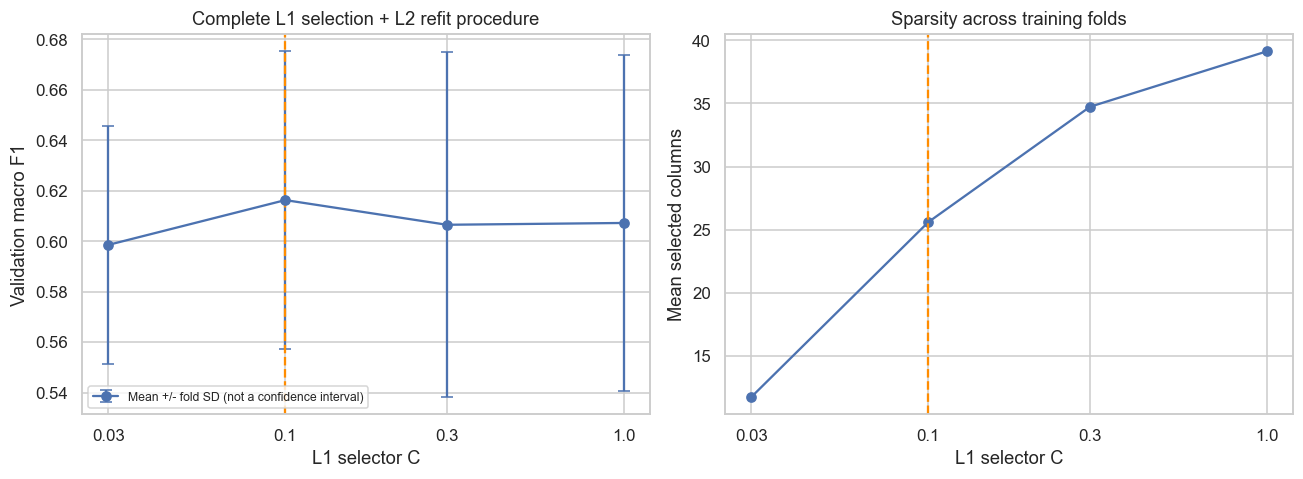

In [84]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].errorbar(
    selector_sensitivity_summary.index,
    selector_sensitivity_summary["F1_macro_medio"],
    yerr=selector_sensitivity_summary["F1_macro_desvio_padrao"],
    marker="o",
    capsize=4,
    label="Mean +/- fold SD (not a confidence interval)",
)
axes[0].set(
    xscale="log",
    xlabel="L1 selector C",
    ylabel="Validation macro F1",
    title="Complete L1 selection + L2 refit procedure",
)
axes[0].legend(fontsize=8)
axes[1].plot(
    selector_sensitivity_summary.index, selector_sensitivity_summary["Colunas_media"], marker="o"
)
axes[1].set(
    xscale="log",
    xlabel="L1 selector C",
    ylabel="Mean selected columns",
    title="Sparsity across training folds",
)
for ax in axes:
    ax.axvline(best_selector_C, color="darkorange", linestyle="--")
    ax.set_xticks(SELECTOR_C_VALUES, labels=[str(value) for value in SELECTOR_C_VALUES])
plt.tight_layout()
plt.show()


In [85]:
selected_C_row = selector_sensitivity_summary.loc[best_selector_C]
original_C_row = selector_sensitivity_summary.loc[0.1]
selector_f1_paired = selector_sensitivity_folds.pivot(
    index="Fold", columns="Selector_C", values="F1_macro"
)
selector_C_delta = selector_f1_paired[best_selector_C] - selector_f1_paired[0.1]
selector_C_better_folds = int((selector_C_delta > 1e-8).sum())
display(
    Markdown(
        f'Training CV selects **C={best_selector_C:g}**, with mean macro F1 **{selected_C_row["F1_macro_medio"]:.4f}**, '
        f'SD {selected_C_row["F1_macro_desvio_padrao"]:.4f}, and {selected_C_row["Colunas_media"]:.1f} '
        f'columns on average ({selected_C_row["Colunas_min"]:.0f}–{selected_C_row["Colunas_max"]:.0f}). '
        f'The original C=0.1 gives {original_C_row["F1_macro_medio"]:.4f}; the paired mean difference is '
        f"{selector_C_delta.mean():+.4f}, with improvement in {selector_C_better_folds}/15 evaluations. "
        "This concerns the small tested grid, not a global optimum or statistical superiority. "
        "The value is fixed before new test evaluation."
    )
)


Training CV selects **C=0.1**, with mean macro F1 **0.6163**, SD 0.0590, and 25.6 columns on average (24–30). The original C=0.1 gives 0.6163; the paired mean difference is +0.0000, with improvement in 0/15 evaluations. This concerns the small tested grid, not a global optimum or statistical superiority. The value is fixed before new test evaluation.

### 6.3 Reduced Feature Sets

Full L2 is compared with L2 refitted on two reduced sets. All final fits use nominal C=1,
alpha=0.50 weights, identical standardisation and the same folds. Full L1 at C=1 is a reference.

- **L1 selection:** `best_selector_C`, chosen above, retains columns with any class coefficient
  above 0.0001 in absolute value; L2 is then refitted with C=1.
- **L2-based selection:** an L2 fit at C=1 ranks columns by their coefficient norm across classes.
  The top 50% are retained before L2 refitting. This is a heuristic added to L2, not automatic sparsity.

Categories, scales, weights and columns are learned within each fold. Empty selections give
an intercept-only model. Selecting a dummy does not retain every category of its original feature.
These CV means are reused after tuning and remain exploratory.


The next comparison reuses reference fits from section 6.1 and the selected L1 procedure
from section 6.2 for each matching fold. Only the L2 top50% refit requires a new fit here.
The shared functions above keep class weights, convergence handling and score definitions identical.


In [86]:
def selection_result(method, fold, model, columns, validation_data, validation_labels):
    columns = list(columns)
    return {
        "Metodo": method,
        "Fold": fold,
        "C": FINAL_C,
        "Colunas_entrada": len(columns),
        "Colunas_ativas": len(active_feature_names(model, pd.Index(columns))) if columns else 0,
        **classification_scores(validation_labels, model.predict(validation_data)),
    }


In [87]:
def compare_feature_sets(fold, fold_data):
    fit_data, validation_data, fit_labels, validation_labels = fold_data
    references = reference_models_by_fold[fold]
    rows = [
        selection_result(
            name, fold, references[name], fit_data.columns, validation_data, validation_labels
        )
        for name in ["L2 completo", "L1 completo"]
    ]
    importance = np.linalg.norm(references["L2 completo"].coef_, axis=0)
    ranking = np.argsort(-importance, kind="stable")
    n_keep = int(np.ceil(fit_data.shape[1] * 0.50))
    l2_columns = fit_data.columns[ranking[:n_keep]].tolist()
    subset_fit, subset_validation = model_subset(fit_data, validation_data, l2_columns)
    l2_result = {
        "model": fit_regularised_logistic(subset_fit, fit_labels, "l2", FINAL_C),
        "columns": l2_columns,
        "validation_data": subset_validation,
    }
    l1_result = selector_evaluations[fold, best_selector_C]
    subsets = [("L2 subset L1", l1_result), ("L2 subset L2 top50%", l2_result)]
    selected_columns = []
    for name, result in subsets:
        rows.append(
            selection_result(
                name,
                fold,
                result["model"],
                result["columns"],
                result["validation_data"],
                validation_labels,
            )
        )
        selected_columns.append({"Metodo": name, "Fold": fold, "Colunas": result["columns"].copy()})
    return rows, selected_columns


In [88]:
selection_rows = []
selection_columns = []
for fold, fold_data in enumerate(regularisation_folds, 1):
    rows, columns = compare_feature_sets(fold, fold_data)
    selection_rows.extend(rows)
    selection_columns.extend(columns)
    print(f"Feature-set comparison: fold {fold}/{len(regularisation_folds)}")


Feature-set comparison: fold 1/15
Feature-set comparison: fold 2/15
Feature-set comparison: fold 3/15
Feature-set comparison: fold 4/15
Feature-set comparison: fold 5/15
Feature-set comparison: fold 6/15
Feature-set comparison: fold 7/15
Feature-set comparison: fold 8/15
Feature-set comparison: fold 9/15
Feature-set comparison: fold 10/15
Feature-set comparison: fold 11/15
Feature-set comparison: fold 12/15
Feature-set comparison: fold 13/15
Feature-set comparison: fold 14/15
Feature-set comparison: fold 15/15


In [89]:
selection_fold_results = pd.DataFrame(selection_rows)
selection_columns_by_fold = pd.DataFrame(selection_columns)
selection_summary = selection_fold_results.groupby("Metodo").agg(
    Accuracy_media=("Accuracy", "mean"),
    F1_macro_medio=("F1_macro", "mean"),
    F1_macro_desvio_padrao=("F1_macro", "std"),
    Colunas_entrada_media=("Colunas_entrada", "mean"),
    Colunas_entrada_min=("Colunas_entrada", "min"),
    Colunas_entrada_max=("Colunas_entrada", "max"),
    Colunas_ativas_media=("Colunas_ativas", "mean"),
    **CLASS_METRIC_AGG
)


In [90]:
selection_f1_by_fold = selection_fold_results.pivot(
    index="Fold", columns="Metodo", values="F1_macro"
)
selection_delta_by_fold = selection_f1_by_fold.subtract(selection_f1_by_fold["L2 completo"], axis=0)
selection_summary["Delta_F1_macro"] = selection_delta_by_fold.mean()
selection_summary["Folds_F1_superior_L2"] = (selection_delta_by_fold > 1e-8).sum()
display(selection_summary.round(4))
display(selection_delta_by_fold.drop(columns="L2 completo").round(4))


,Accuracy_media,F1_macro_medio,F1_macro_desvio_padrao,Colunas_entrada_media,Colunas_entrada_min,Colunas_entrada_max,Colunas_ativas_media,Precision_DI,Recall_DI,Precision_HT_HY,Recall_HT_HY,Precision_DI_HT_HY,Recall_DI_HT_HY,Delta_F1_macro,Folds_F1_superior_L2
Metodo,,,,,,,,,,,,,,,
L1 completo,0.8935,0.6057,0.0635,40.0,40,40,39.1333,0.9541,0.9335,0.5900,0.7521,0.2098,0.2282,-0.0016,6
L2 completo,0.8931,0.6073,0.0666,40.0,40,40,40.0000,0.9540,0.9328,0.5917,0.7484,0.2108,0.2381,0.0000,0
L2 subset L1,0.8935,0.6163,0.0590,25.6,24,30,25.6000,0.9560,0.9307,0.6129,0.7861,0.2088,0.2432,0.0091,8
L2 subset L2 top50%,0.8948,0.5982,0.0581,20.0,20,20,20.0000,0.9521,0.9360,0.6003,0.7715,0.1872,0.1788,-0.0091,5


Metodo,L1 completo,L2 subset L1,L2 subset L2 top50%
Fold,,,
1,0.0000,0.0592,0.0502
2,-0.0018,-0.0070,-0.0306
3,-0.0307,-0.0185,-0.0526
4,0.0055,0.0428,0.0241
5,-0.0069,-0.0297,-0.0422
6,0.0000,0.0088,0.0170
7,0.0000,0.0365,-0.0122
8,0.0024,0.0064,-0.0065
9,0.0052,-0.0063,-0.0904


### 6.4 Feature-Selection Results

This interpretation is calculated from the executed tables. The final L2 fit's C=1 is distinct
from the L1 selector C chosen in section 6.2.


In [91]:
selection_main = selection_summary.loc["L2 subset L1"]
selection_full = selection_summary.loc["L2 completo"]
selection_top50 = selection_summary.loc["L2 subset L2 top50%"]
display(
    Markdown(
        f"L1 selection at C={best_selector_C:g} followed by L2 at C=1 achieves mean macro F1 "
        f'**{selection_main["F1_macro_medio"]:.4f}**, versus {selection_full["F1_macro_medio"]:.4f} for full L2. '
        f'It uses **{selection_main["Colunas_entrada_media"]:.1f}** columns on average '
        f'({selection_main["Colunas_entrada_min"]:.0f}–{selection_main["Colunas_entrada_max"]:.0f}), '
        f'with improvement in {selection_main["Folds_F1_superior_L2"]:.0f}/15 paired evaluations. '
        f'DI_HT_HY recall is {selection_main["Recall_DI_HT_HY"]:.4f}.\n\n'
        f'L2 top50% uses 20 columns and obtains macro F1 {selection_top50["F1_macro_medio"]:.4f}. '
        "Its ranking is a heuristic added to L2. Zeros depend on coding, scaling, other columns and samples; "
        "they do not prove clinical irrelevance. Small differences on dependent folds establish neither superiority nor equivalence."
    )
)
assert np.isclose(selection_main["F1_macro_medio"], selected_C_row["F1_macro_medio"], atol=1e-12)


L1 selection at C=0.1 followed by L2 at C=1 achieves mean macro F1 **0.6163**, versus 0.6073 for full L2. It uses **25.6** columns on average (24–30), with improvement in 8/15 paired evaluations. DI_HT_HY recall is 0.2432.

L2 top50% uses 20 columns and obtains macro F1 0.5982. Its ranking is a heuristic added to L2. Zeros depend on coding, scaling, other columns and samples; they do not prove clinical irrelevance. Small differences on dependent folds establish neither superiority nor equivalence.

### 6.5 Consolidated Training-CV Comparison

These tables join principal candidates on the same 15 stratified CV splits. Column counts
refer to encoded inputs. The majority decision does not use features. The design table
identifies changes in features, scaling and weights; the metric table shows their observed
consequences. Simultaneously changing several factors does not isolate any one effect.


In [92]:
cv_overview_rows = []


def add_cv_overview(name, row, features, scaling, weights, columns):
    cv_overview_rows.append(
        {
            "Candidate": name,
            "Feature_set": features,
            "Scaling": scaling,
            "Weights": weights,
            "Mean_columns": columns,
            "F1_macro": row["F1_macro_medio"],
            "F1_SD": row["F1_macro_desvio_padrao"],
            "Recall_DI": row["Recall_DI"],
            "Recall_HT_HY": row["Recall_HT_HY"],
            "Recall_DI_HT_HY": row["Recall_DI_HT_HY"],
        }
    )


add_cv_overview(
    "Majority baseline",
    classification_cv_summary.loc["Baseline: classe mais frequente"],
    "Majority class",
    "None",
    "None",
    0,
)


In [93]:
add_cv_overview(
    "LDA, full",
    classification_exclusion_summary.loc[("LDA", "Todas as disponíveis")],
    "30 original features",
    "Numeric",
    "None",
    40,
)

add_cv_overview(
    "LDA, manual reduction",
    classification_exclusion_summary.loc[("LDA", "Sem as três")],
    "27 original features",
    "Numeric",
    "None",
    37,
)

add_cv_overview(
    "Logistic L2, manual reduction",
    classification_exclusion_summary.loc[("Regressão logística", "Sem as três")],
    "27 original features",
    "Numeric",
    "None",
    37,
)


In [94]:
add_cv_overview(
    "Weighted logistic L2, manual reduction",
    proportional_weight_summary.loc["alpha=0.50"],
    "27 original features",
    "Numeric",
    "alpha=0.50",
    37,
)

add_cv_overview(
    "Weighted L2, full", selection_full, "30 original features", "All columns", "alpha=0.50", 40
)

add_cv_overview(
    "Weighted L1, full",
    selection_summary.loc["L1 completo"],
    "30 original features",
    "All columns",
    "alpha=0.50",
    40,
)


In [95]:
add_cv_overview(
    "Weighted L2, L1 selection",
    selection_main,
    f"L1 selector C={best_selector_C:g}",
    "All columns",
    "alpha=0.50",
    selection_main["Colunas_entrada_media"],
)

add_cv_overview(
    "Weighted L2, L2 top50%", selection_top50, "L2-ranked columns", "All columns", "alpha=0.50", 20
)

classification_cv_overview = pd.DataFrame(cv_overview_rows).set_index("Candidate")

display(classification_cv_overview[["Feature_set", "Scaling", "Weights", "Mean_columns"]].round(2))

display(
    classification_cv_overview[
        ["F1_macro", "F1_SD", "Recall_DI", "Recall_HT_HY", "Recall_DI_HT_HY"]
    ].round(4)
)

selected_candidate_cv = classification_cv_overview["F1_macro"].idxmax()

print("Highest mean training-CV macro F1 among these candidates:", selected_candidate_cv)


,Feature_set,Scaling,Weights,Mean_columns
Candidate,,,,
Majority baseline,Majority class,None,None,0.0
"LDA, full",30 original features,Numeric,None,40.0
"LDA, manual reduction",27 original features,Numeric,None,37.0
"Logistic L2, manual reduction",27 original features,Numeric,None,37.0
"Weighted logistic L2, manual reduction",27 original features,Numeric,alpha=0.50,37.0
"Weighted L2, full",30 original features,All columns,alpha=0.50,40.0
"Weighted L1, full",30 original features,All columns,alpha=0.50,40.0
"Weighted L2, L1 selection",L1 selector C=0.1,All columns,alpha=0.50,25.6
"Weighted L2, L2 top50%",L2-ranked columns,All columns,alpha=0.50,20.0


,F1_macro,F1_SD,Recall_DI,Recall_HT_HY,Recall_DI_HT_HY
Candidate,,,,,
Majority baseline,0.3161,0.0003,1.0000,0.0000,0.0000
"LDA, full",0.5658,0.0309,0.9799,0.6438,0.0341
"LDA, manual reduction",0.5792,0.0399,0.9827,0.6662,0.0440
"Logistic L2, manual reduction",0.5761,0.0268,0.9898,0.6586,0.0242
"Weighted logistic L2, manual reduction",0.6048,0.0652,0.9381,0.7743,0.1938
"Weighted L2, full",0.6073,0.0666,0.9328,0.7484,0.2381
"Weighted L1, full",0.6057,0.0635,0.9335,0.7521,0.2282
"Weighted L2, L1 selection",0.6163,0.0590,0.9307,0.7861,0.2432
"Weighted L2, L2 top50%",0.5982,0.0581,0.9360,0.7715,0.1788


Highest mean training-CV macro F1 among these candidates: Weighted L2, L1 selection


Full-versus-selected L2 keeps scaling, weights, final C and folds fixed. Manual weighting
comparisons keep features and numeric-only scaling fixed. Comparing LDA with the final
logistic procedure changes several factors and assesses whole candidates. The best selected
mean and its SD do not independently evaluate the entire exploratory selection process.
The L1-selected L2 candidate is retained by training-CV macro F1, not by test accuracy.


## 7. Classification Test-Set Evaluation

Selected procedures are refitted on all 1,600 training patients and evaluated on the original 400 test patients without revising features, weights, or selection rules.

The comparison includes the majority baseline, manually reduced LDA, full L2 logistic regression, and L2 with L1 selection. Both logistic models use nominal `C=1`, all-column standardisation, and normalised `alpha=0.50` weights. The L1 selector is refitted with `best_selector_C`, fixed by section 6.2, on training data only. The setting is not revised after these test results.

LDA is a separate reference with different preprocessing and weighting, so it does not isolate regularisation effects. Weights, selected columns, class metrics, and confusion matrices are reported. Prior test inspection and global EDA keep this evaluation exploratory.


In [96]:
from sklearn.metrics import ConfusionMatrixDisplay

y_train_final = y_classification.loc[train_indices]
y_test_final = y_classification.loc[test_indices]
final_weights = normalised_class_weights(y_train_final)
X_train_final, X_test_final = prepare_features(train_indices, test_indices, scaling="all")


In [97]:
final_l2_complete = fit_regularised_logistic(
    X_train_final, y_train_final, "l2", FINAL_C, final_weights
)
final_l1_selector = fit_regularised_logistic(
    X_train_final, y_train_final, "l1", best_selector_C, final_weights
)
final_selected_columns = active_feature_names(final_l1_selector, X_train_final.columns)
final_selected_mask = X_train_final.columns.isin(final_selected_columns)
X_train_selected, X_test_selected = model_subset(
    X_train_final, X_test_final, final_selected_columns
)
final_l2_selected = fit_regularised_logistic(
    X_train_selected, y_train_final, "l2", FINAL_C, final_weights
)


In [98]:
final_lda_features = [
    name
    for name in X_available.columns
    if name not in ["low_hdl_cholesterol", "plasma_value", "ldl_alternative"]
]
X_train_lda_final, X_test_lda_final = prepare_features(
    train_indices, test_indices, features=final_lda_features, scaling="numeric"
)
final_lda = LinearDiscriminantAnalysis()
final_lda.fit(X_train_lda_final, y_train_final)
final_baseline = DummyClassifier(strategy="most_frequent")
final_baseline.fit(X_train_final, y_train_final)


,strategy,'most_frequent'
,random_state,None
,constant,None


In [99]:
final_classification_predictions = {
    "Baseline: classe mais frequente": final_baseline.predict(X_test_final),
    "LDA: redução manual": final_lda.predict(X_test_lda_final),
    "L2 completo": final_l2_complete.predict(X_test_final),
    "L2 subset L1": final_l2_selected.predict(X_test_selected),
}
final_input_columns = {
    "Baseline: classe mais frequente": 0,
    "LDA: redução manual": X_train_lda_final.shape[1],
    "L2 completo": X_train_final.shape[1],
    "L2 subset L1": len(final_selected_columns),
}


In [100]:
final_test_rows = [
    {
        "Modelo": name,
        "Colunas_entrada": final_input_columns[name],
        **classification_scores(y_test_final, predictions, include_class_f1=True),
    }
    for name, predictions in final_classification_predictions.items()
]
final_classification_test_results = pd.DataFrame(final_test_rows).set_index("Modelo")
print("Resultados no teste:")
display(final_classification_test_results.round(4))


Resultados no teste:


,Colunas_entrada,Accuracy,F1_macro,Precision_DI,Recall_DI,F1_DI,Precision_HT_HY,Recall_HT_HY,F1_HT_HY,Precision_DI_HT_HY,Recall_DI_HT_HY,F1_DI_HT_HY
Modelo,,,,,,,,,,,,
Baseline: classe mais frequente,0,0.8950,0.3149,0.8950,1.0000,0.9446,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
LDA: redução manual,37,0.9150,0.5859,0.9243,0.9888,0.9555,0.7857,0.6875,0.7333,0.3333,0.0385,0.0690
L2 completo,40,0.8725,0.5981,0.9328,0.9302,0.9315,0.6667,0.7500,0.7059,0.1600,0.1538,0.1569
L2 subset L1,26,0.8750,0.5996,0.9330,0.9330,0.9330,0.6667,0.7500,0.7059,0.1667,0.1538,0.1600


In [101]:
print("Composição do teste (não usada para calcular pesos):")
display(y_test_final.value_counts().reindex(CLASS_ORDER).rename("Pacientes"))
print("Pesos normalizados aprendidos no treino, alpha=0,50:")
display(pd.Series(final_weights, name="Peso").reindex(CLASS_ORDER).round(4))


Composição do teste (não usada para calcular pesos):


target_class
DI          358
HT_HY        16
DI_HT_HY     26
Name: Pacientes, dtype: int64

Pesos normalizados aprendidos no treino, alpha=0,50:


DI          0.7566
HT_HY       3.0467
DI_HT_HY    3.4855
Name: Peso, dtype: float64

In [102]:
final_column_selection = pd.DataFrame(
    {"Coluna": X_train_final.columns, "Selecionada_L1": final_selected_mask}
)
print(f"Colunas conservadas pelo seletor L1: {len(final_selected_columns)}")
display(final_column_selection.loc[final_column_selection["Selecionada_L1"]])
print("Colunas não selecionadas:")
display(final_column_selection.loc[~final_column_selection["Selecionada_L1"]])


Colunas conservadas pelo seletor L1: 26


,Coluna,Selecionada_L1
0,age,True
1,bmi,True
2,HbA1c_level,True
3,cholesterol,True
5,triglycerides,True
6,blood_pressure,True
7,crp_level,True
8,homocysteine_level,True
14,hdl,True
18,age_level_Middle,True


Colunas não selecionadas:


,Coluna,Selecionada_L1
4,sleep_hours,False
9,systolic_bp,False
10,diastolic_bp,False
11,alcohol_intake,False
12,salt_intake,False
13,heart_rate,False
15,ldl,False
16,plasma_value,False
17,ldl_alternative,False
20,age_level_Young,False


In [103]:
cv_to_test_names = {
    "Baseline: classe mais frequente": "Majority baseline",
    "LDA: redução manual": "LDA, manual reduction",
    "L2 completo": "Weighted L2, full",
    "L2 subset L1": "Weighted L2, L1 selection",
}
final_comparison_rows = []
for test_name, cv_name in cv_to_test_names.items():
    test_row = final_classification_test_results.loc[test_name]
    cv_row = classification_cv_overview.loc[cv_name]
    final_comparison_rows.append(
        {
            "Candidate": test_name,
            "Final_columns": test_row["Colunas_entrada"],
            "CV_F1_macro_mean": cv_row["F1_macro"],
            "Test_F1_macro": test_row["F1_macro"],
            "Test_accuracy": test_row["Accuracy"],
            "Test_recall_DI_HT_HY": test_row["Recall_DI_HT_HY"],
        }
    )
final_cv_test_comparison = pd.DataFrame(final_comparison_rows).set_index("Candidate")
display(final_cv_test_comparison.round(4))
print("Final L1 selector C fixed before test evaluation:", best_selector_C)


,Final_columns,CV_F1_macro_mean,Test_F1_macro,Test_accuracy,Test_recall_DI_HT_HY
Candidate,,,,,
Baseline: classe mais frequente,0.0,0.3161,0.3149,0.8950,0.0000
LDA: redução manual,37.0,0.5792,0.5859,0.9150,0.0385
L2 completo,40.0,0.6073,0.5981,0.8725,0.1538
L2 subset L1,26.0,0.6163,0.5996,0.8750,0.1538


Final L1 selector C fixed before test evaluation: 0.1


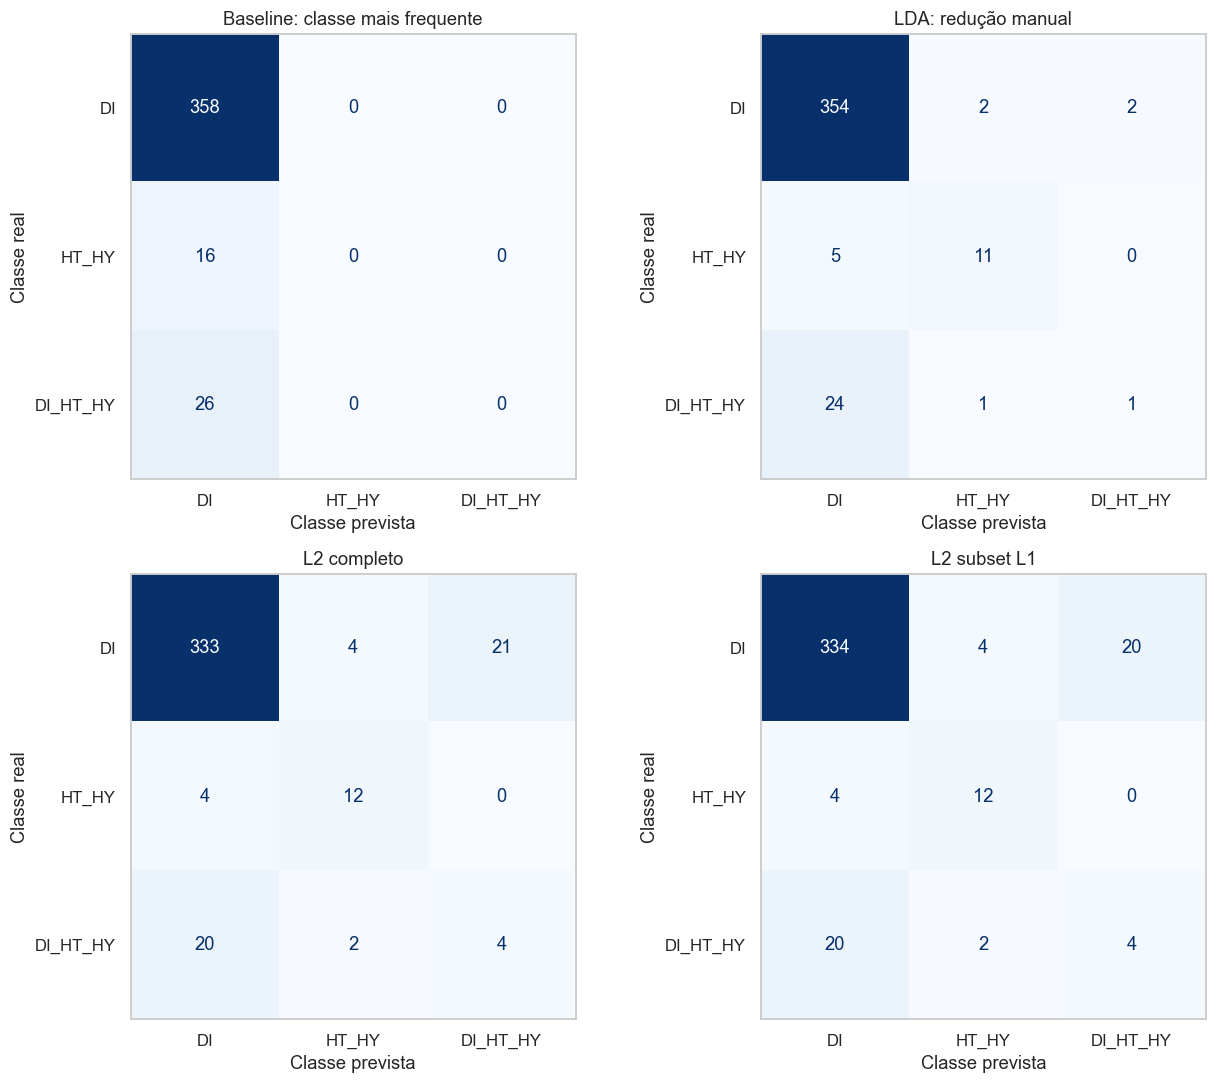

In [104]:
# Matrizes de confusão no teste

fig, axes = plt.subplots(2, 2, figsize=(12, 10))
for ax, (model_name, predictions) in zip(axes.ravel(), final_classification_predictions.items()):
    ConfusionMatrixDisplay.from_predictions(
        y_test_final,
        predictions,
        labels=CLASS_ORDER,
        display_labels=CLASS_ORDER,
        cmap="Blues",
        colorbar=False,
        ax=ax,
        values_format="d",
    )
    ax.set_title(model_name)
    ax.set_xlabel("Classe prevista")
    ax.set_ylabel("Classe real")
    ax.grid(False)
plt.tight_layout()
plt.show()


### 7.1 Test Results

Confusion-matrix rows are actual classes and columns are predictions. The following interpretation
uses executed predictions. This test is exploratory because it was inspected before the revision.
New selector C is chosen by training CV, not by comparing old and new test outcomes.


In [105]:
selected_test = final_classification_test_results.loc["L2 subset L1"]
full_test = final_classification_test_results.loc["L2 completo"]
lda_test = final_classification_test_results.loc["LDA: redução manual"]
selected_confusion = confusion_matrix(
    y_test_final, final_classification_predictions["L2 subset L1"], labels=CLASS_ORDER
)
selected_correct = np.diag(selected_confusion)
selected_support = selected_confusion.sum(axis=1)
selected_false_positives = selected_confusion.sum(axis=0) - selected_correct
selected_false_negatives = selected_support - selected_correct
final_reduction_percent = 100 * (1 - len(final_selected_columns) / X_train_final.shape[1])


In [106]:
display(
    Markdown(
        f'**Manually reduced LDA** gives accuracy {lda_test["Accuracy"]:.4f}, macro F1 '
        f'{lda_test["F1_macro"]:.4f} and DI_HT_HY recall {lda_test["Recall_DI_HT_HY"]:.4f}.\n\n'
    )
)


**Manually reduced LDA** gives accuracy 0.9150, macro F1 0.5859 and DI_HT_HY recall 0.0385.



In [107]:
display(
    Markdown(
        f"**L1-selected L2**, selector C={best_selector_C:g}, retains {len(final_selected_columns)} "
        f"of {X_train_final.shape[1]} columns ({final_reduction_percent:.1f}% reduction), "
        f'with accuracy {selected_test["Accuracy"]:.4f} and macro F1 **{selected_test["F1_macro"]:.4f}**. '
        f"It recognises {selected_correct[0]}/{selected_support[0]} DI, "
        f"{selected_correct[1]}/{selected_support[1]} HT_HY and "
        f"{selected_correct[2]}/{selected_support[2]} DI_HT_HY patients. "
        f"For DI_HT_HY it misses {selected_false_negatives[2]} cases and produces "
        f"{selected_false_positives[2]} false positives, with precision "
        f'{selected_test["Precision_DI_HT_HY"]:.4f} and recall {selected_test["Recall_DI_HT_HY"]:.4f}.\n\n'
    )
)


**L1-selected L2**, selector C=0.1, retains 26 of 40 columns (35.0% reduction), with accuracy 0.8750 and macro F1 **0.5996**. It recognises 334/358 DI, 12/16 HT_HY and 4/26 DI_HT_HY patients. For DI_HT_HY it misses 22 cases and produces 20 false positives, with precision 0.1667 and recall 0.1538.



In [108]:
display(
    Markdown(
        f'**Full L2** gives macro F1 {full_test["F1_macro"]:.4f}; selected-minus-full is '
        f'{selected_test["F1_macro"]-full_test["F1_macro"]:+.4f}. '
        "A small observed difference establishes neither meaningful improvement nor equivalence. "
        "Only the two L2 procedures isolate selection. One additional correct patient changes "
        "HT_HY recall by 6.25 percentage points and DI_HT_HY recall by about 3.85 points. "
        "No setting is changed in response to these test scores."
    )
)


**Full L2** gives macro F1 0.5981; selected-minus-full is +0.0015. A small observed difference establishes neither meaningful improvement nor equivalence. Only the two L2 procedures isolate selection. One additional correct patient changes HT_HY recall by 6.25 percentage points and DI_HT_HY recall by about 3.85 points. No setting is changed in response to these test scores.

## 8. Conclusions and Limitations

### 8.1 Evidence and Model Choice

This summary uses executed results so that parameter choices, counts and performance claims
remain consistent with the new selector comparison.


In [109]:
regression_baseline_test = test_results.loc["Baseline: média do treino"]
regression_simple_test = test_results.loc[f"Simples: {best_feature}"]
regression_multiple_test = test_results.loc["Múltipla: conjunto selecionado"]
regression_rmse_gain = 100 * (
    1 - regression_multiple_test["RMSE"] / regression_baseline_test["RMSE"]
)


In [110]:
display(
    Markdown(
        f"- **Data:** all 2,000 patients are retained: 1,600 train and 400 test. Thirty candidate "
        f"features yield 40 encoded columns. One conditional Friedewald estimate is not calculated; no patient is excluded.\n"
    )
)


- **Data:** all 2,000 patients are retained: 1,600 train and 400 test. Thirty candidate features yield 40 encoded columns. One conditional Friedewald estimate is not calculated; no patient is excluded.


In [111]:
display(
    Markdown(
        f"- **Regression:** {best_feature} is selected by training-CV RMSE. Its test RMSE is "
        f'{regression_simple_test["RMSE"]:.4f}. Selected multiple regression gives '
        f'{regression_multiple_test["RMSE"]:.4f}, {regression_rmse_gain:.2f}% below baseline, '
        f'with R² {regression_multiple_test["R2"]:.4f}. Simple MAE is '
        f'{regression_simple_test["MAE"]:.4f}, versus {regression_multiple_test["MAE"]:.4f} for multiple. '
        f"Multiple is preferred by RMSE, not every metric.\n"
    )
)


- **Regression:** bmi is selected by training-CV RMSE. Its test RMSE is 48.6671. Selected multiple regression gives 47.7733, 2.99% below baseline, with R² 0.0570. Simple MAE is 37.1257, versus 37.2831 for multiple. Multiple is preferred by RMSE, not every metric.


In [112]:
display(
    Markdown(
        f"- **LDA and resampling:** LDA and logistic regression exceed majority macro F1; rankings vary "
        f"across resampling methods. Illustrated training variance ratios of {ratio_min:.0f}–{ratio_max:.0f} "
        f"poorly support common covariance, without proving that this causes minority errors.\n"
    )
)


- **LDA and resampling:** LDA and logistic regression exceed majority macro F1; rankings vary across resampling methods. Illustrated training variance ratios of 710–1858 poorly support common covariance, without proving that this causes minority errors.


In [113]:
display(
    Markdown(
        f"- **Weights:** on manually reduced features, alpha=0.50 raises mean CV macro F1 from "
        f'{proportional_weight_summary.loc["Sem pesos","F1_macro_medio"]:.4f} to '
        f'{proportional_weight_summary.loc["alpha=0.50","F1_macro_medio"]:.4f}. Additional false positives '
        f"and lower DI recall are part of this empirical compromise, which is not a clinical cost model.\n"
    )
)


- **Weights:** on manually reduced features, alpha=0.50 raises mean CV macro F1 from 0.5761 to 0.6048. Additional false positives and lower DI recall are part of this empirical compromise, which is not a clinical cost model.


In [114]:
display(
    Markdown(
        f"- **Selected classifier:** training CV chooses L1 selector C={best_selector_C:g}, followed by "
        f"L2 at nominal C=1 with normalised alpha=0.50 weights. Mean CV macro F1 is "
        f'{selection_main["F1_macro_medio"]:.4f}. Final fitting retains {len(final_selected_columns)} '
        f"columns ({final_reduction_percent:.1f}% reduction); test macro F1 is "
        f'{selected_test["F1_macro"]:.4f}, versus {full_test["F1_macro"]:.4f} for full L2. '
        f"Selection simplifies the inputs; the comparison does not establish a general performance gain.\n"
    )
)


- **Selected classifier:** training CV chooses L1 selector C=0.1, followed by L2 at nominal C=1 with normalised alpha=0.50 weights. Mean CV macro F1 is 0.6163. Final fitting retains 26 columns (35.0% reduction); test macro F1 is 0.5996, versus 0.5981 for full L2. Selection simplifies the inputs; the comparison does not establish a general performance gain.


In [115]:
display(
    Markdown(
        f"- **Practical limit:** the candidate misses {selected_false_negatives[2]} of "
        f"{selected_support[2]} DI_HT_HY test patients and produces {selected_false_positives[2]} "
        f"false positives for this class. Clinical suitability is not demonstrated."
    )
)


- **Practical limit:** the candidate misses 22 of 26 DI_HT_HY test patients and produces 20 false positives for this class. Clinical suitability is not demonstrated.

### 8.2 Limits of the Evidence

- Global EDA and historical test inspection prevent independent final validation.
- Features, weights and selector C use the same training data and CV, so selected means may be optimistic.
- Overlapping folds, repetitions and bootstrap samples give descriptive SDs, not independent confidence intervals.
- Residual patterns warrant caution about the linear specification; no unverified assumption is declared satisfied.
- Small minority counts limit stability. LDA's covariance mismatch is a limitation, not an established cause of its errors.
- Incomplete units and definitions limit clinical consistency checks and do not justify reconstructing values or deleting patients.
- Coefficients and exclusions depend on coding, scales, other features and samples; they establish neither causality nor clinical irrelevance.

Further work could assess selection stability across training samples and seek genuinely new test
data. A well-supported limited result still answers the assignment. The exploratory C comparison
is not used to disguise deterioration on the already observed test.


## 9. References and Authorship

### 9.1 Assignment and Teaching Materials

Filenames identify the supplied course resources. They are not presented as repository links,
because the teaching files are not distributed with this repository.

- ISEP, APRAU 2026/2027 assignment v1.0, `Trabalho_APRAU_2026_27_step1 (1).pdf`, PDF pp. 2–4: project and submission requirements.
- Week 1: `Python for Data Analysis_Lab.ipynb`, `PL1_APRAU_Intro_Python_Lab.ipynb`, `TP1_APRAU_Machine Learning in Python.ipynb`: data manipulation, EDA and supervised learning.
- Week 2: `T2_LinearRegression_v0.pdf`, especially PDF p. 26; `TP2_solutions.ipynb` and `PL_Aula2.ipynb`: least squares, residuals, regression comparisons and coding.
- Week 3: `T3_Classification_RL_LDA.pdf`, especially PDF pp. 30–31; `ClassificationMetrics.pdf`, `TP3.ipynb` and `PL3_LR_LDA_and_QDA.ipynb`: LDA assumptions, logistic regression and metrics.
- Week 4: `T4_EvaluationResampling.pdf`, especially PDF pp. 29–30 and 44–45; `TP4_Cross_validation_solutions.ipynb`, `aula_T_Resampling_Python.ipynb` and `Bootstrap_by_Hand.ipynb`: validation/test separation, CV, LOOCV and bootstrap OOB.
- Week 5: `T5_RidgeLasso.pdf`, especially PDF pp. 40–44; `TP5_Ridge_Lasso_Elasticnet.ipynb`, including cells 48 and 50: regularised logistic regression, coefficient activity and C versus penalty strength.

### 9.2 Library and Clinical Diagnostic References

- [scikit-learn 1.7 linear models](https://scikit-learn.org/1.7/modules/linear_model.html).
- [scikit-learn 1.7 LDA/QDA](https://scikit-learn.org/1.7/modules/lda_qda.html).
- [scikit-learn 1.7 cross-validation](https://scikit-learn.org/1.7/modules/cross_validation.html) and [metrics](https://scikit-learn.org/1.7/modules/model_evaluation.html).
- Friedewald, W. T., Levy, R. I., and Fredrickson, D. S. (1972). Estimation of the concentration of low-density lipoprotein cholesterol in plasma, without use of the preparative ultracentrifuge. Clinical Chemistry, 18(6), 499–502.
- Chemla, D., et al. (2002). Empirical estimates of mean aortic pressure: advantages, drawbacks and implications for pressure redundancy. Clinical Science, 103(1), 7–13.

Clinical formulas are auxiliary checks under conditional assumptions. References do not confirm dataset units or construction rules.

### 9.3 Adaptations and AI Assistance

Fold-specific preparation, partial frequency weights and normalisation, the equivalent SAGA
weight/C reparameterisation, the selector grid, multiclass coefficient activity and L2 top50%
are project adaptations, not claimed transcriptions of teaching examples. No nested CV,
covariance shrinkage, adjusted LDA priors or QDA is added in this revision.

AI assistance (Codex) supported development, review, organisation, checking and writing.
Francisco Primavera and Pedro Fonseca remain responsible for understanding and validating the work.

### 9.4 Submission Checks

Confirm individual contributions, approval of the two-person group and sharing with the PL teacher.
ZIP naming requires teacher acronym, class and student numbers. Those administrative details
cannot be inferred from execution. If this revision is submitted, supporting report claims must
match its chosen C and results. The original report has not been rewritten.


## 10. Numerical Consistency Checks

These checks cover the retained reference metrics, independent least squares, confusion-matrix
macro F1 and consistency of selected settings. They do not certify clinical validity or repair test consultation.


In [116]:
assert len(train_indices) == 1600 and len(test_indices) == 400

assert set(train_indices).isdisjoint(test_indices)

assert len(X_available.columns) == 30 and X_train_final.shape[1] == 40

assert not any(name in X_available.columns for name in ["target_class", "target_regression"])

assert int(clinical_relations["ldl_friedewald"].isna().sum()) == int((~friedewald_eligible).sum())

assert len(selector_sensitivity_folds) == len(SELECTOR_C_VALUES) * len(classification_splits)

assert best_selector_C in SELECTOR_C_VALUES

assert np.isclose(
    selection_main["F1_macro_medio"],
    selector_sensitivity_summary.loc[best_selector_C, "F1_macro_medio"],
)

assert selected_candidate_cv == "Weighted L2, L1 selection"

check_y_train = y_regression.loc[train_indices].to_numpy()

check_x = X_available.loc[train_indices, best_feature].to_numpy()


In [117]:
check_slope = np.sum((check_x - check_x.mean()) * (check_y_train - check_y_train.mean())) / np.sum(
    (check_x - check_x.mean()) ** 2
)

check_intercept = check_y_train.mean() - check_slope * check_x.mean()

np.testing.assert_allclose(
    simple_predictions,
    check_intercept + check_slope * X_available.loc[test_indices, best_feature].to_numpy(),
    atol=1e-9,
    rtol=0,
)

check_design = np.column_stack([np.ones(len(X_train_multiple)), X_train_multiple.to_numpy()])

check_coefficients = np.linalg.lstsq(check_design, check_y_train, rcond=None)[0]

check_evaluation_design = np.column_stack(
    [np.ones(len(X_test_multiple)), X_test_multiple.to_numpy()]
)

np.testing.assert_allclose(
    multiple_predictions, check_evaluation_design @ check_coefficients, atol=1e-8, rtol=0
)


In [118]:
np.testing.assert_allclose(
    test_results["RMSE"],
    [49.24329326162092, 48.6670730304452, 47.773261751268066],
    atol=1e-5,
    rtol=0,
)

for name, predictions in final_classification_predictions.items():
    matrix = confusion_matrix(y_test_final, predictions, labels=CLASS_ORDER)
    true_positive = np.diag(matrix)
    denominator = matrix.sum(axis=0) + matrix.sum(axis=1)
    independent_f1 = np.divide(
        2 * true_positive, denominator, out=np.zeros(3), where=denominator != 0
    ).mean()
    assert np.isclose(independent_f1, final_classification_test_results.loc[name, "F1_macro"])

print(
    "PASS: partitions, features, formula domain, selector CV, independent least squares and macro F1."
)


PASS: partitions, features, formula domain, selector CV, independent least squares and macro F1.
